## Ficha técnica del análisis

**Análisis:** Análisis cuantitativo integral de la seguridad digital  
**Autor:** Adriana del Pilar Noguera Torres  
**Fecha de elaboración:** Octubre de 2026  
**Versión:** 1.0  

---

### Fuente de información
- **Dataset:** `SurveyResponses_DigitalSecurityAroundTheWorld.csv`
- **Dimensiones:** 12.351 registros y 248 variables.
- **Documentación complementaria:** Data Map oficial y documento del problema analítico rector.

### Características del desarrollo
- **Entorno:** Python – Jupyter Notebook.
- **Enfoque:** Análisis estadístico y aprendizaje automático.
- **Contenido:** Análisis exploratorio, evaluación estadística y modelamiento predictivo.

### Condiciones de uso
- **Licencia del código:** MIT.
- **Licencia de los datos:** Sujeta a las condiciones establecidas por los autores del dataset.

# Análisis cuantitativo integral de la exploración

Se desarrolla una exploración cuantitativa de la base **Digital Security Perceptions & Practices in 12 Countries**. El conjunto de datos contiene respuestas de personas de doce países y permite estudiar dimensiones relacionadas con el conocimiento declarado, las percepciones y las prácticas de seguridad digital.

## Pregunta analítica rectora

**¿Qué explica las diferencias entre poblaciones en su conocimiento, percepción y comportamiento de seguridad digital, y qué tan grandes son esas diferencias?**

## Entorno y librerías

La siguiente celda importa las librerías para manipulación de datos, visualización y análisis estadístico. Algunas se utilizarán en etapas posteriores del trabajo.

Este análisis examina patrones de conocimiento, preocupación, percepción del riesgo y adopción de medidas de protección frente a la seguridad digital, utilizando la base de datos *SurveyResponses_DigitalSecurityAroundTheWorld*. El propósito es identificar relaciones entre estas dimensiones y comprender qué factores se asocian con el conocimiento sobre seguridad digital y la experiencia práctica en tecnologías de información (TI). El análisis se desarrolló mediante estadística descriptiva, comparación de grupos, regresión lineal múltiple y regresión logística binaria.

La exploración permitió identificar variables relacionadas con el conocimiento, las medidas de protección, la preocupación, la importancia atribuida a los datos y el riesgo percibido. Para los 12.263 casos completos utilizados en el modelo lineal, el índice de conocimiento presentó una media de 3,208 (DE = 0,836), mientras que el índice de protección registró una media de 5,119 (DE = 2,837), en un rango observado de 0 a 13. El índice de preocupación tuvo una media de 3,953 (DE = 0,879), y el de importancia de los datos, de 4,371 (DE = 0,685). Estos resultados describen la distribución de las variables analizadas, pero no constituyen por sí mismos evidencia de relaciones causales.

En la comparación de grupos correspondiente a la semana 6, se evaluaron diferencias mediante pruebas estadísticas seleccionadas según las características de las variables y los supuestos pertinentes. **La síntesis definitiva de esta sección debe incorporar las diferencias observadas, los valores de las pruebas, los tamaños del efecto y sus intervalos de confianza del 95 % obtenidos en el notebook**, para determinar tanto la significancia estadística como la relevancia práctica de los resultados.

La regresión lineal múltiple, estimada mediante mínimos cuadrados ordinarios, utilizó el índice de conocimiento como variable dependiente y los índices de protección, preocupación, importancia de los datos y riesgo percibido como predictores. El modelo incluyó 12.263 observaciones y obtuvo un \(R^2\) ajustado de 0,265, por lo que explicó aproximadamente el 26,5 % de la variabilidad observada en el índice de conocimiento. El índice de protección presentó una asociación positiva (β = 0,1423; p < 0,001), al igual que el riesgo percibido (β = 0,1459; p < 0,001). Por el contrario, la preocupación mostró una asociación negativa (β = −0,0559; p < 0,001). La importancia atribuida a los datos no presentó una asociación estadísticamente significativa al controlar los demás predictores (β = −0,0088; p = 0,414).

Los diagnósticos identificaron evidencia de heterocedasticidad mediante la prueba de Breusch–Pagan (p < 0,001), por lo que se estimaron errores estándar robustos HC3. Asimismo, los factores de inflación de la varianza mostraron posibles problemas de multicolinealidad, especialmente para los índices de preocupación, importancia de los datos y riesgo percibido. La distancia de Cook identificó observaciones que superaron el umbral exploratorio de \(4/n\). Estos resultados requieren cautela al interpretar los coeficientes y valorar la estabilidad del modelo.

La regresión logística binaria examinó la experiencia práctica en TI como variable dependiente, codificada en las categorías «Sí» y «No», utilizando como predictores el país, el índice de conocimiento, el índice de protección y el índice de preocupación. El modelo se estimó con 11.991 observaciones válidas. El índice de conocimiento se asoció con mayores odds de reportar experiencia en TI (OR = 2,429; IC del 95 %: 2,284–2,583), mientras que el índice de protección también presentó una asociación positiva (OR = 1,059; IC del 95 %: 1,041–1,077). La preocupación mostró una asociación negativa (OR = 0,932; IC del 95 %: 0,886–0,981). El modelo alcanzó una exactitud de clasificación del 71,4 %, una precisión de 65,4 % y una sensibilidad (*recall*) de 52,7 %, con un pseudo-\(R^2\) de McFadden de 0,1676. Estas métricas sugieren una capacidad de clasificación moderada y evidencian que el modelo no identifica todos los casos con experiencia en TI.

Los resultados muestran asociaciones estadísticas entre el conocimiento, las medidas de protección, la preocupación y la experiencia práctica en TI. Sin embargo, el carácter transversal de la encuesta, el uso de variables autorreportadas, la posible multicolinealidad y las limitaciones de los modelos impiden establecer causalidad. Los hallazgos deben interpretarse como evidencia asociativa dentro de la muestra analizada, no como prueba directa de la eficacia real de las prácticas de seguridad digital.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Bibliotecas cargadas correctamente")


Bibliotecas cargadas correctamente


## 1. Carga de la base de datos

Leer el archivo CSV en un DataFrame y verificar las dimensiones de la base.

**Procedimiento.** Se utiliza `pd.read_csv()` con `low_memory=False`, lo que ayuda a evitar inferencias de tipos inconsistentes en archivos con muchas columnas.

In [2]:
# 2. Cargar la base de datos

archivo = "SurveyResponses_DigitalSecurityAroundTheWorld.csv"

df = pd.read_csv(archivo, low_memory=False)

print("Base de datos cargada correctamente.")
print("Número de participantes:", df.shape[0])
print("Número de variables:", df.shape[1])


Base de datos cargada correctamente.
Número de participantes: 12351
Número de variables: 248


## 2. Verificación de los primeros registros

Examinar una muestra de filas para conocer la disposición general de las respuestas y comprobar que la lectura del CSV produjo una tabla interpretable. Para lo cual, el código `head()` muestra las primeras cinco filas de la base.

Los nombres de las columnas, los valores de ejemplo, la presencia de celdas vacías y si las variables parecen estar alineadas con sus encabezados.

In [3]:
# 3. Visualizar las primeras cinco filas

df.head()


,ID,Country,Gender,Gender_SelfDescription,Age,Education,Ethnicity,q1r1,q1r2,q1r3,q1r4,q1r5,q1r6,q1r7,q2r1,q2r2,q2r3,q3r1,q3r2,q3r3,q3r4,q3r5,q3r6,q3r7,q3r8,q3r9,q3r10,q3r11,q3r12,q3r13,q4r1,q4r2,q4r3,q4r4,q4r5,q4r6,q4r7,q4r8,q6r1,q6r2,q6r3,q6r4,q6r5,q6r6,q6r7,q6r8,q6r9,q6r10,q6r11,q6r12,q6r13,q6r14,q6r15,q6r16,q6r17,q6r18,q6r19,q6r20,q6r21,q6r22,q7r1,q7r2,q7r3,q7r4,q7r5,q7r6,q7r7,q7r8,q7r9,q8r2,q8r3,q8r4,q8r5,q8r6,q8r7,q8r8,q8r9,q8r10,q8r1,q8r10oer1,q9r1,q9r2,q9r3,q9r4,q9r5,q9r6,q9r7,q9r8,q9r9,q10r1,q10r2,q10r3,q10r4,q10r5,q11r1,q11r2,q11r3,q11r4,q11r5,q12r1,q12r2,q12r3,q12r4,q12r5,q12r6,q12r7,q12r8,q13r1,q13r2,q13r3,q13r4,q13r5,q13r6,q13r7,q13r8,q13r9,q13r10,q13r11,q13r12,q13r13,q13r14,q13r15,q13r16,q13r17,q13r18,q14r1,q14r2,q14r3,q14r4,q14r5,q14r6,q14r7,q14r8,q14r9,q15r1,q15r2,q15r3,q15r4,q15r5,q15r6,q15r7,q15r8,q15r9,q15r10,q15r11,q15r12,q15r13,q15r14,q15r15,q15r16,q16r1,q16r2,q16r3,q16r4,q16r5,q16r6,q17r1,q17r2,q17r3,q17r4,q17r5,q17r6,q17r7,q17r8,q17r9,q17r10,q17r11,q17r12,q17r13,q17r14,q17r15,q18ar1,q18ar2,q18ar3,q18ar4,q18ar5,q18ar6,q18ar7,q18ar8,q18br9,q18br10,q18br11,q18br12,q18br13,q18br14,q18br15,q18br16,q18br17,q18br18,q18br19,q19ar1,q19ar2,q19ar3,q19ar4,q19ar5,q19ar6,q19ar7,q19ar8,q19br9,q19br10,q19br11,q19br12,q19br13,q19br14,q19br15,q19br16,q19br17,q19br18,q19br19,q20r2,q20r3,q20r4,q20r5,q20r6,q20r7,q20r8,q20r9,q20r10,q20r11,q20r12,q20r13,q20r14,q20r1,q21r1,q21r2,q21r3,q21r4,q21r5,q21r6,q21r7,q21r8,q21r9,q21r10,q21r11,q21r12,q21r13,q21r14,q21r15,q22r1,q22r2,q22r3,q22r4,q22r5,q22r6,q22r7,q22r8,q25,q26
0,0,5,2.0,NaN,4.0,3.0,NaN,1,0,1,0,0,0,0,2,2,2,2,2,1,6,2,2,1,2,7,1,1,2,1,4,6,1,1,7,7,7,1,4,4,4,4,4,4,4,4,4,3,4,1,4,4,4,4,4,1,4,4,4,4.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,0,0,0,0,0,0,0,0,0,1.0,NaN,2.0,2.0,4.0,4.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,2.0,2.0,2.0,3.0,2.0,3.0,3.0,2.0,2.0,2.0,2.0,2.0,3.0,3.0,2.0,3.0,4.0,3.0,3.0,2.0,2.0,3.0,1.0,3.0,3.0,3.0,4.0,3.0,NaN,4.0,3.0,2.0,2.0,1.0,3.0,NaN,2.0,3.0,2.0,3.0,3.0,3.0,NaN,2.0,2.0,3.0,2.0,2.0,2.0,4.0,4.0,2.0,4.0,2.0,2.0,2.0,4.0,2.0,4.0,3.0,2.0,2.0,2.0,2.0,3.0,4.0,5.0,3.0,1.0,5.0,4.0,4.0,3.0,1.0,4.0,3.0,5.0,1.0,5.0,2.0,2.0,3.0,3.0,4.0,3.0,4.0,3.0,2.0,3.0,3.0,1.0,4.0,4.0,4.0,3.0,3.0,4.0,1.0,1.0,3.0,4.0,4.0,3.0,4.0,2.0,4.0,3.0,3.0,3.0,3.0,3.0,2.0,3.0,3.0,2.0,2.0,3.0,3.0,1,0,0,1,1,0,0,0,1,1,1,0,0,0,3.0,3.0,3.0,3.0,1.0,1.0,4.0,3.0,5.0,1.0,2.0,NaN,3.0,4.0,4.0,1,1,1,1,1,1,1,1.0,2.0,2.0
1,1,5,2.0,NaN,2.0,3.0,NaN,1,0,1,1,0,1,0,1,1,2,6,3,2,7,2,2,7,7,7,2,2,7,7,6,8,6,8,8,8,8,1,4,4,4,4,4,5,2,4,4,1,4,2,4,4,4,4,2,2,4,2,4,4.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,1.0,2.0,0,1,0,0,0,0,0,0,0,0.0,NaN,4.0,4.0,2.0,3.0,3.0,4.0,2.0,3.0,3.0,1.0,1.0,3.0,4.0,1.0,5.0,1.0,5.0,3.0,1.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,4.0,1.0,1.0,2.0,1.0,5.0,1.0,1.0,3.0,1.0,4.0,3.0,NaN,1.0,4.0,1.0,1.0,3.0,3.0,3.0,2.0,1.0,2.0,2.0,3.0,1.0,2.0,1.0,1.0,1.0,2.0,2.0,2.0,5.0,5.0,1.0,5.0,1.0,1.0,1.0,1.0,1.0,5.0,3.0,5.0,5.0,2.0,2.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,4.0,4.0,4.0,5.0,4.0,5.0,5.0,5.0,5.0,2.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,3.0,1.0,1.0,1.0,1.0,1.0,1.0,3.0,1.0,3.0,1.0,3.0,3.0,2.0,1.0,2.0,1.0,2.0,1.0,2.0,1,1,1,0,0,1,0,1,0,1,1,0,0,0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,4.0,5.0,5.0,3.0,5.0,5.0,5.0,5.0,1,2,2,2,4,3,5,5.0,1.0,2.0
2,2,5,2.0,NaN,3.0,2.0,NaN,1,1,0,0,0,0,0,2,2,2,4,3,1,6,2,7,7,3,4,2,2,4,1,7,8,3,4,8,8,8,7,3,1,1,2,2,1,3,2,1,1,1,1,4,1,4,3,2,1,2,2,5,4.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,0,1,1,0,0,0,1,0,0,0.0,NaN,2.0,4.0,5.0,4.0,4.0,4.0,4.0,2.0,4.0,2.0,3.0,2.0,3.0,1.0,5.0,4.0,4.0,4.0,2.0,3.0,3.0,3.0,4.0,4.0,3.0,4.0,3.0,5.0,4.0,4.0,2.0,2.0,5.0,2.0,3.0,2.0,2.0,4.0,4.0,1.0,3.0,2.0,1.0,1.0,1.0,4.0,5.0,4.0,4.0,4.0,1.0,4.0,2.0,5.0,3.0,1.0,2.0,4.0,2.0,1.0,4.0,3.0,2.0,5.0,1.0,4.0,4.0,3.0,1.0,5.0,3.0,1.0,5.0,2.0,2.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,4.0,3.0,2.0,5.0,5.0,4.0,5.0,5.0,5.0,5.0,5.0,1.0,5.0,4.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,3.0,1.0,1.0,4.0,2.0,5.0,2.0,1.0,4.0,1.0,5.0,2.0,2.0,1.0,3.0,2.0,2.0,5.0,2.0,3.0,1.0,1,0,0,1,0,0,0,0,1,1,0,0,0,0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,1,2,2,1,

## 3. Reconocimiento de variables

Se busca obtener los nombres exactos de las columnas disponibles. Para este caso se usa `df.columns.tolist()` que devuelve la lista de encabezados.

El diccionario de variables indica que algunos ítems aparecen al final de su bloque en el CSV. Por tanto, la selección de preguntas debe hacerse por nombre de columna y no por posición.

Se buscar confirmar que estén presentes las variables demográficas y los bloques requeridos para el análisis, especialmente `Country`, `q6r1`–`q6r22`, `q7r1`–`q7r9` y `q20r1`–`q20r14`.

In [4]:
# Revisar los nombres de las variables

print(df.columns.tolist())

['ID', 'Country', 'Gender', 'Gender_SelfDescription', 'Age', 'Education', 'Ethnicity', 'q1r1', 'q1r2', 'q1r3', 'q1r4', 'q1r5', 'q1r6', 'q1r7', 'q2r1', 'q2r2', 'q2r3', 'q3r1', 'q3r2', 'q3r3', 'q3r4', 'q3r5', 'q3r6', 'q3r7', 'q3r8', 'q3r9', 'q3r10', 'q3r11', 'q3r12', 'q3r13', 'q4r1', 'q4r2', 'q4r3', 'q4r4', 'q4r5', 'q4r6', 'q4r7', 'q4r8', 'q6r1', 'q6r2', 'q6r3', 'q6r4', 'q6r5', 'q6r6', 'q6r7', 'q6r8', 'q6r9', 'q6r10', 'q6r11', 'q6r12', 'q6r13', 'q6r14', 'q6r15', 'q6r16', 'q6r17', 'q6r18', 'q6r19', 'q6r20', 'q6r21', 'q6r22', 'q7r1', 'q7r2', 'q7r3', 'q7r4', 'q7r5', 'q7r6', 'q7r7', 'q7r8', 'q7r9', 'q8r2', 'q8r3', 'q8r4', 'q8r5', 'q8r6', 'q8r7', 'q8r8', 'q8r9', 'q8r10', 'q8r1', 'q8r10oer1', 'q9r1', 'q9r2', 'q9r3', 'q9r4', 'q9r5', 'q9r6', 'q9r7', 'q9r8', 'q9r9', 'q10r1', 'q10r2', 'q10r3', 'q10r4', 'q10r5', 'q11r1', 'q11r2', 'q11r3', 'q11r4', 'q11r5', 'q12r1', 'q12r2', 'q12r3', 'q12r4', 'q12r5', 'q12r6', 'q12r7', 'q12r8', 'q13r1', 'q13r2', 'q13r3', 'q13r4', 'q13r5', 'q13r6', 'q13r7', 'q13r8', 

## 4. Tipos de datos y estructura

Se desea examinar el número de valores no nulos y el tipo de almacenamiento de cada variable, utilizando el comando `df.info()` que presenta un resumen de la estructura del DataFrame.

En este caso se busca identificar columnas numéricas que estén almacenadas como texto, variables categóricas, y diferencias en la cantidad de valores disponibles. Los tipos de almacenamiento deben contrastarse con las escalas descritas en el diccionario; que una variable esté guardada como número no significa que sea una medida continua.

In [5]:
# Consultar los tipos de datos

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12351 entries, 0 to 12350
Columns: 248 entries, ID to q26
dtypes: float64(162), int64(83), str(3)
memory usage: 23.4 MB


## 5. Diagnóstico de valores faltantes por variable

En este paso se busca cuantificar cuántas respuestas faltan y qué proporción representan en cada columna. Se calcula la cantidad de `NaN` y el porcentaje de faltantes por variable, y se ordenan de mayor a menor.

El diccionario indica que la no respuesta se representa mediante celdas vacías (`NaN`). No debe recodificarse automáticamente `9999` como faltante, pues el documento señala que ese código no se utiliza como respuesta faltante en el CSV.

In [6]:
# 4. Calcular valores faltantes por variable

faltantes = pd.DataFrame({
    "Variable": df.columns,
    "Cantidad_faltantes": df.isna().sum().values,
    "Porcentaje_faltantes": (
        df.isna().mean().values * 100
    )
})

faltantes = faltantes.sort_values(
    "Porcentaje_faltantes",
    ascending=False
)

faltantes.head(20)


,Variable,Cantidad_faltantes,Porcentaje_faltantes
3,Gender_SelfDescription,12068,97.708688
79,q8r10oer1,11776,95.344507
6,Ethnicity,11300,91.490568
4,Age,3074,24.888673
106,q12r8,2742,22.200632
103,q12r5,1598,12.938224
105,q12r7,1305,10.565946
104,q12r6,1251,10.128735
99,q12r1,1223,9.902032
101,q12r3,1214,9.829164


## 6. Porcentaje global de valores faltantes

Complementar el diagnóstico por variable con una medida global de la proporción de celdas vacías. Para este caso se multiplica el número de filas por el número de columnas para obtener el total de celdas y luego se divide el total de `NaN` por ese total.

In [7]:
total_celdas = df.shape[0] * df.shape[1]
total_faltantes = df.isna().sum().sum()

print("Total de celdas:", total_celdas)
print("Celdas faltantes:", total_faltantes)
print(
    "Porcentaje global de faltantes:",
    round(total_faltantes / total_celdas * 100, 2),
    "%"
)

Total de celdas: 3063048
Celdas faltantes: 89433
Porcentaje global de faltantes: 2.92 %


## 7. Creación de una copia de trabajo y conversión de `q4r8`

En este paso se conserva la base de datos definifida `df` como base original y se aplican transformaciones a una copia llamada `datos`. La variable `q4r8` se convierte a formato numérico con `pd.to_numeric(..., errors="coerce")`. El diccionario advierte que existe una celda con texto en esta columna, aunque la escala esperada es numérica. Los valores que no puedan convertirse se transforman en `NaN`. Por ello, se debe registrar cuántas celdas cambian y, si es necesario, inspeccionar el valor original antes de decidir cómo tratarlo.Las transformaciones se realizan sobre `datos`, no sobre `df`, para mantener disponible la lectura original.

In [8]:
# 5. Crear una copia para el análisis

datos = df.copy()

# Convertir q4r8 a formato numérico.
# Los textos que no se puedan convertir pasarán a NaN.

datos["q4r8"] = pd.to_numeric(
    datos["q4r8"],
    errors="coerce"
)

print("Tipo de q4r8:", datos["q4r8"].dtype)
print("Valores faltantes en q4r8:", datos["q4r8"].isna().sum())


Tipo de q4r8: float64
Valores faltantes en q4r8: 1


## 8. Construcción del índice de conocimiento declarado

Se desea crear una medida exploratoria de la familiaridad declarada con conceptos de seguridad digital usando los ítems `q6r1` a `q6r22`. Para este paso se calcula la media por participante de los ítems disponibles. La escala descrita en el diccionario va de 1 (nunca ha oído el término) a 5 (sabe muy bien cómo funciona).

In [9]:
# 6. Crear el índice de conocimiento declarado

variables_q6 = [
    f"q6r{i}" for i in range(1, 23)
]

datos["indice_conocimiento"] = datos[
    variables_q6
].mean(axis=1)

datos[["ID", "indice_conocimiento"]].head()


,ID,indice_conocimiento
0,0,3.681818
1,1,3.454545
2,2,2.136364
3,3,4.454545
4,4,3.136364


## 9. Construcción del índice de comportamiento protector

Resumir las medidas de protección reportadas en `q20r1` a `q20r14`.

Se suman las respuestas de los catorce ítems. El diccionario describe este bloque como selección múltiple binaria, con valores 0 y 1, y propone una suma teórica de 0 a 14.

In [10]:
# 7. Crear el índice de comportamiento protector

# q20r1 representa "ninguna medida"; es una opción excluyente,
# no una medida protectora que deba sumarse a las demás.
variables_q20_proteccion = [f"q20r{i}" for i in range(2, 15)]
datos[variables_q20_proteccion] = datos[variables_q20_proteccion].apply(
    pd.to_numeric, errors="coerce"
)
datos["indice_proteccion"] = datos[
    variables_q20_proteccion
].sum(axis=1, min_count=1)

datos[
    ["ID", "indice_conocimiento", "indice_proteccion"]
].head()


,ID,indice_conocimiento,indice_proteccion
0,0,3.681818,6
1,1,3.454545,7
2,2,2.136364,4
3,3,4.454545,4
4,4,3.136364,4


## 10. Estadísticos descriptivos de los índices

Ene ste paso se busca resumir la distribución de los índices mediante el número de casos disponibles, media, desviación estándar, mínimo, máximo y cuartiles.

El comando `describe().T` presenta los estadísticos en filas para facilitar la lectura.

**Qué interpretar.**
- `count`: número de participantes con un valor calculable.
- `mean`: promedio.
- `std`: dispersión alrededor del promedio.
- `min` y `max`: extremos observados.
- `25%`, `50%` y `75%`: cuartiles; el 50% es la mediana.

In [11]:
# 8. Estadísticos descriptivos

datos[
    ["indice_conocimiento", "indice_proteccion"]
].describe().T


,count,mean,std,min,25%,50%,75%,max
indice_conocimiento,12351.0,3.201357,0.839590,1.0,2.590909,3.181818,3.818182,5.0
indice_proteccion,12351.0,5.100478,2.840031,0.0,3.000000,5.000000,7.000000,13.0


## 11. Descripción por país

Se desea resumir por país el número de registros y los promedios de los dos índices exploratorios creando un diccionario de códigos a nombres y se agrupa por país. Para este análisis se debe comprobar que todos los códigos estén mapeados y revisar el tamaño muestral de cada país. Un promedio puede ser más incierto en grupos con menos observaciones válidas.

In [12]:
# 9. Etiquetar los países

paises = {
    1: "China",
    2: "Alemania",
    3: "India",
    4: "Israel",
    5: "Italia",
    6: "México",
    7: "Polonia",
    8: "Arabia Saudita",
    9: "Sudáfrica",
    10: "Suecia",
    11: "Reino Unido",
    12: "Estados Unidos"
}

datos["Pais"] = datos["Country"].map(paises)

# Calcular tamaño de muestra y promedios por país

resumen_paises = (
    datos.groupby("Pais")
    .agg(
        participantes=("ID", "count"),
        conocimiento_medio=("indice_conocimiento", "mean"),
        proteccion_media=("indice_proteccion", "mean")
    )
    .round(2)
    .sort_values("conocimiento_medio", ascending=False)
)

resumen_paises


,participantes,conocimiento_medio,proteccion_media
Pais,,,
India,1011,3.59,6.17
Sudáfrica,1048,3.39,6.38
China,1008,3.38,4.70
Polonia,1054,3.26,4.53
Arabia Saudita,1018,3.18,5.41
Italia,1019,3.17,4.77
Israel,1011,3.12,4.95
Estados Unidos,1051,3.12,4.38
Alemania,1019,3.09,5.39


## 12. Visualización del conocimiento declarado por país

En el siguiente espacio se busca representar los promedios por país en un gráfico de barras horizontales para facilitar la comparación visual. Los países se ordenan por el promedio del índice y se genera un gráfico con etiquetas. Las barras más largas representan promedios más altos del índice en esta muestra. El gráfico no muestra intervalos de confianza ni controla por diferencias demográficas, por lo que sirve para exploración y no como prueba inferencial.

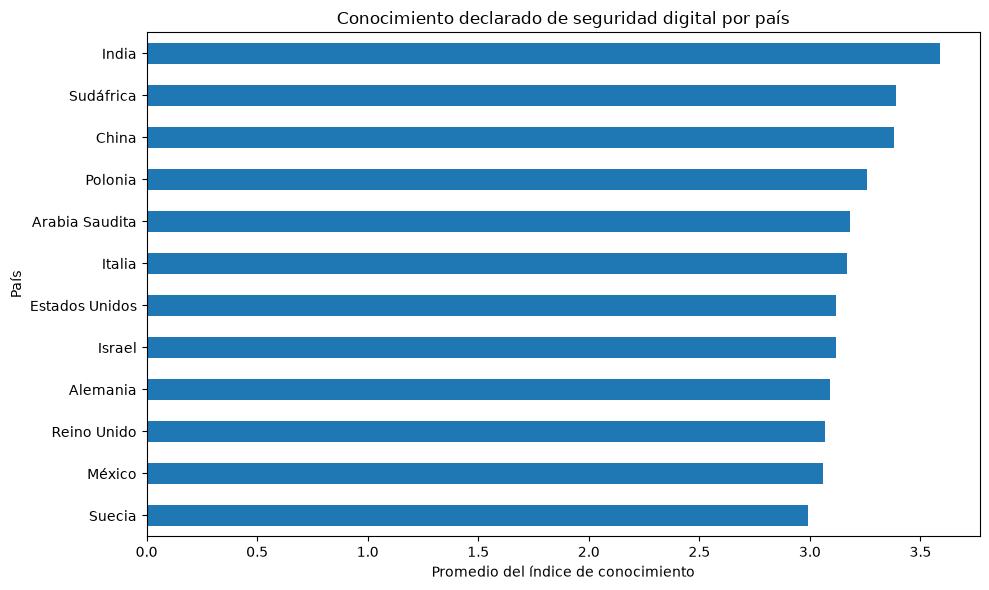

In [13]:
resumen_grafico = resumen_paises.sort_values(
    "conocimiento_medio"
)

resumen_grafico["conocimiento_medio"].plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Conocimiento declarado de seguridad digital por país")
plt.xlabel("Promedio del índice de conocimiento")
plt.ylabel("País")
plt.tight_layout()
plt.show()


## 13. Exportación de la tabla descriptiva

Guardar el resumen por país en un archivo CSV para su revisión, reutilización o inclusión en un informe. Uitlizando el comando `to_csv()` que escribe la tabla con codificación `utf-8-sig`, útil para conservar caracteres acentuados al abrir el archivo en programas de hoja de cálculo. Y como resultado se genera `resultados_descriptivos_por_pais.csv` en el directorio de trabajo del notebook.

In [14]:
resumen_paises.to_csv(
    "resultados_descriptivos_por_pais.csv",
    encoding="utf-8-sig"
)

print("Archivo exportado correctamente.")


Archivo exportado correctamente.


## 14. Estadísticos descriptivos de variables numéricas originales

A contonuación se obtiene un resumen numérico de las variables que la librería pandas reconoce como numéricas en la base original. El comando `describe().T` calcula estadísticos como media, desviación estándar, mínimo, máximo y cuartiles para las columnas numéricas.

In [15]:
display(df.describe().T) # Muestra, entre otras cosas, media, desviación estándar, mínimo, máximo y cuartiles de las variables numéricas

,count,mean,std,min,25%,50%,75%,max
ID,12351.0,6175.000000,3565.570922,0.0,3087.5,6175.0,9262.5,12350.000
Country,12351.0,6.537284,3.446862,1.0,4.0,7.0,10.0,12.000
Gender,12258.0,1.566895,0.623154,1.0,1.0,2.0,2.0,4.000
Age,9277.0,2.818152,1.030906,1.0,2.0,3.0,4.0,4.000
Education,12351.0,2.348636,0.704225,1.0,2.0,2.0,3.0,4.000
...,...,...,...,...,...,...,...,...
q22r6,12351.0,2.959760,1.224745,1.0,2.0,3.0,4.0,5.000
q22r7,12351.0,3.561007,1.290507,1.0,3.0,4.0,5.0,5.000
q22r8,12351.0,3.620355,1.236386,1.0,3.0,4.0,5.0,5.000
q25,12057.0,1.621548,0.494338,1.0,1.0,2.0,2.0,12.000


## 15. Descripción de variables numéricas y categóricas

En este paso se busca complementar el resumen anterior incorporando información de variables no numéricas, como número de categorías y categoría más frecuente. El comando `describe(include="all").T` solicita estadísticos para todos los tipos de columnas.

In [16]:
display(df.describe(include="all").T) # Incorpora frecuencias y categorías predominantes en las variables compatibles.

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,12351.0,NaN,NaN,NaN,6175.0,3565.570922,0.0,3087.5,6175.0,9262.5,12350.0
Country,12351.0,NaN,NaN,NaN,6.537284,3.446862,1.0,4.0,7.0,10.0,12.0
Gender,12258.0,NaN,NaN,NaN,1.566895,0.623154,1.0,1.0,2.0,2.0,4.0
Gender_SelfDescription,283,229,xx,44,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,9277.0,NaN,NaN,NaN,2.818152,1.030906,1.0,2.0,3.0,4.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...
q22r6,12351.0,NaN,NaN,NaN,2.95976,1.224745,1.0,2.0,3.0,4.0,5.0
q22r7,12351.0,NaN,NaN,NaN,3.561007,1.290507,1.0,3.0,4.0,5.0,5.0
q22r8,12351.0,NaN,NaN,NaN,3.620355,1.236386,1.0,3.0,4.0,5.0,5.0
q25,12057.0,NaN,NaN,NaN,1.621548,0.494338,1.0,1.0,2.0,2.0,12.0


La inspección inicial permite describir la estructura del conjunto de datos, los tipos de almacenamiento y algunas características descriptivas. La selección de técnicas estadísticas debe realizarse considerando la escala de medición, la distribución de las variables, los supuestos de cada prueba y la pregunta de investigación.


## 16. Revisión detallada de faltantes

Volver a calcular y presentar las variables con mayor proporción de datos faltantes, en esta ocasión usando nombres de columnas como índice de la tabla. Este diagnóstico puede servir para consultar las primeras variables afectadas de forma más directa. 

In [17]:
faltantes = pd.DataFrame({
    "cantidad_faltante": df.isna().sum(),
    "porcentaje_faltante": df.isna().mean() * 100
})

faltantes = faltantes.sort_values(
    "porcentaje_faltante",
    ascending=False
)

display(faltantes.head(30))

,cantidad_faltante,porcentaje_faltante
Gender_SelfDescription,12068,97.708688
q8r10oer1,11776,95.344507
Ethnicity,11300,91.490568
Age,3074,24.888673
q12r8,2742,22.200632
q12r5,1598,12.938224
q12r7,1305,10.565946
q12r6,1251,10.128735
q12r1,1223,9.902032
q12r3,1214,9.829164


## 17. Comprobación del total de faltantes

Verificar nuevamente el porcentaje global de celdas vacías como control de consistencia. Si los resultados coinciden con los de la sección 6, la base original no ha cambiado entre ambos cálculos. Si difieren, revisar qué objeto se está utilizando (`df` o `datos`).

In [18]:
total_celdas = df.shape[0] * df.shape[1]
total_faltantes = df.isna().sum().sum()

print("Total de celdas:", total_celdas)
print("Total de faltantes:", total_faltantes)
print(
    "Porcentaje global de faltantes:",
    round(total_faltantes / total_celdas * 100, 2), "%"
)

Total de celdas: 3063048
Total de faltantes: 89433
Porcentaje global de faltantes: 2.92 %


## 18. Gráfico de variables con más faltantes

A continuación se busca visualizar las variables que presentan los mayores porcentajes de no respuesta. Se representa horizontalmente el porcentaje de faltantes de las primeras veinte variables de la tabla ordenada.

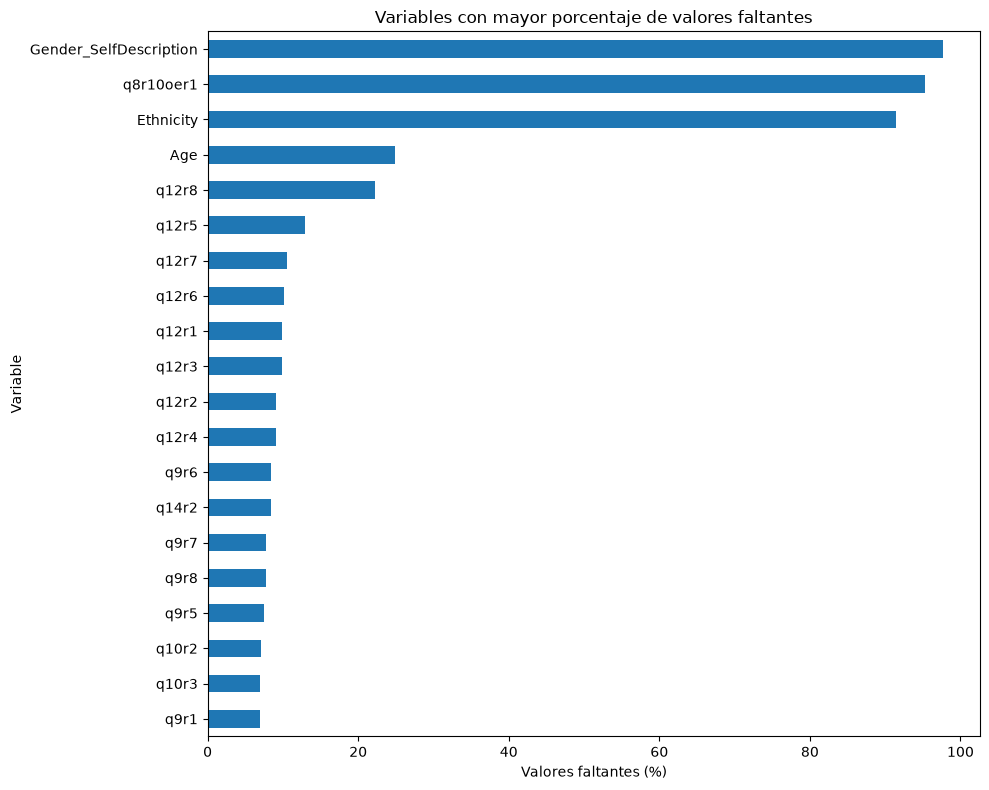

In [19]:
faltantes_top = faltantes.head(20)

faltantes_top["porcentaje_faltante"].sort_values().plot(
    kind="barh",
    figsize=(10, 8)
)

plt.title("Variables con mayor porcentaje de valores faltantes")
plt.xlabel("Valores faltantes (%)")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

## 19. Detección de filas duplicadas e identificadores repetidos

En este paso se desea comprobar si existen filas completamente duplicadas y si el identificador `ID` se repite. Esto se realiza con el comando `duplicated()` que detecta registros repetidos según todas las columnas o según la columna `ID`.

In [20]:
print("Filas duplicadas completas:", df.duplicated().sum())
print("ID duplicados:", df["ID"].duplicated().sum())

Filas duplicadas completas: 0
ID duplicados: 0


## 20. Distribuciones de variables demográficas

En este paso se examinan las frecuencias de las variables `Country`, `Gender`, `Age`, `Education` y `Ethnicity`, incluyendo los valores faltantes utilizando los comandos `value_counts(dropna=False)` que incluye las respuestas ausentes y `sort_index()` que organiza los códigos.

In [21]:
for variable in ["Country", "Gender", "Age", "Education", "Ethnicity"]:
    if variable in df.columns:
        print(f"\nVariable: {variable}")
        print(df[variable].value_counts(dropna=False).sort_index())


Variable: Country
Country
1     1008
2     1019
3     1011
4     1011
5     1019
6     1045
7     1054
8     1018
9     1048
10    1049
11    1018
12    1051
Name: count, dtype: int64

Variable: Gender
Gender
1.0    5901
2.0    6048
3.0      26
4.0     283
NaN      93
Name: count, dtype: int64

Variable: Age
Age
1.0    1115
2.0    2581
3.0    2457
4.0    3124
NaN    3074
Name: count, dtype: int64

Variable: Education
Education
1.0    1534
2.0    5103
3.0    5588
4.0     126
Name: count, dtype: int64

Variable: Ethnicity
Ethnicity
1.0      723
2.0      118
3.0      123
4.0       62
5.0       25
NaN    11300
Name: count, dtype: int64


## 21. Distribución de respuestas seleccionadas

En este paso se desea examinar las frecuencias de algunos ítems de victimización (`q7`) y protección (`q20`) como ejemplo de inspección de codificaciones. Se muestran frecuencias de valores y faltantes para los ítems seleccionados.

In [22]:
for variable in ["q7r1", "q7r2", "q20r1", "q20r2"]:
    if variable in df.columns:
        print(f"\n{variable}")
        print(df[variable].value_counts(dropna=False))


q7r1
q7r1
2.0    6807
1.0    5381
NaN     163
Name: count, dtype: int64

q7r2
q7r2
2.0    10038
1.0     2098
NaN      215
Name: count, dtype: int64

q20r1
q20r1
0    11989
1      361
2        1
Name: count, dtype: int64

q20r2
q20r2
1    8346
0    4005
Name: count, dtype: int64


## 22. Auditoría de inconsistencias y tipos de datos

En este paso se desea verificar que los valores de los ítems seleccionados sean compatibles con las escalas descritas en el diccionario de variables y detectar conversiones numéricas que puedan generar valores faltantes.

Criterios de revisión.
- Los ítems `q6r1`–`q6r22` se esperan en una escala de 1 a 5.
- Los ítems `q20r1`–`q20r14` se esperan codificados como 0/1.
- Los ítems `q7r1`–`q7r9` se esperan codificados como 1 = Sí y 2 = No.
- En `q4r8`, las respuestas que no puedan convertirse a número se reportan para inspección, no se sustituyen automáticamente por cero.
- Los identificadores repetidos se revisan por separado de las filas completamente duplicadas.

In [23]:
# Auditoría de rangos esperados: se informa, pero no se corrige automáticamente.
escalas_esperadas = {
    "conocimiento_q6_escala_1_a_5": ([f"q6r{i}" for i in range(1, 23)], [1, 2, 3, 4, 5]),
    "proteccion_q20_binaria_0_1": ([f"q20r{i}" for i in range(1, 15)], [0, 1]),
    "victimizacion_q7_1_si_2_no": ([f"q7r{i}" for i in range(1, 10)], [1, 2]),
}

hallazgos_calidad = []

for nombre_bloque, (columnas, valores_validos) in escalas_esperadas.items():
    columnas_existentes = [col for col in columnas if col in df.columns]
    for col in columnas_existentes:
        original = df[col]
        numerico = pd.to_numeric(original, errors="coerce")

        # Valores numéricos fuera de la codificación documentada.
        fuera_rango = numerico.notna() & ~numerico.isin(valores_validos)
        # Valores no vacíos que no se pudieron convertir a número.
        no_convertibles = original.notna() & numerico.isna()

        if fuera_rango.any() or no_convertibles.any():
            hallazgos_calidad.append({
                "Bloque": nombre_bloque,
                "Variable": col,
                "Valores_fuera_de_rango": int(fuera_rango.sum()),
                "No_convertibles_no_vacios": int(no_convertibles.sum()),
                "Ejemplos_fuera_de_rango": original[fuera_rango].astype(str).unique()[:5].tolist(),
                "Ejemplos_no_convertibles": original[no_convertibles].astype(str).unique()[:5].tolist()
            })

if hallazgos_calidad:
    auditoria_calidad = pd.DataFrame(hallazgos_calidad)
    display(auditoria_calidad)
else:
    print("No se detectaron valores fuera de las escalas revisadas ni respuestas no convertibles en los bloques auditados.")

# Revisión específica de q4r8: se conserva el valor original en df.
if "q4r8" in df.columns:
    q4r8_num = pd.to_numeric(df["q4r8"], errors="coerce")
    q4r8_no_convertible = df["q4r8"].notna() & q4r8_num.isna()
    print("\nRespuestas no vacías de q4r8 que no se convierten a número:",
          int(q4r8_no_convertible.sum()))
    if q4r8_no_convertible.any():
        display(df.loc[q4r8_no_convertible, ["q4r8"]].drop_duplicates().head(10))

# Identificadores y duplicados: indicadores distintos, no se eliminan aquí.
print("\nFilas completamente duplicadas:", int(df.duplicated().sum()))
if "ID" in df.columns:
    print("ID faltantes:", int(df["ID"].isna().sum()))
    print("ID repetidos:", int(df["ID"].duplicated().sum()))


,Bloque,Variable,Valores_fuera_de_rango,No_convertibles_no_vacios,Ejemplos_fuera_de_rango,Ejemplos_no_convertibles
0,proteccion_q20_binaria_0_1,q20r1,1,0,[2],[]
1,victimizacion_q7_1_si_2_no,q7r9,1,0,[0.0],[]



Respuestas no vacías de q4r8 que no se convierten a número: 1


,q4r8
11464,getting my information



Filas completamente duplicadas: 0
ID faltantes: 0
ID repetidos: 0


## 23. Verificación de la conversión de `q4r8`

Repetir de forma explícita la conversión de `q4r8` en la copia de trabajo y comprobar el tipo resultante y el número de faltantes. Esta celda vuelve a crear `datos` desde `df`; por ello, cualquier transformación realizada previamente sobre `datos` se pierde y debe reconstruirse después de esta celda. Para evitar confusiones, ejecutar las celdas en orden y considerar una única sección como punto oficial de preparación de datos.

In [24]:
datos = df.copy()

datos["q4r8"] = pd.to_numeric(
    datos["q4r8"],
    errors="coerce"
)

print(datos["q4r8"].dtype)
print("Faltantes en q4r8:", datos["q4r8"].isna().sum())

float64
Faltantes en q4r8: 1


## 24. Inspección de la pregunta de control `q13r11`

Se revisa la distribución de la respuesta a la pregunta de control, que el diccionario indica que no mide conocimiento de seguridad sino atención a una instrucción específica. Se cuentan los valores, incluyendo faltantes, y se ordenan por código. El diccionario señala que la respuesta esperada es el valor 4 y recomienda definir y documentar un criterio para identificar respuestas de baja calidad. No incluir `q13r11` en el índice de conocimiento.

In [25]:
display(
    df["q13r11"]
    .value_counts(dropna=False)
    .sort_index()
)

q13r11
2.0        1
4.0    11296
5.0     1054
Name: count, dtype: int64

## 25. Análisis de sensibilidad con la pregunta de control

Se busca crear una muestra de sensibilidad con participantes que respondieron `4` en `q13r11`, conservando también la muestra original para comparación. Esta muestra filtrada no debe sustituir automáticamente la original. El criterio de exclusión puede alterar la composición de la muestra y los resultados, por eso conviene presentar la decisión explícitamente y comparar hallazgos bajo ambos criterios.

In [26]:
# Análisis principal: mantener los registros originales
datos = df.copy()

# Grupo de sensibilidad: respuestas con valor esperado 4
datos_control = datos.loc[datos["q13r11"] == 4].copy()

print("Muestra original:", len(datos))
print("Muestra con respuesta de control = 4:", len(datos_control))

Muestra original: 12351
Muestra con respuesta de control = 4: 11296


## 26. Comprobación de columnas antes de construir variables derivadas

Volver a consultar los encabezados para confirmar que las variables requeridas para los índices están disponibles después de los pasos de preparación.
Las transformaciones deben ejecutarse solo cuando los nombres de columna estén verificados. La selección por nombre reduce el riesgo de usar accidentalmente una columna equivocada.

In [27]:
print(datos.columns.tolist())

['ID', 'Country', 'Gender', 'Gender_SelfDescription', 'Age', 'Education', 'Ethnicity', 'q1r1', 'q1r2', 'q1r3', 'q1r4', 'q1r5', 'q1r6', 'q1r7', 'q2r1', 'q2r2', 'q2r3', 'q3r1', 'q3r2', 'q3r3', 'q3r4', 'q3r5', 'q3r6', 'q3r7', 'q3r8', 'q3r9', 'q3r10', 'q3r11', 'q3r12', 'q3r13', 'q4r1', 'q4r2', 'q4r3', 'q4r4', 'q4r5', 'q4r6', 'q4r7', 'q4r8', 'q6r1', 'q6r2', 'q6r3', 'q6r4', 'q6r5', 'q6r6', 'q6r7', 'q6r8', 'q6r9', 'q6r10', 'q6r11', 'q6r12', 'q6r13', 'q6r14', 'q6r15', 'q6r16', 'q6r17', 'q6r18', 'q6r19', 'q6r20', 'q6r21', 'q6r22', 'q7r1', 'q7r2', 'q7r3', 'q7r4', 'q7r5', 'q7r6', 'q7r7', 'q7r8', 'q7r9', 'q8r2', 'q8r3', 'q8r4', 'q8r5', 'q8r6', 'q8r7', 'q8r8', 'q8r9', 'q8r10', 'q8r1', 'q8r10oer1', 'q9r1', 'q9r2', 'q9r3', 'q9r4', 'q9r5', 'q9r6', 'q9r7', 'q9r8', 'q9r9', 'q10r1', 'q10r2', 'q10r3', 'q10r4', 'q10r5', 'q11r1', 'q11r2', 'q11r3', 'q11r4', 'q11r5', 'q12r1', 'q12r2', 'q12r3', 'q12r4', 'q12r5', 'q12r6', 'q12r7', 'q12r8', 'q13r1', 'q13r2', 'q13r3', 'q13r4', 'q13r5', 'q13r6', 'q13r7', 'q13r8', 

## 27. Preparación de los ítems de conocimiento

Seleccionar los 22 ítems de `q6`, convertirlos a formato numérico y preparar el cálculo del índice. La conversión con `errors="coerce"` permite detectar entradas no numéricas transformándolas en `NaN`; debe revisarse si aparece algún valor inesperado.

In [28]:
# Construir los índices de conocimiento y comportamiento protector.
# Esta celda se ejecuta después de cualquier reinicio de datos = df.copy().

# Índice de conocimiento: promedio de q6r1-q6r22.
items_conocimiento = [f"q6r{i}" for i in range(1, 23)]
items_conocimiento = [col for col in items_conocimiento if col in datos.columns]

datos[items_conocimiento] = datos[items_conocimiento].apply(
    pd.to_numeric, errors="coerce"
)

datos["n_items_conocimiento"] = datos[items_conocimiento].notna().sum(axis=1)
datos["indice_conocimiento"] = datos[items_conocimiento].mean(axis=1)

# Umbral operativo: al menos 18 respuestas válidas de los 22 ítems.
# Equivale al 81,8 % de los ítems; se documenta como criterio metodológico,
# no como punto de corte validado externamente.
minimo_items = 18
datos.loc[
    datos["n_items_conocimiento"] < minimo_items,
    "indice_conocimiento"
] = np.nan

# Índice de protección: suma q20r2-q20r14 (13 medidas posibles).
# q20r1 = "ninguna medida" se conserva como indicador separado y no se suma.
items_proteccion = [f"q20r{i}" for i in range(2, 15)]
items_proteccion = [col for col in items_proteccion if col in datos.columns]
datos[items_proteccion] = datos[items_proteccion].apply(
    pd.to_numeric, errors="coerce"
)
datos["n_items_proteccion"] = datos[items_proteccion].notna().sum(axis=1)
datos["indice_proteccion"] = datos[items_proteccion].sum(axis=1, min_count=1)

print("Umbral mínimo de respuestas para conocimiento:", minimo_items, "de 22")
print("Índices de conocimiento válidos:", int(datos["indice_conocimiento"].notna().sum()))
print("Registros por debajo del umbral:",
      int((datos["n_items_conocimiento"] < minimo_items).sum()))
print("Índices de protección válidos:", int(datos["indice_proteccion"].notna().sum()))

display(datos[[
    "n_items_conocimiento", "indice_conocimiento",
    "n_items_proteccion", "indice_proteccion"
]].describe().T)

Umbral mínimo de respuestas para conocimiento: 18 de 22
Índices de conocimiento válidos: 12351
Registros por debajo del umbral: 0
Índices de protección válidos: 12351


,count,mean,std,min,25%,50%,75%,max
n_items_conocimiento,12351.0,22.000000,0.000000,22.0,22.000000,22.000000,22.000000,22.0
indice_conocimiento,12351.0,3.201357,0.839590,1.0,2.590909,3.181818,3.818182,5.0
n_items_proteccion,12351.0,13.000000,0.000000,13.0,13.000000,13.000000,13.000000,13.0
indice_proteccion,12351.0,5.100478,2.840031,0.0,3.000000,5.000000,7.000000,13.0


## 28. Estadística descriptiva de los índices

Complementar `describe()` con medidas de tendencia central, dispersión robusta y forma de las distribuciones.

Variables.
- `indice_conocimiento`: promedio de los ítems `q6r1`–`q6r22`, válido cuando hay al menos 18 respuestas observadas.
- `indice_proteccion`: suma de los ítems `q20r1`–`q20r14`, con rango teórico de 0 a 14 si los ítems están codificados como 0/1.

Medidas. Se calculan media, mediana, moda, desviación estándar, mínimo, máximo, cuartiles, rango intercuartílico (IQR), desviación absoluta mediana (MAD), asimetría y curtosis en exceso. El MAD se presenta sin factor de normalización (`scale=1`).

La media y la desviación estándar resumen centro y dispersión bajo una perspectiva clásica; la mediana, el IQR y el MAD son más robustos ante observaciones extremas. La asimetría y la curtosis ayudan a caracterizar la forma de la distribución, pero no deben interpretarse por sí solas como pruebas de normalidad.

In [29]:
from scipy.stats import median_abs_deviation

variables_indices = ["indice_conocimiento", "indice_proteccion"]
resultados_robustos = []

for variable in variables_indices:
    serie = pd.to_numeric(datos[variable], errors="coerce").dropna()

    if serie.empty:
        print(f"No hay observaciones válidas para {variable}.")
        continue

    moda = serie.mode()
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)

    resultados_robustos.append({
        "Variable": variable,
        "N válido": int(serie.count()),
        "Media": serie.mean(),
        "Mediana": serie.median(),
        "Moda": moda.iloc[0] if not moda.empty else np.nan,
        "Desviación estándar": serie.std(),
        "Mínimo": serie.min(),
        "Q1": q1,
        "Q3": q3,
        "Máximo": serie.max(),
        "IQR": q3 - q1,
        "MAD": median_abs_deviation(serie, scale=1, nan_policy="omit"),
        "Asimetría": serie.skew(),
        "Curtosis (exceso)": serie.kurt()
    })

estadisticos_robustos = pd.DataFrame(resultados_robustos).set_index("Variable")
display(estadisticos_robustos.round(3))

,N válido,Media,Mediana,Moda,Desviación estándar,Mínimo,Q1,Q3,Máximo,IQR,MAD,Asimetría,Curtosis (exceso)
Variable,,,,,,,,,,,,,
indice_conocimiento,12351,3.201,3.182,3.273,0.84,1.0,2.591,3.818,5.0,1.227,0.591,-0.015,-0.553
indice_proteccion,12351,5.100,5.000,4.000,2.84,0.0,3.000,7.000,13.0,4.000,2.000,0.433,-0.251


## Estadística descriptiva robusta de otras variables clave

La pregunta rectora busca explicar diferencias entre poblaciones en lo que las personas saben, sienten y hacen en materia de seguridad digital. Por eso, además del conocimiento (`q6`) y las prácticas protectoras (`q20`), se describen la victimización (`q7`), la preocupación por la seguridad (`q18`), la importancia atribuida a proteger los datos (`q21`) y el riesgo percibido (`q22`). Estas dimensiones permiten explorar la posible brecha entre conocimiento, percepción y comportamiento.

Los promedios de `q18`, `q21` y `q22` se calculan por persona cuando existe al menos el 70 % de respuestas válidas de su batería. La victimización se recodifica como 1 = sí y 0 = no, y se suma entre los nueve tipos de experiencia para obtener un recuento de tipos reportados (rango teórico 0–9). Este recuento no indica gravedad ni frecuencia de incidentes. Para los ítems ordinales y binarios se reportan medidas robustas, pero la asimetría y la curtosis se calculan solo cuando hay al menos tres valores distintos; no deben interpretarse como si las escalas fueran continuas.

In [30]:
from scipy.stats import median_abs_deviation, skew, kurtosis

# 1. Preparar las baterías seleccionadas a partir de los nombres reales del CSV.
items_victimizacion = [f"q7r{i}" for i in range(1, 10) if f"q7r{i}" in datos.columns]
items_preocupacion = [f"q18ar{i}" for i in range(1, 9) if f"q18ar{i}" in datos.columns]
items_preocupacion += [f"q18br{i}" for i in range(9, 20) if f"q18br{i}" in datos.columns]
items_importancia_datos = [f"q21r{i}" for i in range(1, 16) if f"q21r{i}" in datos.columns]
items_riesgo_percibido = [f"q22r{i}" for i in range(1, 9) if f"q22r{i}" in datos.columns]

for grupo in [items_victimizacion, items_preocupacion, items_importancia_datos, items_riesgo_percibido]:
    datos[grupo] = datos[grupo].apply(pd.to_numeric, errors="coerce")

# Victimización: en q7, 1=Sí y 2=No; se transforma a 1/0, manteniendo NR como NaN.
for col in items_victimizacion:
    datos[col + "_bin"] = datos[col].map({1: 1, 2: 0})
items_victimizacion_bin = [col + "_bin" for col in items_victimizacion]
datos["recuento_victimizacion"] = datos[items_victimizacion_bin].sum(axis=1, min_count=1)

# Índices promedio por batería: mínimo 70% de ítems válidos en cada persona.
def promedio_bateria(df, columnas, nombre, proporcion_minima=0.70):
    if not columnas:
        df[nombre] = np.nan
        return
    n_validos = df[columnas].notna().sum(axis=1)
    minimo = int(np.ceil(len(columnas) * proporcion_minima))
    df[nombre] = df[columnas].mean(axis=1)
    df.loc[n_validos < minimo, nombre] = np.nan
    df["n_validos_" + nombre] = n_validos

promedio_bateria(datos, items_preocupacion, "indice_preocupacion")
promedio_bateria(datos, items_importancia_datos, "indice_importancia_datos")
promedio_bateria(datos, items_riesgo_percibido, "indice_riesgo_percibido")

# 2. Medidas robustas para los constructos/índices principales.
variables_clave = [
    "indice_conocimiento", "indice_proteccion", "recuento_victimizacion",
    "indice_preocupacion", "indice_importancia_datos", "indice_riesgo_percibido"
]
filas = []
for variable in variables_clave:
    s = pd.to_numeric(datos[variable], errors="coerce").dropna()
    if s.empty:
        continue
    moda = s.mode()
    q1, q3 = s.quantile([0.25, 0.75])
    filas.append({
        "Variable": variable,
        "N válido": int(s.size),
        "Media": s.mean(),
        "Mediana": s.median(),
        "Moda": moda.iloc[0] if not moda.empty else np.nan,
        "Desv. estándar": s.std(),
        "Q1": q1,
        "Q3": q3,
        "IQR": q3 - q1,
        "MAD": median_abs_deviation(s, scale=1, nan_policy="omit"),
        "Mínimo": s.min(),
        "Máximo": s.max(),
        "Asimetría": skew(s, bias=False) if s.nunique() >= 3 and s.size >= 3 else np.nan,
        "Curtosis (exceso)": kurtosis(s, bias=False) if s.nunique() >= 3 and s.size >= 4 else np.nan,
    })

resumen_variables_clave = pd.DataFrame(filas)
display(resumen_variables_clave.round(3))

# 3. Estadística por ítem para revisar la heterogeneidad dentro de cada batería.
# En variables ordinales/binarias se priorizan frecuencias, mediana, moda e IQR.
items_clave = (
    [c for c in [f"q6r{i}" for i in range(1, 23)] if c in datos.columns]
    + items_victimizacion_bin
    + [c for c in [f"q20r{i}" for i in range(1, 15)] if c in datos.columns]
    + items_preocupacion + items_importancia_datos + items_riesgo_percibido
)
filas_items = []
for variable in items_clave:
    s = pd.to_numeric(datos[variable], errors="coerce").dropna()
    if s.empty:
        continue
    moda = s.mode()
    q1, q3 = s.quantile([0.25, 0.75])
    frecuencias = s.value_counts(normalize=True)
    filas_items.append({
        "Ítem": variable,
        "N válido": int(s.size),
        "% faltante": round(datos[variable].isna().mean() * 100, 2),
        "Media": s.mean(),
        "Mediana": s.median(),
        "Moda": moda.iloc[0] if not moda.empty else np.nan,
        "Desv. estándar": s.std(),
        "IQR": q3 - q1,
        "MAD": median_abs_deviation(s, scale=1, nan_policy="omit"),
        "Valor más frecuente (%)": frecuencias.iloc[0] * 100,
        "Asimetría": skew(s, bias=False) if s.nunique() >= 3 and s.size >= 3 else np.nan,
        "Curtosis (exceso)": kurtosis(s, bias=False) if s.nunique() >= 3 and s.size >= 4 else np.nan,
    })

resumen_items_clave = pd.DataFrame(filas_items)
display(resumen_items_clave.round(3))

# Exportación opcional para usar las tablas en el informe científico.
resumen_variables_clave.to_csv("estadistica_robusta_variables_clave.csv", index=False, encoding="utf-8-sig")
resumen_items_clave.to_csv("estadistica_robusta_items_clave.csv", index=False, encoding="utf-8-sig")
print("Tablas guardadas: estadistica_robusta_variables_clave.csv y estadistica_robusta_items_clave.csv")

C:\Users\adria\AppData\Local\Temp\ipykernel_20012\1531479031.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  datos[col + "_bin"] = datos[col].map({1: 1, 2: 0})
C:\Users\adria\AppData\Local\Temp\ipykernel_20012\1531479031.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  datos[col + "_bin"] = datos[col].map({1: 1, 2: 0})
C:\Users\adria\AppData\Local\Temp\ipykernel_20012\1531479031.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor per

,Variable,N válido,Media,Mediana,Moda,Desv. estándar,Q1,Q3,IQR,MAD,Mínimo,Máximo,Asimetría,Curtosis (exceso)
0,indice_conocimiento,12351,3.201,3.182,3.273,0.840,2.591,3.818,1.227,0.591,1.0,5.0,-0.015,-0.553
1,indice_proteccion,12351,5.100,5.000,4.000,2.840,3.000,7.000,4.000,2.000,0.0,13.0,0.433,-0.251
2,recuento_victimizacion,12333,1.843,1.000,0.000,2.099,0.000,3.000,3.000,1.000,0.0,9.0,1.367,1.526
3,indice_preocupacion,12282,3.951,4.105,5.000,0.880,3.368,4.684,1.316,0.632,1.0,5.0,-0.851,0.219
4,indice_importancia_datos,12320,4.370,4.600,5.000,0.688,4.000,4.933,0.933,0.400,1.0,5.0,-1.364,1.707
5,indice_riesgo_percibido,12351,2.840,2.875,3.000,0.906,2.250,3.500,1.250,0.625,1.0,5.0,0.079,-0.425


,Ítem,N válido,% faltante,Media,Mediana,Moda,Desv. estándar,IQR,MAD,Valor más frecuente (%),Asimetría,Curtosis (exceso)
0,q6r1,12351,0.00,3.590,4.0,4.0,1.103,1.0,1.0,36.718,-0.599,-0.231
1,q6r2,12351,0.00,2.703,3.0,1.0,1.349,3.0,1.0,27.131,0.152,-1.205
2,q6r3,12351,0.00,3.097,3.0,4.0,1.307,2.0,1.0,29.317,-0.224,-1.081
3,q6r4,12351,0.00,2.259,2.0,1.0,1.306,2.0,1.0,41.155,0.629,-0.848
4,q6r5,12351,0.00,2.983,3.0,1.0,1.492,3.0,1.0,26.451,-0.098,-1.446
5,q6r6,12351,0.00,3.001,3.0,4.0,1.416,2.0,1.0,27.277,-0.134,-1.318
6,q6r7,12351,0.00,3.622,4.0,4.0,1.044,1.0,1.0,38.272,-0.560,-0.167
7,q6r8,12351,0.00,3.458,4.0,4.0,1.091,1.0,1.0,33.155,-0.387,-0.466
8,q6r9,12351,0.00,3.058,3.0,4.0,1.360,2.0,1.0,25.852,-0.154,-1.185
9,q6r10,12351,0.00,2.839,3.0,3.0,1.272,2.0,1.0,26.508,0.081,-1.038


Tablas guardadas: estadistica_robusta_variables_clave.csv y estadistica_robusta_items_clave.csv


## 29. Detección exploratoria de valores atípicos mediante el rango intercuartílico

Identificar observaciones del índice de conocimiento que queden fuera de los límites exploratorios definidos por la regla de 1,5 veces el rango intercuartílico (IQR). Se calculan el primer cuartil (Q1), el tercer cuartil (Q3), el IQR = Q3 − Q1 y los límites Q1 − 1,5×IQR y Q3 + 1,5×IQR.

In [31]:
variable = "indice_conocimiento"

serie = datos[variable].dropna()

q1 = serie.quantile(0.25)
q3 = serie.quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

atipicos = datos[
    (datos[variable] < limite_inferior) |
    (datos[variable] > limite_superior)
]

print("Primer cuartil:", q1)
print("Tercer cuartil:", q3)
print("Rango intercuartílico:", iqr)
print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)
print("Número de valores atípicos:", len(atipicos))

Primer cuartil: 2.590909090909091
Tercer cuartil: 3.8181818181818183
Rango intercuartílico: 1.2272727272727275
Límite inferior: 0.7499999999999996
Límite superior: 5.65909090909091
Número de valores atípicos: 0


## 30. Diagrama de caja del índice de conocimiento

Complementar la regla del IQR con una representación gráfica de la distribución del índice. Esta caja representa el rango intercuartílico y la línea central la mediana; los bigotes y puntos, según la configuración del gráfico, ayudan a identificar observaciones alejadas del centro.

C:\Users\adria\AppData\Local\Temp\ipykernel_20012\3157703881.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


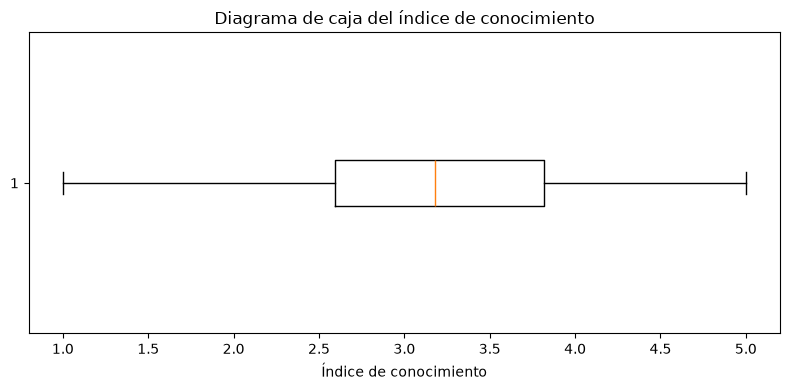

In [32]:
plt.figure(figsize=(8, 4))

plt.boxplot(
    datos["indice_conocimiento"].dropna(),
    vert=False
)

plt.title("Diagrama de caja del índice de conocimiento")
plt.xlabel("Índice de conocimiento")
plt.tight_layout()
plt.show()

## 31. Detección de valores atípicos con IQR para todas las variables clave

Se busca extender la detección IQR más allá del índice de conocimiento. Se usa la regla exploratoria de 1,5 × IQR en cada índice numérico derivado disponible.

In [33]:
# Asegurar que las variables clave se hayan calculado en las celdas anteriores.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

variables_clave = [
    "indice_conocimiento", "indice_proteccion", "recuento_victimizacion",
    "indice_preocupacion", "indice_importancia_datos", "indice_riesgo_percibido"
]
variables_clave = [v for v in variables_clave if v in datos.columns]
resultados_iqr = []
casos_iqr = {}
for v in variables_clave:
    x = pd.to_numeric(datos[v], errors="coerce").dropna()
    if x.empty:
        continue
    q1, q3 = x.quantile(.25), x.quantile(.75)
    iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (pd.to_numeric(datos[v], errors="coerce") < li) | (pd.to_numeric(datos[v], errors="coerce") > ls)
    resultados_iqr.append({"Variable": v, "N válido": len(x), "Q1": q1, "Q3": q3, "IQR": iqr,
                           "Límite inferior": li, "Límite superior": ls,
                           "N atípicos": int(mask.sum()), "% atípicos": 100 * mask.sum() / len(x)})
    cols_id = [c for c in ["ID", "id", "ResponseId", "respondent_id"] if c in datos.columns]
    columnas = cols_id + [v]
    casos_iqr[v] = datos.loc[mask, columnas].head(20)
tabla_iqr = pd.DataFrame(resultados_iqr)
display(tabla_iqr.round(3))
print("Muestra de hasta 20 casos detectados por variable (si existen):")
for v, tabla in casos_iqr.items():
    if not tabla.empty:
        print("\n", v)
        display(tabla)

,Variable,N válido,Q1,Q3,IQR,Límite inferior,Límite superior,N atípicos,% atípicos
0,indice_conocimiento,12351,2.591,3.818,1.227,0.750,5.659,0,0.000
1,indice_proteccion,12351,3.000,7.000,4.000,-3.000,13.000,0,0.000
2,recuento_victimizacion,12333,0.000,3.000,3.000,-4.500,7.500,327,2.651
3,indice_preocupacion,12282,3.368,4.684,1.316,1.395,6.658,109,0.887
4,indice_importancia_datos,12320,4.000,4.933,0.933,2.600,6.333,264,2.143
5,indice_riesgo_percibido,12351,2.250,3.500,1.250,0.375,5.375,0,0.000


Muestra de hasta 20 casos detectados por variable (si existen):

 recuento_victimizacion


,ID,recuento_victimizacion
3,3,9.0
27,27,9.0
322,322,9.0
523,523,9.0
692,692,8.0
817,817,9.0
968,968,8.0
1079,1079,9.0
1129,1129,9.0
1141,1141,8.0



 indice_preocupacion


,ID,indice_preocupacion
659,659,1.157895
712,712,1.315789
893,893,1.000000
912,912,1.000000
1028,1028,1.000000
1059,1059,1.000000
1093,1093,1.157895
1125,1125,1.111111
1184,1184,1.263158
1207,1207,1.000000



 indice_importancia_datos


,ID,indice_importancia_datos
29,29,2.466667
34,34,1.500000
125,125,2.266667
130,130,2.533333
187,187,2.533333
199,199,1.933333
307,307,2.333333
328,328,2.466667
431,431,2.466667
594,594,2.357143


## 32. Detección complementaria mediante puntuación z

Se señalan valores con |z| ≥ 3. La puntuación z puede ser sensible a distribuciones sesgadas, por eso se interpreta junto con IQR y los gráficos, no como regla automática de exclusión.

In [34]:
from scipy.stats import zscore
resultados_z = []
casos_z = {}
for v in variables_clave:
    x = pd.to_numeric(datos[v], errors="coerce")
    validos = x.dropna()
    if len(validos) < 3 or validos.std(ddof=0) == 0:
        continue
    z = (x - validos.mean()) / validos.std(ddof=0)
    mask = z.abs() >= 3
    resultados_z.append({"Variable": v, "N válido": len(validos), "N con |z| ≥ 3": int(mask.sum()),
                         "% con |z| ≥ 3": 100 * mask.sum() / len(validos),
                         "Media": validos.mean(), "Desviación estándar": validos.std(ddof=0)})
    cols_id = [c for c in ["ID", "id", "ResponseId", "respondent_id"] if c in datos.columns]
    casos_z[v] = datos.loc[mask, cols_id + [v]].head(20).assign(z=z[mask].head(20))
display(pd.DataFrame(resultados_z).round(3))
for v, tabla in casos_z.items():
    if not tabla.empty:
        print("Casos con |z| ≥ 3:", v)
        display(tabla)

,Variable,N válido,N con |z| ≥ 3,% con |z| ≥ 3,Media,Desviación estándar
0,indice_conocimiento,12351,0,0.000,3.201,0.840
1,indice_proteccion,12351,0,0.000,5.100,2.840
2,recuento_victimizacion,12333,200,1.622,1.843,2.099
3,indice_preocupacion,12282,88,0.716,3.951,0.880
4,indice_importancia_datos,12320,154,1.250,4.370,0.688
5,indice_riesgo_percibido,12351,0,0.000,2.840,0.906


Casos con |z| ≥ 3: recuento_victimizacion


,ID,recuento_victimizacion,z
3,3,9.0,3.409289
27,27,9.0,3.409289
322,322,9.0,3.409289
523,523,9.0,3.409289
817,817,9.0,3.409289
1079,1079,9.0,3.409289
1129,1129,9.0,3.409289
1858,1858,9.0,3.409289
1955,1955,9.0,3.409289
1998,1998,9.0,3.409289


Casos con |z| ≥ 3: indice_preocupacion


,ID,indice_preocupacion,z
659,659,1.157895,-3.173403
893,893,1.000000,-3.352766
912,912,1.000000,-3.352766
1028,1028,1.000000,-3.352766
1059,1059,1.000000,-3.352766
1093,1093,1.157895,-3.173403
1125,1125,1.111111,-3.226548
1184,1184,1.263158,-3.053828
1207,1207,1.000000,-3.352766
1256,1256,1.210526,-3.113615


Casos con |z| ≥ 3: indice_importancia_datos


,ID,indice_importancia_datos,z
34,34,1.500000,-4.172978
125,125,2.266667,-3.058116
199,199,1.933333,-3.542839
691,691,1.933333,-3.542839
714,714,2.000000,-3.445894
853,853,1.800000,-3.736728
855,855,1.000000,-4.900062
951,951,2.266667,-3.058116
1019,1019,1.933333,-3.542839
1028,1028,2.266667,-3.058116


## 33. Diagramas de caja y gráficos de violín

Los diagramas de caja facilitan la comparación de medianas y dispersión, los gráficos de violín añaden una estimación de la forma de la distribución. Se muestran para cada índice clave disponible.

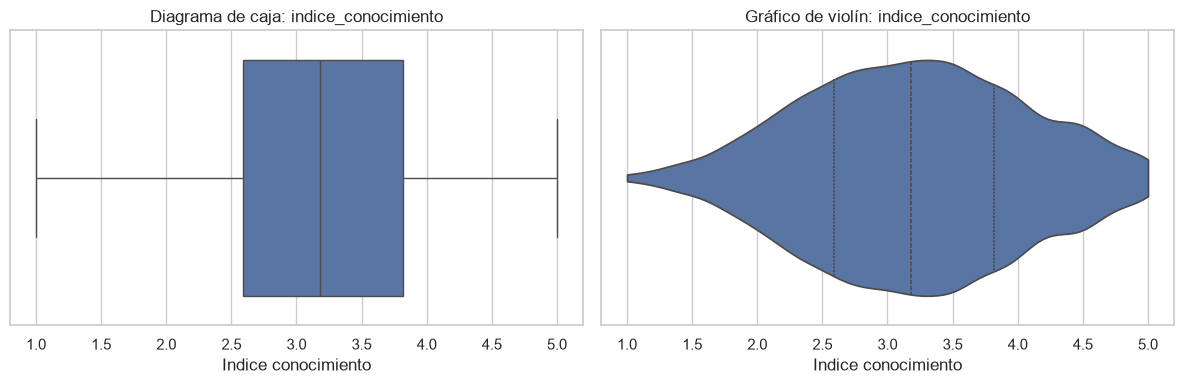

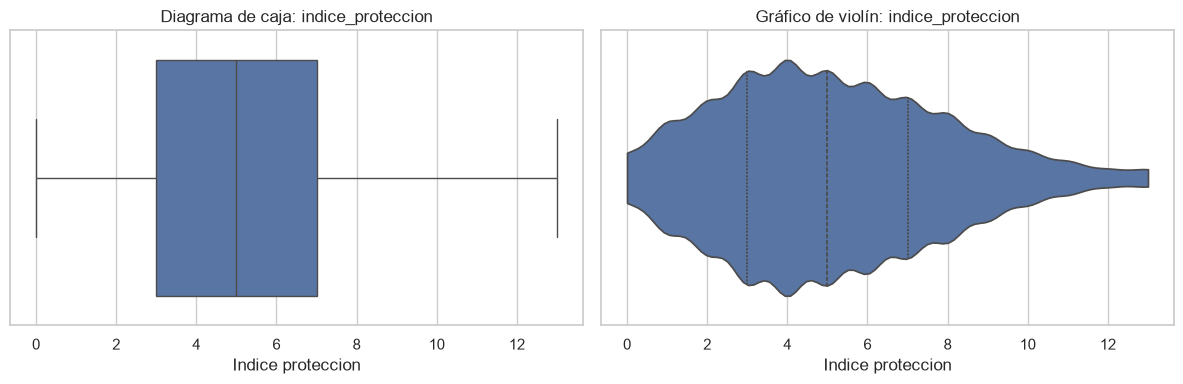

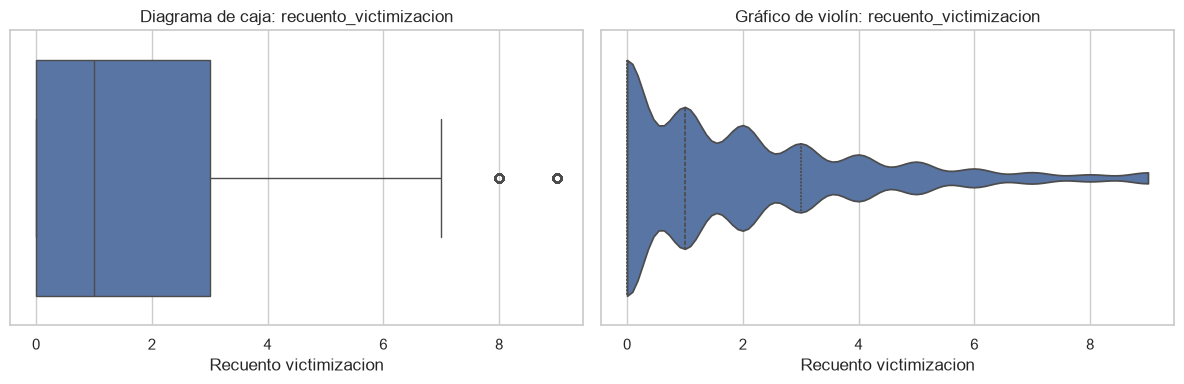

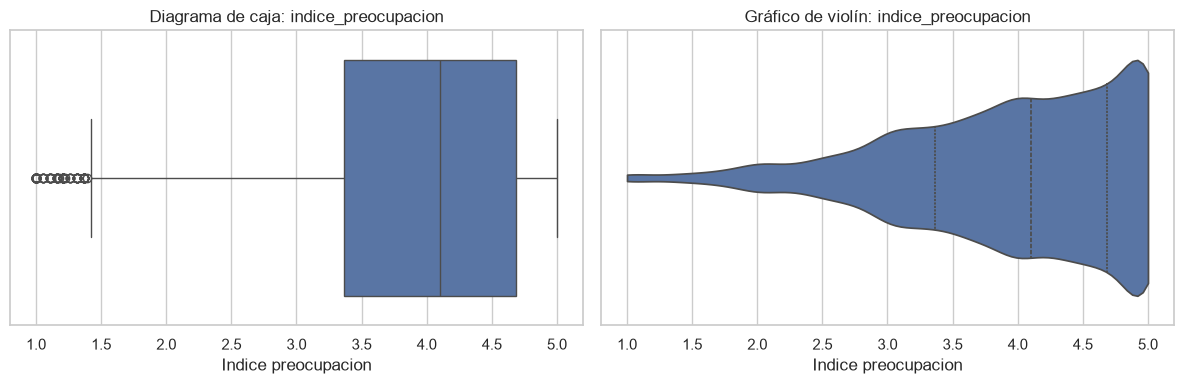

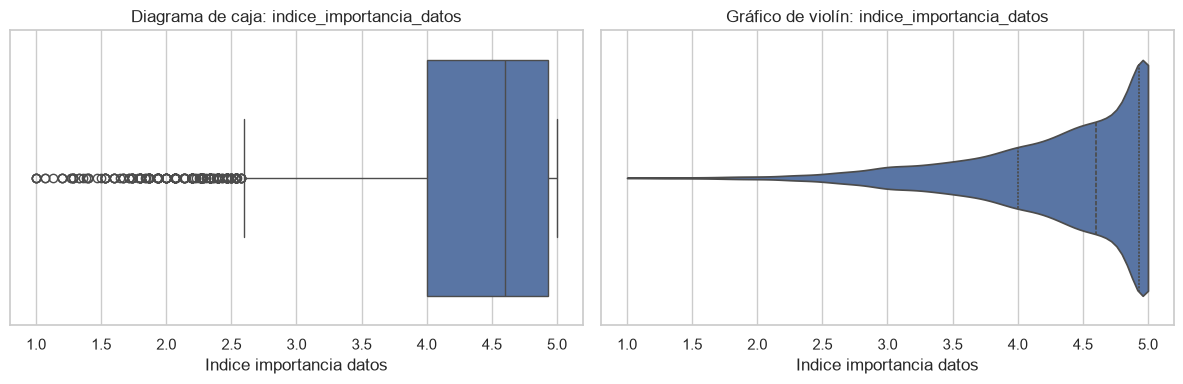

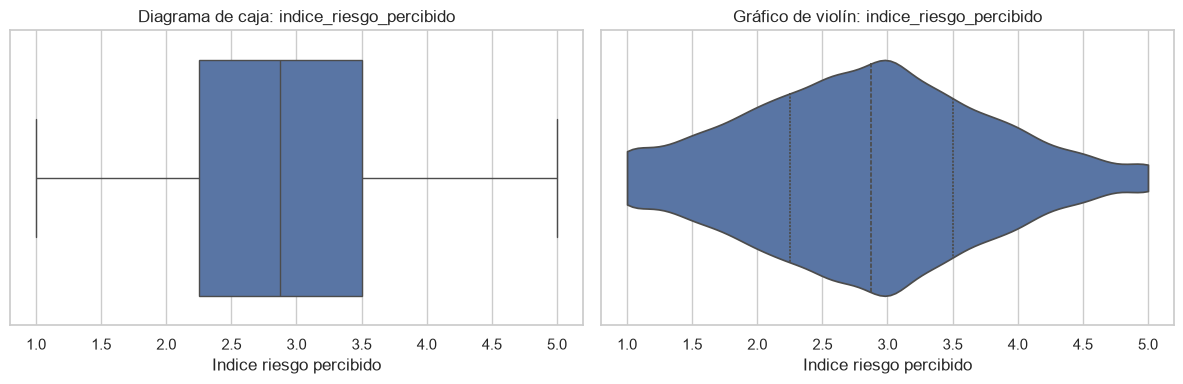

In [35]:
import seaborn as sns
sns.set_theme(style="whitegrid")
for v in variables_clave:
    x = pd.to_numeric(datos[v], errors="coerce").dropna()
    if x.empty:
        continue
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.boxplot(x=x, ax=axes[0], color=None)
    axes[0].set_title(f"Diagrama de caja: {v}")
    axes[0].set_xlabel(v.replace("_", " ").capitalize())
    sns.violinplot(x=x, ax=axes[1], inner="quartile", cut=0)
    axes[1].set_title(f"Gráfico de violín: {v}")
    axes[1].set_xlabel(v.replace("_", " ").capitalize())
    fig.tight_layout()
    plt.show()

## 34. Histogramas y curvas de densidad

Se presenta la distribución de cada variable clave. La curva KDE se omite cuando hay muy pocas observaciones o una única categoría numérica, situaciones en las que la estimación de densidad puede ser engañosa.

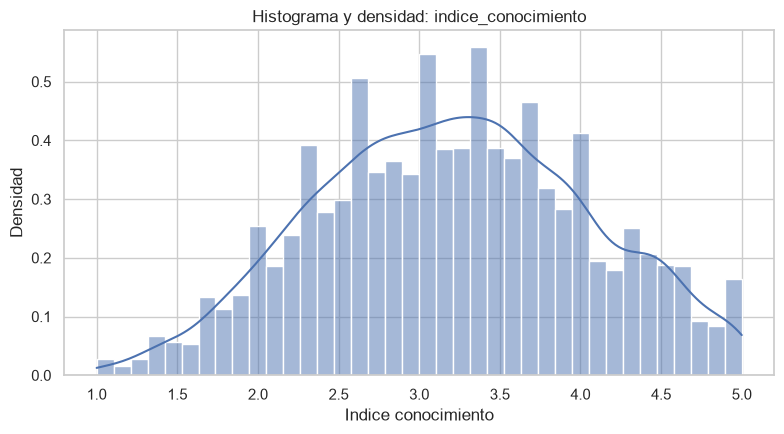

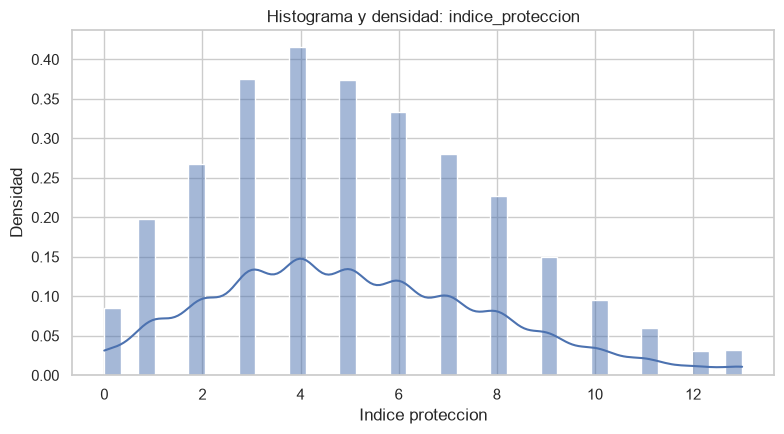

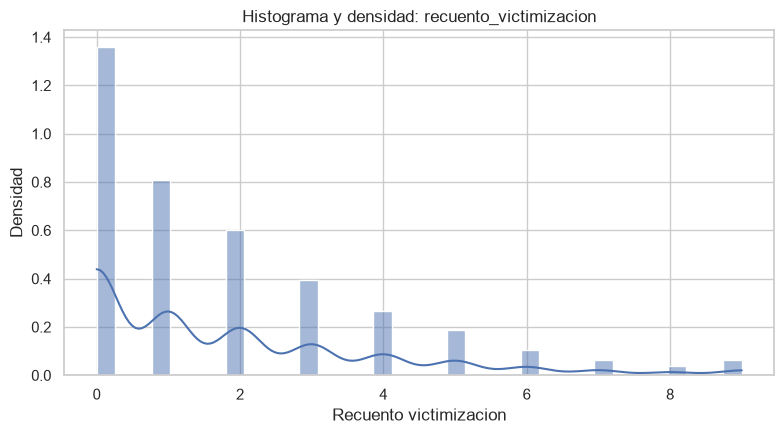

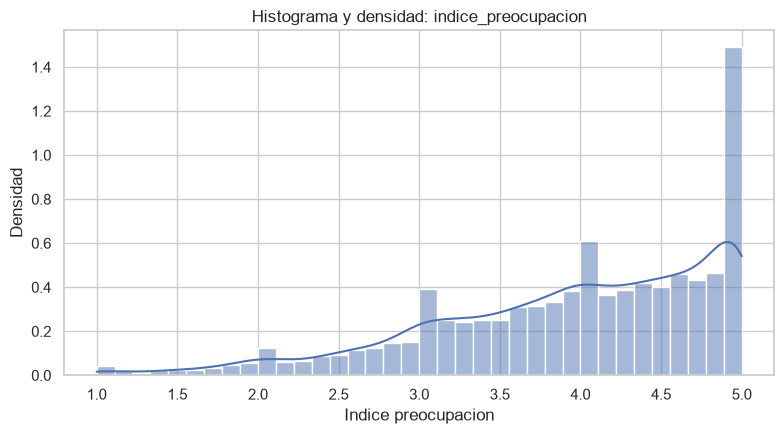

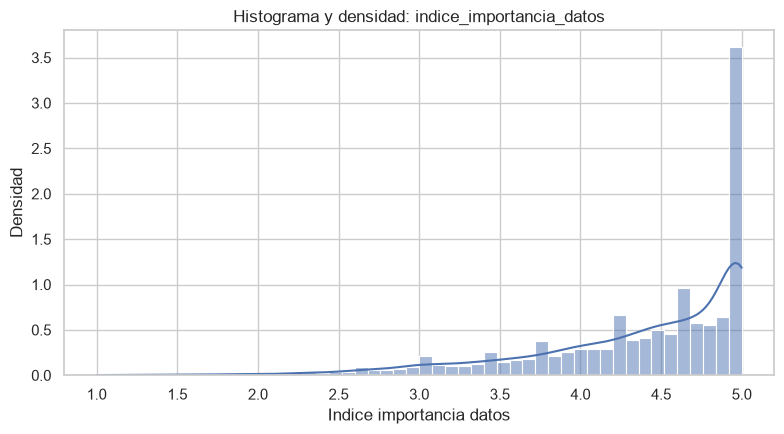

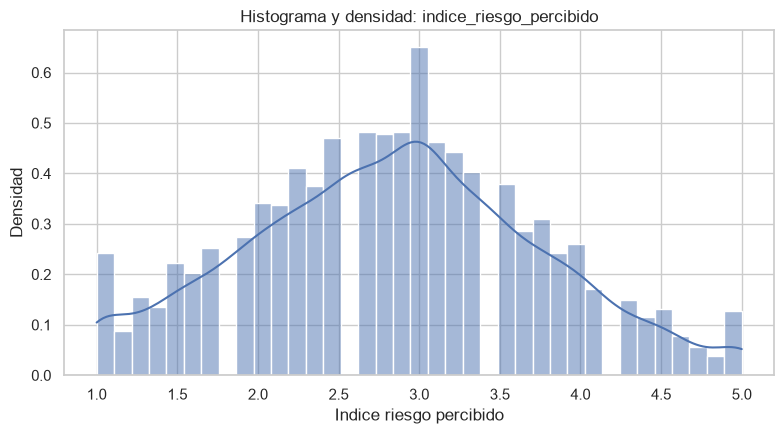

In [36]:
for v in variables_clave:
    x = pd.to_numeric(datos[v], errors="coerce").dropna()
    if x.empty:
        continue
    plt.figure(figsize=(8, 4.5))
    sns.histplot(x=x, bins="auto", stat="density", kde=(x.nunique() > 2 and len(x) > 10))
    plt.title(f"Histograma y densidad: {v}")
    plt.xlabel(v.replace("_", " ").capitalize())
    plt.ylabel("Densidad")
    plt.tight_layout()
    plt.show()

## 35. Diagramas de dispersión entre dimensiones

Los diagramas permiten inspeccionar relaciones bivariadas, posibles patrones no lineales y observaciones influyentes. La línea de tendencia es descriptiva y no demuestra causalidad.

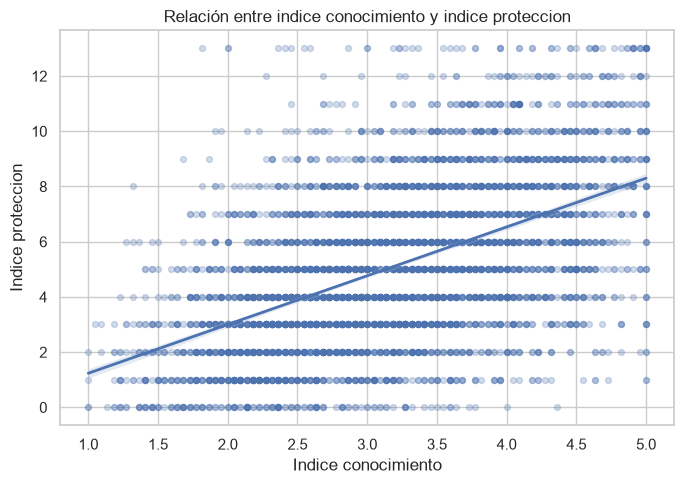

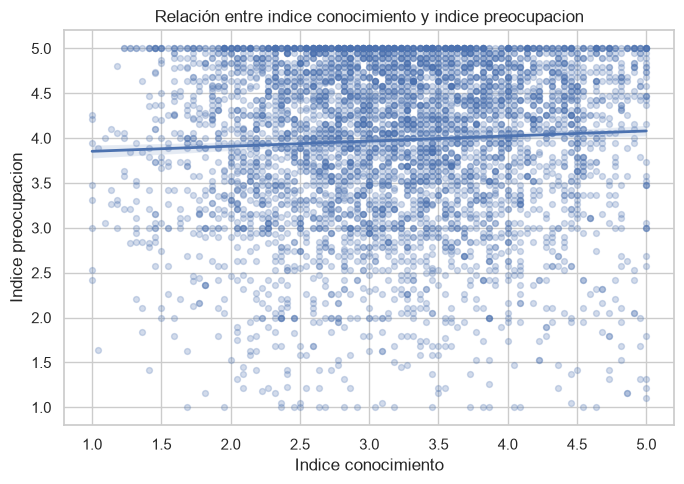

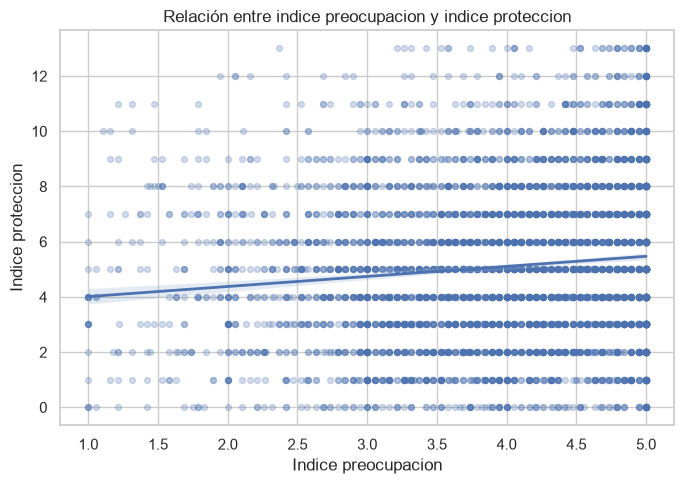

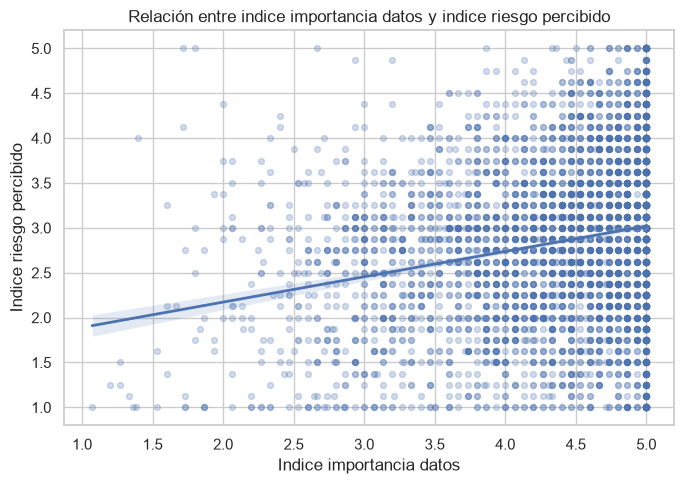

In [37]:
pares_scatter = [
    ("indice_conocimiento", "indice_proteccion"),
    ("indice_conocimiento", "indice_preocupacion"),
    ("indice_preocupacion", "indice_proteccion"),
    ("indice_importancia_datos", "indice_riesgo_percibido"),
]
for xvar, yvar in pares_scatter:
    if xvar not in datos.columns or yvar not in datos.columns:
        continue
    tmp = datos[[xvar, yvar]].apply(pd.to_numeric, errors="coerce").dropna()
    if len(tmp) > 5000:
        tmp = tmp.sample(5000, random_state=42)
    if len(tmp) < 3:
        continue
    plt.figure(figsize=(7, 5))
    sns.regplot(data=tmp, x=xvar, y=yvar, scatter_kws={"alpha": 0.25, "s": 18}, line_kws={"linewidth": 2})
    plt.title(f"Relación entre {xvar.replace('_',' ')} y {yvar.replace('_',' ')}")
    plt.xlabel(xvar.replace("_", " ").capitalize())
    plt.ylabel(yvar.replace("_", " ").capitalize())
    plt.tight_layout()
    plt.show()

## 36. Matrices de correlación Pearson y Spearman

Pearson resume asociación lineal entre variables numéricas y Spearman mide asociación monotónica basada en rangos. La correlación no implica causalidad y puede verse afectada por variables de confusión.

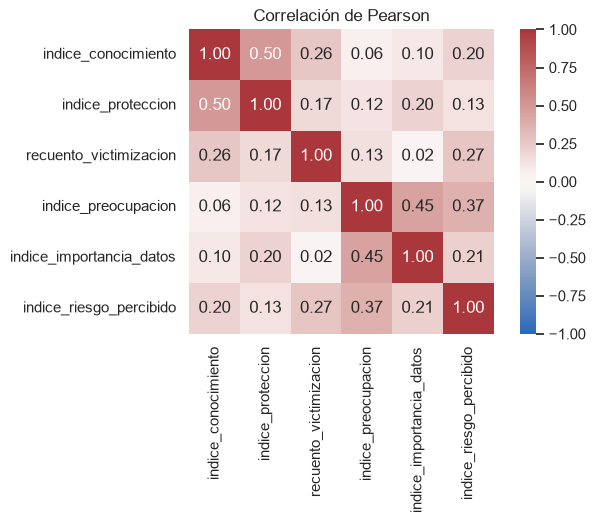

,indice_conocimiento,indice_proteccion,recuento_victimizacion,indice_preocupacion,indice_importancia_datos,indice_riesgo_percibido
indice_conocimiento,1.000,0.497,0.260,0.057,0.098,0.199
indice_proteccion,0.497,1.000,0.171,0.122,0.200,0.128
recuento_victimizacion,0.260,0.171,1.000,0.134,0.024,0.271
indice_preocupacion,0.057,0.122,0.134,1.000,0.452,0.373
indice_importancia_datos,0.098,0.200,0.024,0.452,1.000,0.213
indice_riesgo_percibido,0.199,0.128,0.271,0.373,0.213,1.000


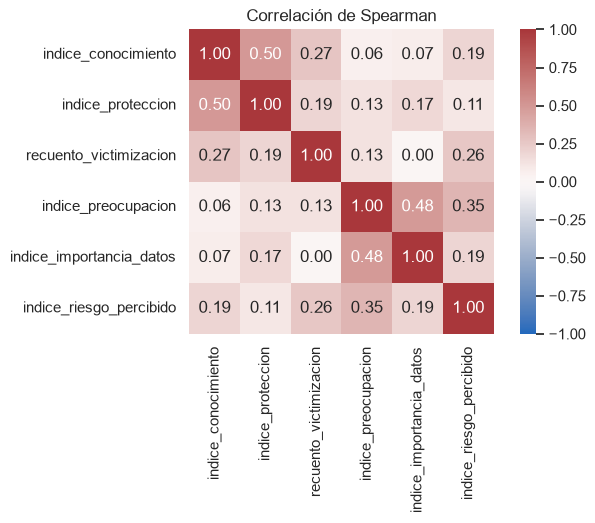

,indice_conocimiento,indice_proteccion,recuento_victimizacion,indice_preocupacion,indice_importancia_datos,indice_riesgo_percibido
indice_conocimiento,1.000,0.495,0.273,0.058,0.072,0.195
indice_proteccion,0.495,1.000,0.193,0.128,0.173,0.105
recuento_victimizacion,0.273,0.193,1.000,0.131,0.004,0.260
indice_preocupacion,0.058,0.128,0.131,1.000,0.485,0.349
indice_importancia_datos,0.072,0.173,0.004,0.485,1.000,0.191
indice_riesgo_percibido,0.195,0.105,0.260,0.349,0.191,1.000


In [38]:
matriz = datos[variables_clave].apply(pd.to_numeric, errors="coerce") if variables_clave else pd.DataFrame()
if matriz.shape[1] >= 2:
    for metodo, titulo in [("pearson", "Correlación de Pearson"), ("spearman", "Correlación de Spearman")]:
        corr = matriz.corr(method=metodo, min_periods=3)
        plt.figure(figsize=(max(7, 1.2 * len(corr.columns)), max(5, 0.9 * len(corr.columns))))
        sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, cmap="vlag", square=True)
        plt.title(titulo)
        plt.tight_layout()
        plt.show()
        display(corr.round(3))
else:
    print("No hay al menos dos índices numéricos disponibles para calcular correlaciones.")

## 37. Pairplot de los índices principales

El pairplot combina histogramas/densidades en la diagonal con diagramas de dispersión entre pares. Para mantener un tiempo de ejecución razonable, se toma una muestra aleatoria de hasta 2.000 registros; la muestra se fija con `random_state=42` para reproducibilidad.

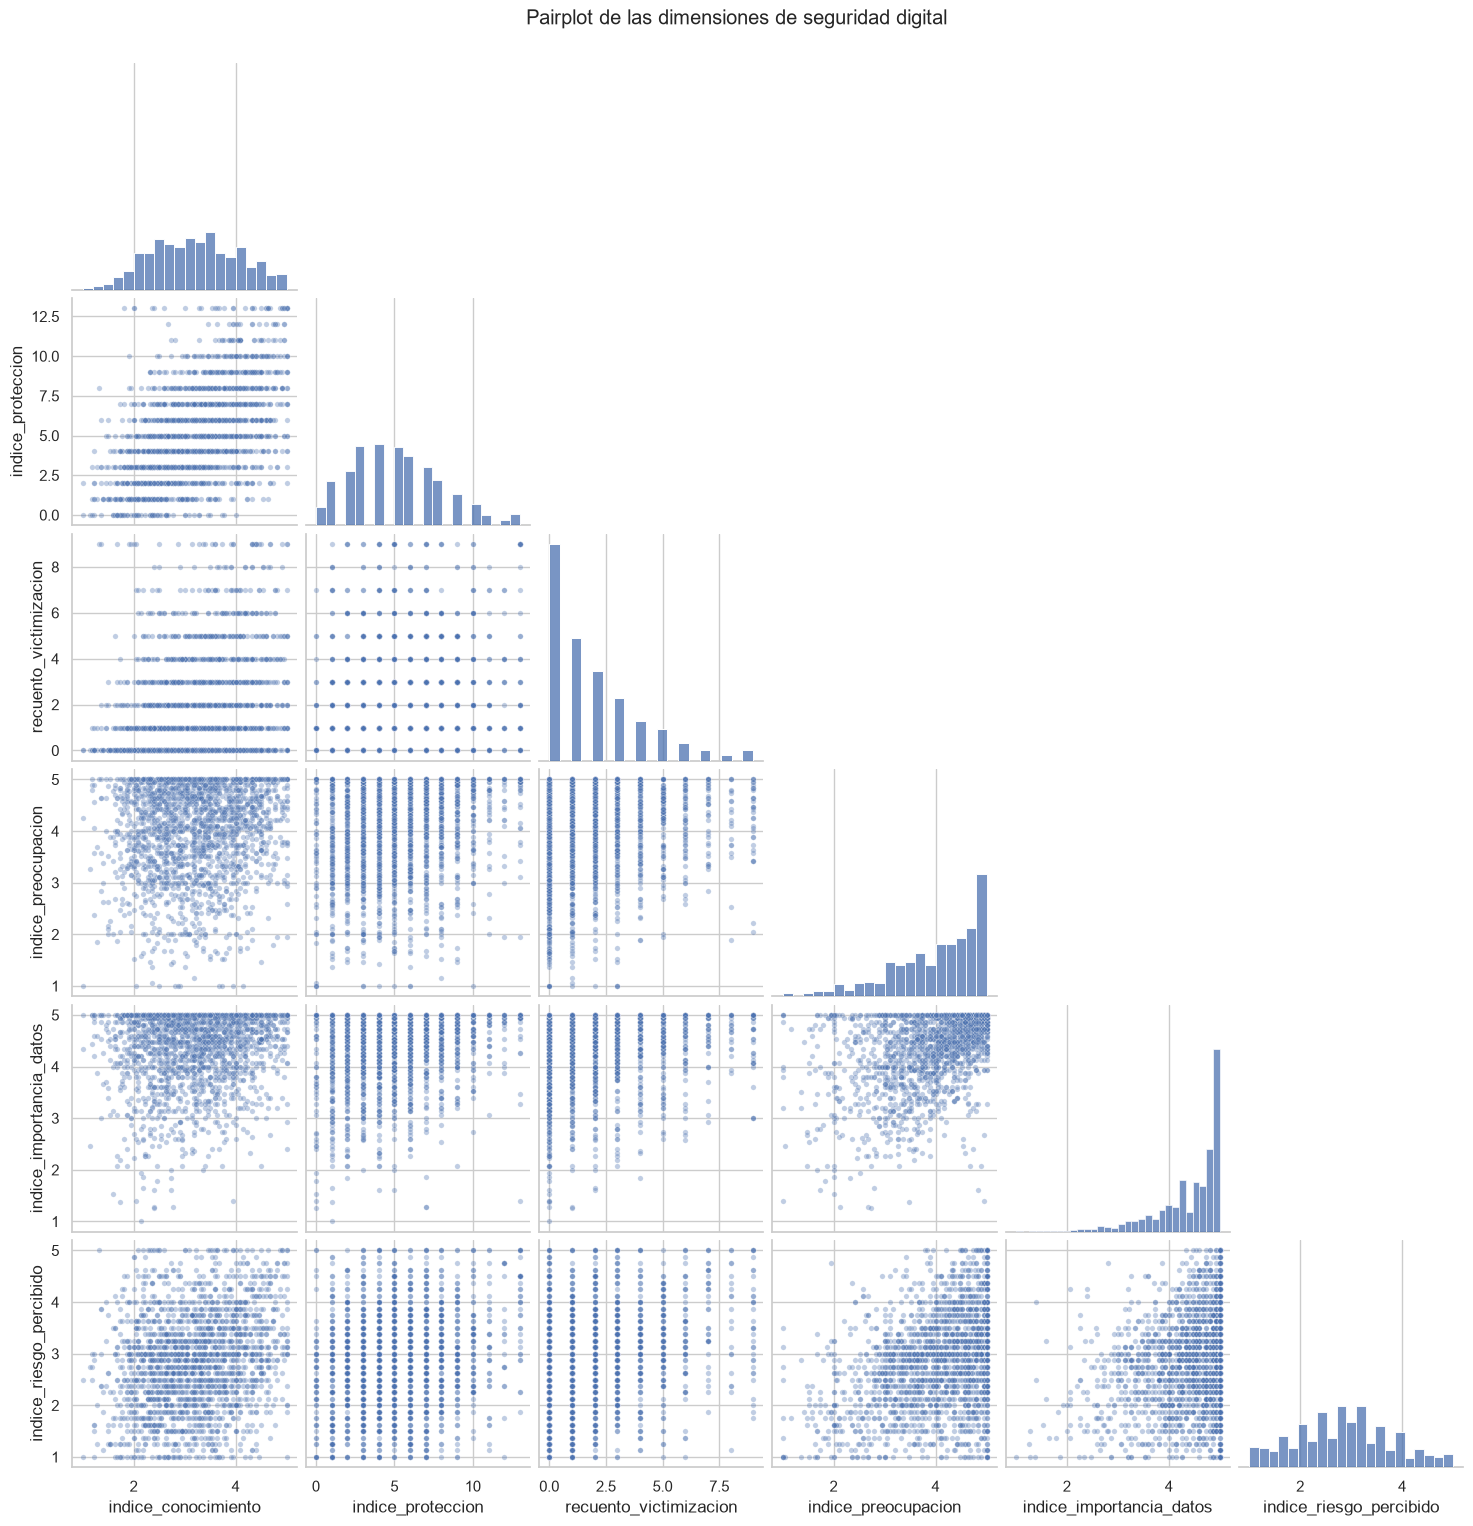

In [39]:
vars_pair = [v for v in ["indice_conocimiento", "indice_proteccion", "recuento_victimizacion",
                         "indice_preocupacion", "indice_importancia_datos", "indice_riesgo_percibido"]
             if v in datos.columns]
if len(vars_pair) >= 2:
    pairdata = datos[vars_pair].apply(pd.to_numeric, errors="coerce").dropna(how="all")
    if len(pairdata) > 2000:
        pairdata = pairdata.sample(2000, random_state=42)
    if len(pairdata) > 1:
        g = sns.pairplot(pairdata, diag_kind="hist", corner=True, plot_kws={"alpha": 0.35, "s": 15})
        g.fig.suptitle("Pairplot de las dimensiones de seguridad digital", y=1.02)
        plt.show()
else:
    print("No hay suficientes índices para construir el pairplot.")

Comparación de grupos: pruebas de hipótesis y análisis de varianza

Se realiza el análisis exploratorio con comparaciones inferenciales entre grupos. Se reportan tamaños del efecto e intervalos de confianza del 95 % junto con los valores *p*. Debido al tamaño de la muestra, la significación estadística no se interpretará por sí sola como relevancia práctica.

## 38. Hipótesis de investigación

Se plantean tres (3) hipótesis que derivan de la pregunta analítica rectora y de las variables disponibles en el diccionario.

**Hipótesis 1 — Experiencia en TI y conocimiento declarado - Existen diferencias en el nivel de conocimiento sobre seguridad digital entre las personas con experiencia en TI y las personas sin experiencia en TI.**

- \(H_0\): la distribución del índice de conocimiento es igual entre quienes reportan experiencia práctica o formación en TI y quienes no la reportan.
- \(H_1\): la distribución del índice de conocimiento difiere entre ambos grupos.

**Hipótesis 2 — Experiencia en TI y comportamiento protector - Existen diferencias en la cantidad de medidas de protección digital utilizadas entre las personas con experiencia en TI y las personas sin experiencia en TI.**

- \(H_0\): la distribución del índice de comportamiento protector es igual entre quienes reportan experiencia práctica o formación en TI y quienes no la reportan.
- \(H_1\): la distribución del índice de comportamiento protector difiere entre ambos grupos.

**Hipótesis 3 — Diferencias entre países en conocimiento declarado - Existen diferencias en el nivel de conocimiento sobre seguridad digital entre los participantes de los distintos países.**

- \(H_0\): la distribución del índice de conocimiento es igual en los 12 países.
- \(H_1\): al menos un país presenta una distribución diferente.

En `q25`, el código 1 corresponde a Sí y 2 a No. Se excluyen los valores faltantes y códigos inesperados de estas comparaciones. Para el índice de protección se utiliza la suma de las medidas `q20r2`–`q20r14`; `q20r1` (“ninguna medida”) no se suma porque es una opción excluyente.

In [40]:
# Preparar variables de agrupación y validar códigos antes de realizar inferencia.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests

# Asegurar que los índices requeridos existan si se ejecuta esta sección después de reiniciar el kernel.
if "indice_conocimiento" not in datos.columns:
    items_conocimiento = [f"q6r{i}" for i in range(1, 23) if f"q6r{i}" in datos.columns]
    datos[items_conocimiento] = datos[items_conocimiento].apply(pd.to_numeric, errors="coerce")
    datos["n_items_conocimiento"] = datos[items_conocimiento].notna().sum(axis=1)
    datos["indice_conocimiento"] = datos[items_conocimiento].mean(axis=1)
    datos.loc[datos["n_items_conocimiento"] < 18, "indice_conocimiento"] = np.nan

if "indice_proteccion" not in datos.columns:
    items_proteccion = [f"q20r{i}" for i in range(2, 15) if f"q20r{i}" in datos.columns]
    datos[items_proteccion] = datos[items_proteccion].apply(pd.to_numeric, errors="coerce")
    datos["indice_proteccion"] = datos[items_proteccion].sum(axis=1, min_count=1)

# Etiquetar los grupos de q25; no convertir los códigos inesperados en una categoría válida.
datos["experiencia_TI"] = datos["q25"].map({1: "Con experiencia en TI", 2: "Sin experiencia en TI"})
datos["Pais"] = datos["Country"].map({
    1: "China", 2: "Alemania", 3: "India", 4: "Israel", 5: "Italia",
    6: "México", 7: "Polonia", 8: "Arabia Saudita", 9: "Sudáfrica",
    10: "Suecia", 11: "Reino Unido", 12: "Estados Unidos"
})

print("Tamaño total del dataset:", len(datos))
print("Casos válidos de q25 por grupo:")
display(datos["experiencia_TI"].value_counts(dropna=False).rename_axis("Grupo").to_frame("N"))
print("Resumen de índices por experiencia en TI:")
display(
    datos.groupby("experiencia_TI", observed=False)[["indice_conocimiento", "indice_proteccion"]]
    .agg(["count", "mean", "median", "std"]).round(3)
)

Tamaño total del dataset: 12351
Casos válidos de q25 por grupo:


C:\Users\adria\AppData\Local\Temp\ipykernel_20012\233280658.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  datos["experiencia_TI"] = datos["q25"].map({1: "Con experiencia en TI", 2: "Sin experiencia en TI"})
C:\Users\adria\AppData\Local\Temp\ipykernel_20012\233280658.py:25: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  datos["Pais"] = datos["Country"].map({


,N
Grupo,
Sin experiencia en TI,7483
Con experiencia en TI,4573
NaN,295


Resumen de índices por experiencia en TI:


indice_conocimiento                       \
                                    count   mean median    std   
experiencia_TI                                                   
Con experiencia en TI                4573  3.573  3.636  0.799   
Sin experiencia en TI                7483  2.979  2.955  0.783   

                      indice_proteccion                       
                                  count   mean median    std  
experiencia_TI                                                
Con experiencia en TI              4573  5.977    6.0  2.921  
Sin experiencia en TI              7483  4.574    4.0  2.649

## 39. Comparaciones entre dos grupos: supuestos, prueba, tamaño del efecto e IC del 95 %

Se comparan las puntuaciones de quienes reportan experiencia en TI (q25 = 1) y quienes no la reportan (q25 = 2). Se revisan normalidad mediante Shapiro–Wilk y gráficos Q–Q, y homogeneidad de varianzas mediante Levene.

Se reportan la diferencia de medias con IC bootstrap del 95 %, la *d* de Cohen con IC bootstrap del 95 % y, para Mann–Whitney, la correlación biserial por rangos como medida adicional. Los intervalos bootstrap se estiman con remuestreo independiente dentro de cada grupo y semilla fija para reproducibilidad.

In [41]:
# Funciones reutilizables para comparar dos grupos y estimar IC del 95 % mediante bootstrap.
def _shapiro_p(x, semilla=42):
    x = pd.Series(x).dropna().to_numpy(dtype=float)
    if len(x) < 3:
        return np.nan
    # Shapiro–Wilk admite hasta 5.000 observaciones en SciPy; muestrear evita un test desproporcionadamente sensible.
    if len(x) > 5000:
        rng = np.random.default_rng(semilla)
        x = rng.choice(x, size=5000, replace=False)
    return float(stats.shapiro(x).pvalue)

def _cohen_d(x, y):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    nx, ny = len(x), len(y)
    if nx < 2 or ny < 2:
        return np.nan
    pooled_var = ((nx - 1) * np.var(x, ddof=1) + (ny - 1) * np.var(y, ddof=1)) / (nx + ny - 2)
    pooled_sd = np.sqrt(pooled_var)
    return (np.mean(x) - np.mean(y)) / pooled_sd if pooled_sd > 0 else np.nan

def comparar_dos_grupos(data, variable, variable_grupo="experiencia_TI",
                        orden=("Con experiencia en TI", "Sin experiencia en TI"),
                        n_boot=500, semilla=2026):
    temp = data[[variable, variable_grupo]].copy()
    temp[variable] = pd.to_numeric(temp[variable], errors="coerce")
    temp = temp.dropna()
    grupos = [temp.loc[temp[variable_grupo] == g, variable].to_numpy(dtype=float) for g in orden]
    x, y = grupos[0], grupos[1]
    if min(len(x), len(y)) < 3:
        raise ValueError(f"No hay suficientes observaciones válidas para comparar {variable}.")

    p_shapiro_x = _shapiro_p(x, semilla)
    p_shapiro_y = _shapiro_p(y, semilla + 1)
    p_levene = float(stats.levene(x, y, center="median").pvalue)
    normalidad_plausible = (p_shapiro_x > .05) and (p_shapiro_y > .05)
    if normalidad_plausible and p_levene > .05:
        prueba = "t de Student independiente"
        res = stats.ttest_ind(x, y, equal_var=True, nan_policy="omit")
    elif normalidad_plausible and p_levene <= .05:
        prueba = "t de Welch"
        res = stats.ttest_ind(x, y, equal_var=False, nan_policy="omit")
    else:
        prueba = "Mann–Whitney U"
        res = stats.mannwhitneyu(x, y, alternative="two-sided", method="asymptotic")

    # Bootstrap estratificado para IC de diferencia de medias, d de Cohen y correlación biserial por rangos.
    rng = np.random.default_rng(semilla)
    difs, ds, rbc = [], [], []
    for _ in range(n_boot):
        xb = rng.choice(x, size=len(x), replace=True)
        yb = rng.choice(y, size=len(y), replace=True)
        difs.append(np.mean(xb) - np.mean(yb))
        ds.append(_cohen_d(xb, yb))
        u = stats.mannwhitneyu(xb, yb, alternative="two-sided", method="asymptotic").statistic
        rbc.append(2 * u / (len(xb) * len(yb)) - 1)
    ic_dif = np.nanpercentile(difs, [2.5, 97.5])
    ic_d = np.nanpercentile(np.asarray(ds)[np.isfinite(ds)], [2.5, 97.5])
    ic_rbc = np.nanpercentile(rbc, [2.5, 97.5])

    salida = {
        "Variable": variable,
        "Grupo 1": orden[0], "N grupo 1": len(x), "Media grupo 1": np.mean(x), "Mediana grupo 1": np.median(x),
        "Grupo 2": orden[1], "N grupo 2": len(y), "Media grupo 2": np.mean(y), "Mediana grupo 2": np.median(y),
        "Shapiro p (grupo 1)": p_shapiro_x, "Shapiro p (grupo 2)": p_shapiro_y,
        "Levene p": p_levene, "Prueba seleccionada": prueba,
        "Estadístico": float(res.statistic), "p": float(res.pvalue),
        "Diferencia de medias (G1-G2)": float(np.mean(x) - np.mean(y)),
        "IC95% diferencia inferior": float(ic_dif[0]), "IC95% diferencia superior": float(ic_dif[1]),
        "d de Cohen": float(_cohen_d(x, y)),
        "IC95% d inferior": float(ic_d[0]), "IC95% d superior": float(ic_d[1]),
        "Biserial por rangos": float(2 * res.statistic / (len(x) * len(y)) - 1) if prueba == "Mann–Whitney U" else np.nan,
        "IC95% biserial inferior": float(ic_rbc[0]), "IC95% biserial superior": float(ic_rbc[1])
    }
    return salida, (x, y)

resultados_dos_grupos = []
muestras_dos_grupos = {}
for variable in ["indice_conocimiento", "indice_proteccion"]:
    resultado, muestras = comparar_dos_grupos(datos, variable)
    resultados_dos_grupos.append(resultado)
    muestras_dos_grupos[variable] = muestras

tabla_dos_grupos = pd.DataFrame(resultados_dos_grupos)
tabla_dos_grupos["p reportada"] = tabla_dos_grupos["p"].apply(
    lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}"
)
display(tabla_dos_grupos.round(4))

,Variable,Grupo 1,N grupo 1,Media grupo 1,Mediana grupo 1,Grupo 2,N grupo 2,Media grupo 2,Mediana grupo 2,Shapiro p (grupo 1),Shapiro p (grupo 2),Levene p,Prueba seleccionada,Estadístico,p,Diferencia de medias (G1-G2),IC95% diferencia inferior,IC95% diferencia superior,d de Cohen,IC95% d inferior,IC95% d superior,Biserial por rangos,IC95% biserial inferior,IC95% biserial superior,p reportada
0,indice_conocimiento,Con experiencia en TI,4573,3.5730,3.6364,Sin experiencia en TI,7483,2.9789,2.9545,0.0,0.0,0.1058,Mann–Whitney U,24096436.0,0.0,0.5940,0.5676,0.6253,0.7530,0.7170,0.7928,0.4083,0.3902,0.4280,< 0.001
1,indice_proteccion,Con experiencia en TI,4573,5.9768,6.0000,Sin experiencia en TI,7483,4.5742,4.0000,0.0,0.0,0.0000,Mann–Whitney U,21762691.0,0.0,1.4026,1.2984,1.5091,0.5091,0.4698,0.5475,0.2719,0.2524,0.2925,< 0.001


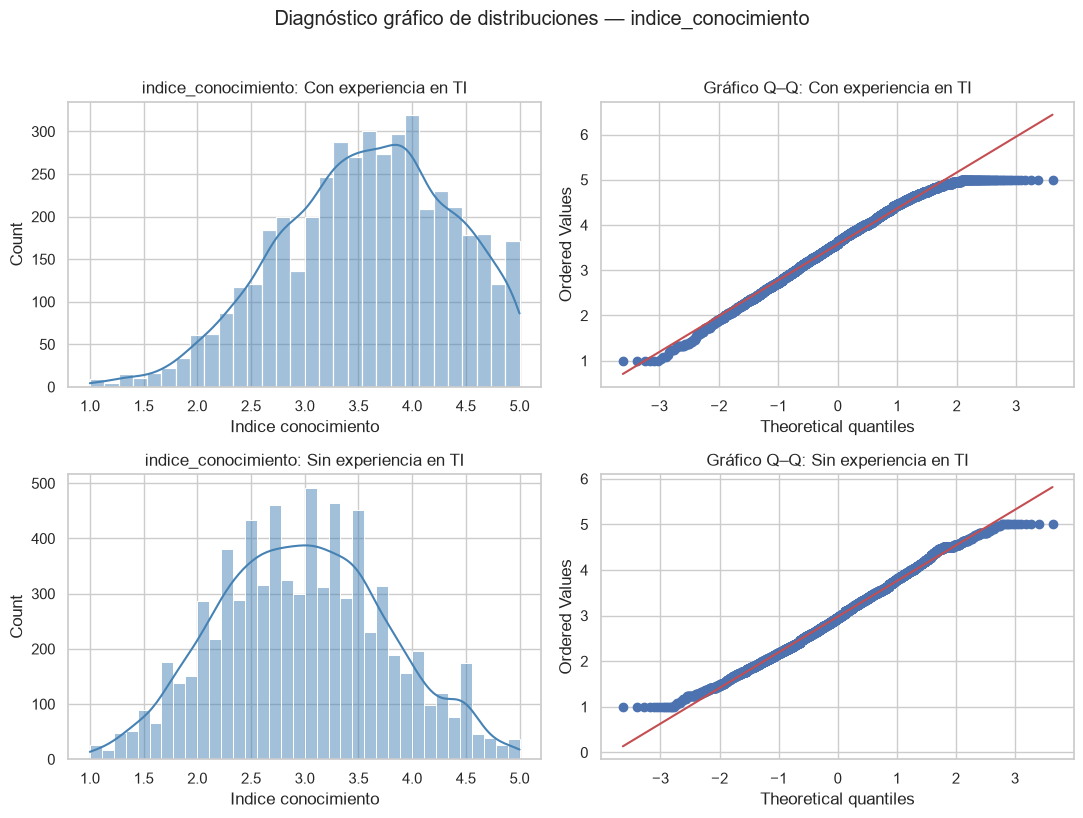

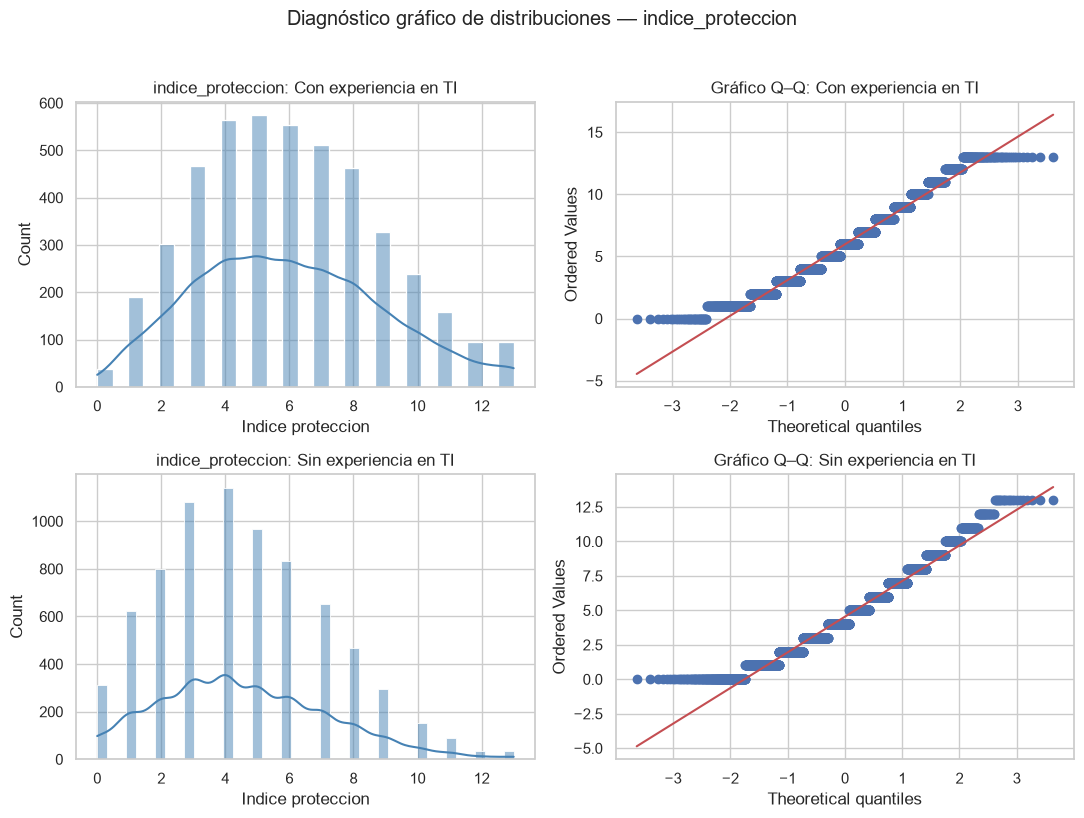

In [42]:
# Inspección gráfica de normalidad para cada comparación: histogramas y gráficos Q–Q por grupo.
for variable, (x, y) in muestras_dos_grupos.items():
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    for fila, (grupo, valores) in enumerate([
        ("Con experiencia en TI", x), ("Sin experiencia en TI", y)
    ]):
        sns.histplot(valores, bins="auto", kde=True, ax=axes[fila, 0], color="steelblue")
        axes[fila, 0].set_title(f"{variable}: {grupo}")
        axes[fila, 0].set_xlabel(variable.replace("_", " ").capitalize())
        stats.probplot(valores if len(valores) <= 5000 else np.random.default_rng(42).choice(valores, 5000, replace=False),
                       dist="norm", plot=axes[fila, 1])
        axes[fila, 1].set_title(f"Gráfico Q–Q: {grupo}")
    fig.suptitle(f"Diagnóstico gráfico de distribuciones — {variable}", y=1.02)
    fig.tight_layout()
    plt.show()

## 40. Comparación de más de dos grupos: diferencias entre países

Se compara el índice de conocimiento declarado entre los 12 países. Se revisan los tamaños muestrales, Shapiro–Wilk por país y Levene. Si la normalidad y la homogeneidad de varianzas son plausibles, se aplica ANOVA de un factor y, si resulta significativo, Tukey HSD. Si no se cumplen los supuestos, se utiliza Kruskal–Wallis y, cuando es significativo, comparaciones pareadas de Mann–Whitney con corrección de Holm.

In [43]:
# Preparación de los 12 grupos de país y diagnóstico de supuestos.
temp_paises = datos[["Pais", "indice_conocimiento"]].copy()
temp_paises["indice_conocimiento"] = pd.to_numeric(temp_paises["indice_conocimiento"], errors="coerce")
temp_paises = temp_paises.dropna()
grupos_pais = {
    pais: grupo["indice_conocimiento"].to_numpy(dtype=float)
    for pais, grupo in temp_paises.groupby("Pais", observed=True)
}
grupos_pais = {pais: valores for pais, valores in grupos_pais.items() if len(valores) >= 3}
orden_paises = list(grupos_pais.keys())

tabla_resumen_paises = (
    temp_paises.groupby("Pais", observed=True)["indice_conocimiento"]
    .agg(N="count", Media="mean", Mediana="median", Desviacion="std")
    .sort_values("Media", ascending=False)
)
display(tabla_resumen_paises.round(3))

p_shapiro_pais = {pais: _shapiro_p(valores, 100 + i) for i, (pais, valores) in enumerate(grupos_pais.items())}
p_levene_pais = float(stats.levene(*grupos_pais.values(), center="median").pvalue)
normalidad_paises = all(p > .05 for p in p_shapiro_pais.values())
print("p-valores Shapiro–Wilk por país:")
display(pd.Series(p_shapiro_pais, name="p Shapiro–Wilk").to_frame().round(5))
print("Levene p:", round(p_levene_pais, 6))
print("Normalidad plausible en todos los grupos:", normalidad_paises)

,N,Media,Mediana,Desviacion
Pais,,,,
India,1011,3.588,3.682,0.825
Sudáfrica,1048,3.394,3.409,0.773
China,1008,3.379,3.364,0.827
Polonia,1054,3.259,3.318,0.831
Arabia Saudita,1018,3.181,3.136,0.853
Italia,1019,3.174,3.182,0.834
Israel,1011,3.120,3.091,0.849
Estados Unidos,1051,3.120,3.091,0.820
Alemania,1019,3.094,3.091,0.846


p-valores Shapiro–Wilk por país:


,p Shapiro–Wilk
Alemania,0.00005
Arabia Saudita,0.00001
China,0.00000
Estados Unidos,0.00109
India,0.00000
Israel,0.00000
Italia,0.00033
México,0.00000
Polonia,0.00009
Reino Unido,0.00398


Levene p: 0.003272
Normalidad plausible en todos los grupos: False


In [44]:
# Seleccionar ANOVA o Kruskal–Wallis según los diagnósticos.
if normalidad_paises and p_levene_pais > .05:
    prueba_paises = "ANOVA de un factor"
    resultado_paises = stats.f_oneway(*[grupos_pais[p] for p in orden_paises])
    estadistico_paises, p_paises = float(resultado_paises.statistic), float(resultado_paises.pvalue)
    todos = np.concatenate([grupos_pais[p] for p in orden_paises])
    media_global = todos.mean()
    ss_total = np.sum((todos - media_global) ** 2)
    ss_entre = sum(len(grupos_pais[p]) * (np.mean(grupos_pais[p]) - media_global) ** 2 for p in orden_paises)
    efecto_paises = ss_entre / ss_total if ss_total > 0 else np.nan
    nombre_efecto_paises = "Eta cuadrado (η²)"
else:
    prueba_paises = "Kruskal–Wallis"
    resultado_paises = stats.kruskal(*[grupos_pais[p] for p in orden_paises], nan_policy="omit")
    estadistico_paises, p_paises = float(resultado_paises.statistic), float(resultado_paises.pvalue)
    n_total = sum(len(grupos_pais[p]) for p in orden_paises)
    k = len(orden_paises)
    efecto_paises = max(0.0, (estadistico_paises - k + 1) / (n_total - k))
    nombre_efecto_paises = "Epsilon cuadrado (ε²)"

# IC bootstrap del tamaño del efecto, preservando los tamaños de los grupos por país.
rng = np.random.default_rng(2026)
efectos_boot = []
for _ in range(300):
    boot_grupos = {
        p: rng.choice(grupos_pais[p], size=len(grupos_pais[p]), replace=True)
        for p in orden_paises
    }
    if prueba_paises == "ANOVA de un factor":
        valores = np.concatenate([boot_grupos[p] for p in orden_paises])
        media = valores.mean()
        sst = np.sum((valores - media) ** 2)
        ssb = sum(len(boot_grupos[p]) * (np.mean(boot_grupos[p]) - media) ** 2 for p in orden_paises)
        eff = ssb / sst if sst > 0 else np.nan
    else:
        h = stats.kruskal(*[boot_grupos[p] for p in orden_paises]).statistic
        eff = max(0.0, (h - len(orden_paises) + 1) / (sum(len(boot_grupos[p]) for p in orden_paises) - len(orden_paises)))
    efectos_boot.append(eff)
ic_efecto_paises = np.nanpercentile(np.asarray(efectos_boot)[np.isfinite(efectos_boot)], [2.5, 97.5])

tabla_prueba_paises = pd.DataFrame([{
    "Variable": "indice_conocimiento", "Número de países": len(orden_paises),
    "Prueba seleccionada": prueba_paises, "Estadístico": estadistico_paises, "p": p_paises,
    "Tamaño del efecto": efecto_paises, "Medida del efecto": nombre_efecto_paises,
    "IC95% efecto inferior": ic_efecto_paises[0], "IC95% efecto superior": ic_efecto_paises[1]
}])
tabla_prueba_paises["p reportada"] = tabla_prueba_paises["p"].apply(
    lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}"
)
display(tabla_prueba_paises.round(5))

# Post-hoc solo cuando la prueba global indica evidencia de diferencias.
if p_paises < .05:
    if prueba_paises == "ANOVA de un factor":
        tukey = pairwise_tukeyhsd(
            endog=temp_paises["indice_conocimiento"],
            groups=temp_paises["Pais"], alpha=.05
        )
        print("Comparaciones post-hoc Tukey HSD:")
        display(pd.DataFrame(data=tukey._results_table.data[1:], columns=tukey._results_table.data[0]))
    else:
        pares = []
        for i, pais_a in enumerate(orden_paises):
            for pais_b in orden_paises[i+1:]:
                xa, xb = grupos_pais[pais_a], grupos_pais[pais_b]
                r = stats.mannwhitneyu(xa, xb, alternative="two-sided", method="asymptotic")
                pares.append({"País A": pais_a, "País B": pais_b, "N A": len(xa), "N B": len(xb),
                              "U": r.statistic, "p sin ajustar": r.pvalue,
                              "Diferencia de medianas": np.median(xa) - np.median(xb)})
        posthoc_paises = pd.DataFrame(pares)
        posthoc_paises["p ajustado Holm"] = multipletests(posthoc_paises["p sin ajustar"], method="holm")[1]
        posthoc_significativos = posthoc_paises.loc[posthoc_paises["p ajustado Holm"] < .05].copy()
        print(f"Comparaciones pareadas significativas tras corrección de Holm: {len(posthoc_significativos)} de {len(posthoc_paises)}")
        display(posthoc_significativos.sort_values("p ajustado Holm").round(5))
else:
    print("La prueba global no fue significativa al nivel .05; no se ejecutan comparaciones post-hoc.")

,Variable,Número de países,Prueba seleccionada,Estadístico,p,Tamaño del efecto,Medida del efecto,IC95% efecto inferior,IC95% efecto superior,p reportada
0,indice_conocimiento,12,Kruskal–Wallis,484.69264,0.0,0.03839,Epsilon cuadrado (ε²),0.03212,0.0452,< 0.001


Comparaciones pareadas significativas tras corrección de Holm: 40 de 66


,País A,País B,N A,N B,U,p sin ajustar,Diferencia de medianas,p ajustado Holm
44,India,Suecia,1011,1049,748464.5,0.00000,0.72727,0.00000
40,India,México,1011,1045,721299.5,0.00000,0.68182,0.00000
42,India,Reino Unido,1011,1018,695813.5,0.00000,0.59091,0.00000
3,Alemania,India,1019,1011,344109.5,0.00000,-0.59091,0.00000
30,Estados Unidos,India,1051,1011,360198.5,0.00000,-0.59091,0.00000
38,India,Israel,1011,1011,673278.5,0.00000,0.59091,0.00000
65,Sudáfrica,Suecia,1048,1049,711063.5,0.00000,0.45455,0.00000
39,India,Italia,1011,1019,662578.5,0.00000,0.50000,0.00000
13,Arabia Saudita,India,1018,1011,369328.0,0.00000,-0.54545,0.00000
29,China,Suecia,1008,1049,669590.0,0.00000,0.40909,0.00000


## 41. Interpretación de resultados y cautelas

## A. Hipótesis 1: diferencias en el conocimiento sobre seguridad digital según la experiencia en TI

### A.1. Formulación de hipótesis

**Hipótesis nula (H₀):** no existen diferencias en el nivel de conocimiento sobre seguridad digital entre las personas con experiencia en tecnologías de información (TI) y las personas sin experiencia en TI.

**Hipótesis alternativa (H₁):** existen diferencias en el nivel de conocimiento sobre seguridad digital entre las personas con experiencia en TI y las personas sin experiencia en TI.

### A.2. Diferencias descriptivas entre los grupos

El grupo con experiencia en TI presentó una media de 3,573 y una mediana de 3,636, mientras que el grupo sin experiencia en TI presentó una media de 2,979 y una mediana de 2,955. La diferencia de medias fue de 0,594 puntos y la diferencia de medianas fue de 0,682 puntos.

Estos resultados indican que, en la muestra analizada, las personas con experiencia en TI obtuvieron puntuaciones más altas en el índice de conocimiento sobre seguridad digital.

### A.3. Selección de la prueba estadística

Se seleccionó la prueba U de Mann–Whitney para comparar las distribuciones de los dos grupos. La prueba de Shapiro–Wilk indicó desviaciones de la normalidad en ambos grupos (p < 0,001). Los gráficos Q–Q permiten inspeccionar visualmente estas desviaciones y complementar la evaluación de la distribución.

La prueba de Levene obtuvo un valor p = 0,1058, por lo que no se encontró evidencia suficiente para rechazar la igualdad de varianzas al nivel de significación del 5 %. Sin embargo, este resultado no demuestra que las distribuciones sean normales.

La prueba U de Mann–Whitney presentó un resultado estadísticamente significativo (p < 0,001), lo que indica evidencia de diferencias entre las distribuciones de las puntuaciones de conocimiento digital.

### A.4. Tamaño del efecto e importancia práctica

La d de Cohen fue de 0,753, con un intervalo de confianza del 95 % entre 0,717 y 0,793. De acuerdo con los umbrales orientativos habituales, este resultado representa un efecto moderado a grande, cercano al valor de referencia de 0,80.

La correlación biserial por rangos fue de 0,408, con un intervalo de confianza del 95 % entre 0,390 y 0,428. Esta medida complementa la comparación y muestra una separación apreciable entre los grupos.

Aunque la d de Cohen es útil para expresar la diferencia en unidades estandarizadas, debe interpretarse junto con las medianas y las distribuciones, dado que la prueba principal seleccionada fue no paramétrica.

### A.5. Intervalo de confianza del 95 %

El intervalo de confianza del 95 % para la diferencia de medias fue [0,568; 0,625]. Como el intervalo es completamente positivo, los resultados son compatibles con una mayor puntuación media en el grupo con experiencia en TI.

La amplitud relativamente reducida del intervalo indica una estimación bastante precisa de la diferencia de medias para la muestra y el procedimiento de remuestreo empleados. Este intervalo no garantiza que la diferencia sea idéntica en otras poblaciones.

### A.6. Conclusión de la hipótesis 1

Los resultados proporcionan evidencia de diferencias en el conocimiento declarado sobre seguridad digital según la experiencia en TI. La diferencia observada tiene una magnitud estandarizada moderada a grande. Sin embargo, debido al carácter observacional del estudio, no se puede concluir que la experiencia en TI sea por sí sola la causa de las puntuaciones más altas.



## B. Hipótesis 2: diferencias en las medidas de protección digital según la experiencia en TI

### B.1. Formulación de hipótesis

**Hipótesis nula (H₀):** no existen diferencias en la cantidad de medidas de protección digital utilizadas entre las personas con experiencia en TI y las personas sin experiencia en TI.

**Hipótesis alternativa (H₁):** existen diferencias en la cantidad de medidas de protección digital utilizadas entre las personas con experiencia en TI y las personas sin experiencia en TI.

### B.2. Diferencias descriptivas entre los grupos

El grupo con experiencia en TI presentó una media de 5,977 y una mediana de 6 medidas de protección. El grupo sin experiencia en TI presentó una media de 4,574 y una mediana de 4 medidas.

La diferencia de medias fue de aproximadamente 1,403 medidas, mientras que la diferencia de medianas fue de 2 medidas. Descriptivamente, las personas con experiencia en TI reportaron utilizar una mayor cantidad de medidas de protección digital.

### B.3. Selección de la prueba estadística

Se seleccionó la prueba U de Mann–Whitney para comparar las distribuciones de ambos grupos. La prueba de Shapiro–Wilk indicó desviaciones de la normalidad (p < 0,001). Los gráficos Q–Q deben utilizarse para complementar la evaluación visual de las distribuciones.

La prueba de Levene obtuvo p < 0,001, lo que proporciona evidencia de diferencias entre las varianzas de los grupos. La prueba U de Mann–Whitney resultó estadísticamente significativa (p < 0,001).

Se encontró evidencia de diferencias entre las distribuciones del número de medidas de protección declaradas por los dos grupos.

### B.4. Tamaño del efecto e importancia práctica

La d de Cohen fue de 0,509, con un intervalo de confianza del 95 % entre 0,470 y 0,548. Según las referencias orientativas habituales, este resultado representa un efecto moderado.

La correlación biserial por rangos fue de 0,272, con un intervalo de confianza del 95 % entre 0,252 y 0,293. Esta medida indica una separación apreciable entre las distribuciones, aunque menor que la observada para el índice de conocimiento digital.

La experiencia en TI está asociada con una mayor cantidad de medidas de protección declaradas. No obstante, la magnitud del efecto sugiere que otros factores también podrían estar relacionados con los comportamientos de protección.

### B.5. Intervalo de confianza del 95 %

El intervalo de confianza del 95 % para la diferencia de medias fue [1,298; 1,509]. El intervalo es completamente positivo, lo que respalda una diferencia media favorable al grupo con experiencia en TI dentro de la muestra analizada.

Su amplitud relativamente reducida indica una estimación precisa para los datos analizados, aunque no elimina las limitaciones derivadas del autorreporte, la construcción del índice y el diseño muestral.

### B.6. Conclusión de la hipótesis 2

Los resultados muestran evidencia de una asociación entre la experiencia en TI y una mayor utilización declarada de medidas de protección digital. El tamaño del efecto es moderado. No se puede afirmar que la experiencia en TI cause directamente este comportamiento, puesto que el diseño observacional no permite establecer causalidad.



## C. Hipótesis 3: diferencias en el conocimiento sobre seguridad digital entre países

### C.1. Formulación de hipótesis

**Hipótesis nula (H₀):** no existen diferencias en la distribución del índice de conocimiento sobre seguridad digital entre los participantes de los 12 países.

**Hipótesis alternativa (H₁):** al menos uno de los países presenta una distribución del índice de conocimiento diferente de la de otro país.

### C.2. Comparación descriptiva entre países

Entre los países analizados, India presentó una media de 3,588 y una mediana de 3,682, mientras que Suecia presentó una media de 2,989 y una mediana de 2,955.

La diferencia entre las medias fue de aproximadamente 0,599 puntos, y la diferencia entre las medianas fue de 0,727 puntos. Estas cifras muestran una diferencia descriptiva entre ambos países, pero no implican que todas las comparaciones entre países sean estadísticamente significativas.

### C.3. Selección de la prueba estadística

Se seleccionó la prueba de Kruskal–Wallis para comparar las distribuciones del índice de conocimiento entre los 12 países.

La prueba de Shapiro–Wilk indicó desviaciones de la normalidad en los grupos analizados (p < 0,05). La prueba de Levene obtuvo p = 0,003272, lo que indica evidencia de diferencias entre las varianzas de los países.

Los gráficos Q–Q permiten complementar visualmente la evaluación de las desviaciones de normalidad. El resultado de Kruskal–Wallis fue H = 484,693, con p < 0,001.

Se encontró evidencia estadística de diferencias entre las distribuciones del conocimiento digital de al menos algunos países. La prueba global no identifica por sí sola cuáles pares de países presentan diferencias.

### C.4. Tamaño del efecto global

El tamaño del efecto reportado fue ε² = 0,0384, con un intervalo de confianza del 95 % entre 0,0321 y 0,0452.

Este valor sugiere una magnitud global relativamente pequeña de las diferencias entre países. La interpretación de epsilon cuadrado para Kruskal–Wallis debe realizarse con cautela, considerando la definición utilizada en el notebook y las características de los datos.

Aunque el resultado global es estadísticamente significativo, esto no implica que las diferencias entre países tengan necesariamente una gran relevancia práctica. La magnitud debe valorarse junto con las diferencias observadas, sus intervalos de confianza y el contexto de seguridad digital.

### C.5. Comparaciones post hoc y corrección por multiplicidad

Después de la prueba global, se realizaron comparaciones pareadas mediante la prueba U de Mann–Whitney y se aplicó la corrección de Holm para controlar el error asociado a las comparaciones múltiples.

De las 66 comparaciones posibles entre los 12 países, 40 resultaron significativas después de la corrección.

Entre las comparaciones significativas se encuentran:

| Comparación | Diferencia de medianas (A − B) |
|---|---:|
| India – Suecia | 0,727 |
| India – México | 0,682 |
| India – Reino Unido | 0,591 |
| India – Israel | 0,591 |
| India – Italia | 0,500 |
| India – Polonia | 0,364 |
| Sudáfrica – Suecia | 0,455 |
| China – México | 0,364 |
| Sudáfrica – México | 0,409 |

En estas comparaciones, los valores p ajustados por Holm fueron inferiores a 0,05. Las diferencias positivas indican que la mediana del primer país es superior a la del segundo.

No todas las comparaciones fueron significativas: 26 de las 66 comparaciones no sobrevivieron a la corrección por multiplicidad. Por tanto, no se debe afirmar que todos los países difieren entre sí.

### C.6. Conclusión de la hipótesis 3

Los resultados indican diferencias estadísticamente significativas en el conocimiento declarado sobre seguridad digital entre países. Sin embargo, el tamaño del efecto global es relativamente pequeño. Las comparaciones post hoc muestran que las diferencias se concentran en determinados pares de países y que su relevancia práctica debe evaluarse teniendo en cuenta la magnitud de las diferencias y la representatividad de las muestras.



## D. Limitaciones del análisis

### D.1. Diseño transversal

El diseño transversal observa las variables en un momento determinado. Permite identificar asociaciones y diferencias, pero no establecer la secuencia temporal de los fenómenos ni demostrar relaciones causales.

### D.2. Autorreporte

Las variables de conocimiento y protección digital se construyen a partir de las respuestas de los participantes. Pueden existir sesgos de memoria, deseabilidad social o diferencias en la interpretación de las preguntas.

### D.3. Calidad de las respuestas

Los valores faltantes, las respuestas inconsistentes y los patrones de respuesta potencialmente poco fiables pueden afectar los índices analizados. La variable q13r11 puede utilizarse posteriormente para un análisis de sensibilidad relacionado con la calidad de respuesta. 

### D.4. Representatividad de las cuotas por país

Los tamaños de muestra relativamente similares entre países no garantizan que las muestras representen a sus respectivas poblaciones nacionales. Sin información suficiente sobre el diseño muestral, las probabilidades de inclusión y la cobertura de los participantes, no se deben generalizar automáticamente los resultados a todos los habitantes de cada país.

### D.5. Significación estadística y magnitud práctica

Las muestras grandes pueden facilitar la detección de diferencias pequeñas. Por ello, los valores p deben interpretarse junto con las diferencias de medias o medianas, los tamaños del efecto y los intervalos de confianza del 95 %.

En la muestra analizada, las personas que reportan experiencia en TI presentan puntuaciones más altas de conocimiento sobre seguridad digital y declaran utilizar más medidas de protección que quienes no reportan esa experiencia. Las diferencias estandarizadas son moderadas a grandes para el conocimiento (d = 0,753) y moderadas para las medidas de protección (d = 0,509).

También se identificaron diferencias estadísticamente significativas en el conocimiento declarado entre países. Sin embargo, el efecto global fue relativamente pequeño (ε² = 0,0384), y las comparaciones post hoc mostraron que las diferencias se concentran en determinados pares de países.

Estos resultados reflejan asociaciones observacionales y no demuestran causalidad. La interpretación debe considerar los intervalos de confianza, la calidad del autorreporte, la construcción de los índices y la representatividad del diseño muestral. Antes de elaborar el informe definitivo, es necesario ejecutar todas las celdas del notebook desde un kernel limpio y verificar que las tablas, los tamaños del efecto y los intervalos de confianza se reproduzcan con la configuración final.


## 42. Modelar relaciones: regresión lineal múltiple

Se analizan las relaciones entre el conocimiento sobre seguridad digital y un conjunto de variables explicativas disponibles en el dataset. El análisis permite examinar la asociación entre las variables seleccionadas, evaluar la capacidad explicativa del modelo e interpretar los coeficientes.

Para construir el modelo se selecciona una variable dependiente de naturaleza cuantitativa y un conjunto de variables independientes justificadas por su relación con el problema analítico. Esta selección se realiza teniendo en cuenta el diccionario de variables, la calidad de los datos, los resultados del análisis descriptivo y las relaciones identificadas entre las variables. 

Antes de estimar el modelo, se examinan las correlaciones entre las variables cuantitativas seleccionadas. Este procedimiento permite identificar posibles relaciones lineales y advertir asociaciones elevadas entre variables independientes.

El modelo de regresión lineal múltiple se utilizará para analizar la relación entre una variable dependiente y varias variables independientes.

La expresión general del modelo es:

$$
Y_i = \beta_0 + \beta_1 X_{i1} + \beta_2 X_{i2} + \cdots + \beta_k X_{ik} + \varepsilon_i
$$

Donde:

- $Y_i$: variable dependiente.
- $\beta_0$: intercepto del modelo.
- $\beta_j$: coeficientes de regresión.
- $X_{ij}$: variables independientes.
- $\varepsilon_i$: término de error aleatorio.

La selección definitiva de las variables dependerá de las características de la encuesta y del diccionario de variables.

Una vez seleccionadas las variables, se estima el modelo mediante mínimos cuadrados ordinarios (OLS). Se examinan los coeficientes, sus errores estándar, los valores p, los intervalos de confianza del 95 % y las medidas de ajuste.
La interpretación considerará tanto la significancia estadística como la magnitud y el sentido de los coeficientes, de acuerdo con la escala y la codificación de las variables.

In [45]:
# 1. Preparar las variables para la regresión lineal múltiple

import pandas as pd
import numpy as np

variable_dependiente = "indice_conocimiento"

variables_explicativas = [
    "indice_proteccion",
    "indice_preocupacion",
    "indice_importancia_datos",
    "indice_riesgo_percibido"
]

# Conservar solo las variables que existen en la base
variables_explicativas = [
    v for v in variables_explicativas if v in datos.columns
]

print("Variable dependiente:", variable_dependiente)
print("Variables explicativas disponibles:", variables_explicativas)

# Verificar que haya variables suficientes
if len(variables_explicativas) < 2:
    print("Se necesitan al menos dos variables explicativas disponibles.")
else:
    columnas_modelo = [variable_dependiente] + variables_explicativas

    datos_modelo = datos[columnas_modelo].copy()

    for columna in columnas_modelo:
        datos_modelo[columna] = pd.to_numeric(
            datos_modelo[columna], errors="coerce"
        )

    print("\nValores disponibles por variable:")
    display(datos_modelo.notna().sum().to_frame("Casos válidos"))

    # Revisar los casos completos que podrían entrar al modelo
    modelo_completo = datos_modelo.dropna()

    print("\nNúmero de casos completos:", len(modelo_completo))
    display(modelo_completo.describe().T.round(3))

Variable dependiente: indice_conocimiento
Variables explicativas disponibles: ['indice_proteccion', 'indice_preocupacion', 'indice_importancia_datos', 'indice_riesgo_percibido']

Valores disponibles por variable:


,Casos válidos
indice_conocimiento,12351
indice_proteccion,12351
indice_preocupacion,12282
indice_importancia_datos,12320
indice_riesgo_percibido,12351



Número de casos completos: 12263


,count,mean,std,min,25%,50%,75%,max
indice_conocimiento,12263.0,3.208,0.836,1.0,2.591,3.227,3.818,5.0
indice_proteccion,12263.0,5.119,2.837,0.0,3.000,5.000,7.000,13.0
indice_preocupacion,12263.0,3.953,0.879,1.0,3.368,4.105,4.684,5.0
indice_importancia_datos,12263.0,4.371,0.685,1.0,4.000,4.600,4.933,5.0
indice_riesgo_percibido,12263.0,2.843,0.905,1.0,2.250,2.875,3.500,5.0


## 43. Estimación del modelo de regresión lineal múltiple

A partir de las variables seleccionadas, se estima un modelo de regresión lineal múltiple mediante el método de mínimos cuadrados ordinarios (OLS). Se define el índice de conocimiento sobre seguridad digital como variable dependiente y los índices de protección, preocupación, importancia de los datos y riesgo percibido como variables explicativas.

La estimación permite examinar la dirección y magnitud de las asociaciones entre las variables, evaluar su significancia estadística mediante los valores p e intervalos de confianza del 95 %, y determinar la capacidad explicativa del modelo mediante el coeficiente de determinación (R²) y el R² ajustado. Asimismo, se evaluará la significancia global del modelo mediante la prueba F.

Los resultados obtenidos servirán como base para interpretar las relaciones identificadas y realizar posteriormente el diagnóstico de los supuestos estadísticos de la regresión.


In [46]:
import statsmodels.formula.api as smf

formula = (
    "indice_conocimiento ~ indice_proteccion + "
    "indice_preocupacion + indice_importancia_datos + "
    "indice_riesgo_percibido"
)

modelo = smf.ols(
    formula=formula,
    data=modelo_completo
).fit()

# Mostrar los resultados estadísticos
print(modelo.summary())

                             OLS Regression Results                            
Dep. Variable:     indice_conocimiento   R-squared:                       0.266
Model:                             OLS   Adj. R-squared:                  0.265
Method:                  Least Squares   F-statistic:                     1109.
Date:                 Sat, 31 Oct 2026   Prob (F-statistic):               0.00
Time:                         18:24:05   Log-Likelihood:                -13314.
No. Observations:                12263   AIC:                         2.664e+04
Df Residuals:                    12258   BIC:                         2.667e+04
Df Model:                            4                                         
Covariance Type:             nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept     

El modelo de regresión lineal múltiple presentó un coeficiente de determinación de R² = 0,266 y un R² ajustado de 0,265, lo que indica que las variables explicativas incluidas representan aproximadamente el 26,6 % de la variabilidad observada en el índice de conocimiento sobre seguridad digital. La prueba F mostró que el modelo es estadísticamente significativo en conjunto (p < 0,001).

En el análisis individual, el índice de protección y el índice de riesgo percibido presentaron coeficientes positivos y estadísticamente significativos. Por su parte, el índice de preocupación presentó una asociación negativa significativa. El índice de importancia de los datos no mostró evidencia estadística suficiente de asociación independiente con el índice de conocimiento (p = 0,414).

Estos resultados representan asociaciones condicionadas por las demás variables incluidas en el modelo y no permiten establecer relaciones causales. Su interpretación definitiva requiere evaluar los supuestos estadísticos y los posibles problemas de especificación del modelo.

Con el propósito de evaluar el supuesto de normalidad de los residuos del modelo de regresión lineal múltiple, se emplean dos herramientas gráficas: el histograma de los residuos y el gráfico de cuantiles teóricos (Q-Q). El histograma permite observar la forma y la simetría de la distribución, mientras que el gráfico Q-Q compara los cuantiles observados de los residuos con los cuantiles esperados de una distribución normal. Estas representaciones permiten identificar desviaciones de la normalidad y posibles comportamientos atípicos en las colas de la distribución.

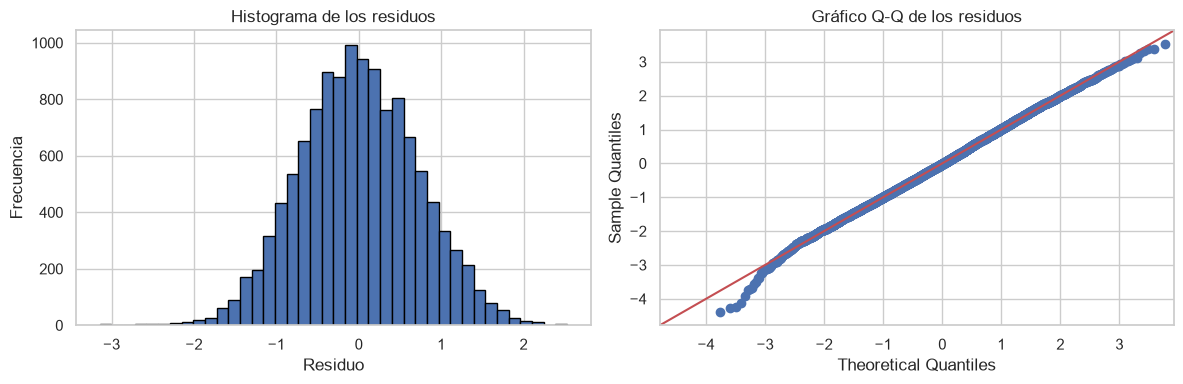

In [47]:
# Distribución de los residuos

import matplotlib.pyplot as plt
import statsmodels.api as sm

residuos = modelo.resid
valores_ajustados = modelo.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(residuos, bins=40, edgecolor="black")
axes[0].set_title("Histograma de los residuos")
axes[0].set_xlabel("Residuo")
axes[0].set_ylabel("Frecuencia")

sm.qqplot(residuos, line="45", fit=True, ax=axes[1])
axes[1].set_title("Gráfico Q-Q de los residuos")

plt.tight_layout()
plt.show()

El histograma muestra una distribución aproximadamente unimodal y centrada alrededor de cero, con una forma cercana a la campana normal. Sin embargo, el gráfico Q-Q evidencia una desviación respecto a la línea de referencia, especialmente en la cola inferior, donde algunos residuos se apartan de manera notoria del comportamiento esperado bajo una distribución normal. En la parte central, los puntos siguen la línea de referencia de forma más cercana. Por tanto, sugiere que la distribución de los residuos presenta una aproximación a la normalidad en su zona central, pero también desviaciones en los extremos. Esta evaluación visual debe complementarse con una prueba estadística de normalidad y considerar el tamaño de la muestra antes de establecer conclusiones sobre el cumplimiento del supuesto.

### 44. Verificación estadística de la normalidad de los residuos

Como complemento al análisis gráfico mediante el histograma y el gráfico Q-Q, se aplica la prueba de Shapiro-Wilk para evaluar si los residuos del modelo presentan diferencias estadísticamente significativas respecto a una distribución normal. Esta comprobación permite complementar la evaluación del supuesto de normalidad y determinar si existen evidencias estadísticas de desviaciones en la distribución de los errores.

La hipótesis nula establece que los residuos proceden de una distribución normal, mientras que la hipótesis alternativa plantea que no siguen una distribución normal. Se utilizará un nivel de significancia de 0,05 para interpretar el valor p. Debido al tamaño de la muestra del estudio, la prueba se aplicará a una muestra aleatoria de hasta 5.000 residuos, con el fin de realizar el procedimiento de forma computacionalmente manejable. El resultado se interpretará conjuntamente con la evidencia gráfica, considerando que las pruebas de normalidad pueden detectar desviaciones pequeñas cuando el tamaño muestral es elevado.

In [48]:
# Prueba de normalidad de Shapiro-Wilk
from scipy.stats import shapiro

# Tomar una muestra aleatoria si hay más de 5000 residuos
residuos_muestra = residuos.sample(
    n=min(5000, len(residuos)),
    random_state=42
) if hasattr(residuos, "sample") else residuos[:5000]

estadistico, valor_p = shapiro(residuos_muestra)

print("Estadístico de Shapiro-Wilk:", round(estadistico, 5))
print("Valor p:", valor_p)

if valor_p < 0.05:
    print("Resultado: se rechaza la hipótesis de normalidad.")
else:
    print("Resultado: no se rechaza la hipótesis de normalidad.")

Estadístico de Shapiro-Wilk: 0.99926
Valor p: 0.03434011789253129
Resultado: se rechaza la hipótesis de normalidad.


La prueba de Shapiro-Wilk obtuvo un estadístico de 0,99926 y un valor p de 0,0343. Dado que el valor p es inferior al nivel de significancia establecido (α = 0,05), se rechaza la hipótesis nula de normalidad. Por tanto, existe evidencia estadística de que los residuos se desvían de una distribución normal.

Este resultado debe interpretarse conjuntamente con el histograma y el gráfico Q-Q, que mostraron una distribución aproximadamente simétrica en la zona central. Asimismo, debe considerarse que la prueba se realizó sobre una muestra aleatoria de hasta 5.000 residuos y que, con tamaños muestrales elevados, pueden detectarse desviaciones pequeñas respecto a la normalidad.

### 45. Diagnóstico de linealidad y homocedasticidad mediante residuos

Una vez estimado el modelo de regresión lineal múltiple y evaluada gráficamente la distribución de los residuos, es necesario examinar si las relaciones entre las variables explicativas y la variable dependiente son compatibles con la especificación lineal del modelo, así como verificar si la variabilidad de los residuos se mantiene aproximadamente constante.

Para ello, se construye un gráfico de residuos frente a valores predichos. Este procedimiento permite identificar patrones sistemáticos que podrían sugerir problemas de linealidad y cambios en la dispersión que podrían indicar heterocedasticidad. La evaluación visual se complementará posteriormente con la prueba estadística de Breusch-Pagan.

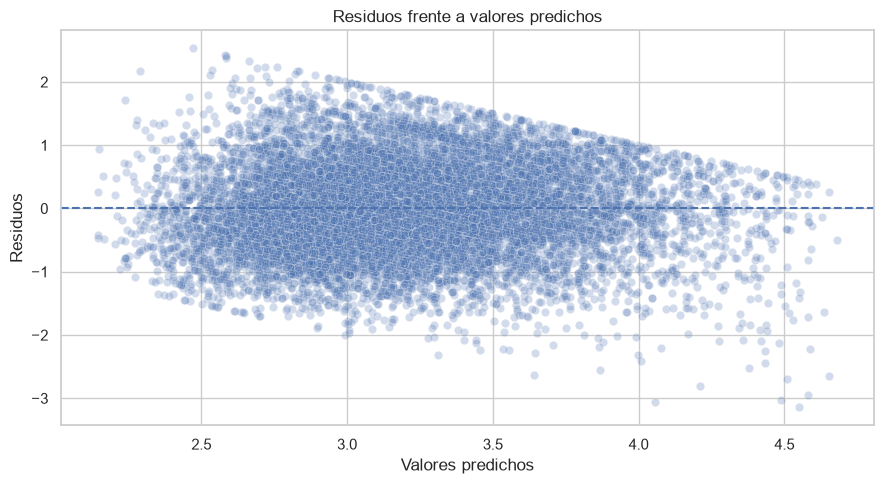

In [49]:
# Diagnóstico de linealidad y homocedasticidad visual

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.scatterplot(
    x=valores_ajustados,
    y=residuos,
    alpha=0.25
)

plt.axhline(y=0, linestyle="--")
plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.title("Residuos frente a valores predichos")
plt.tight_layout()
plt.show()

El gráfico muestra que los residuos se distribuyen alrededor de la línea horizontal de cero, sin una curvatura pronunciada que evidencie claramente una relación no lineal. Sin embargo, se observa una variación en la dispersión de los residuos a lo largo de los valores predichos, con una configuración similar a un abanico y una mayor presencia de residuos extremos en determinados intervalos.

Este patrón sugiere que la varianza de los residuos podría no ser constante. No obstante, la inspección visual no es suficiente para confirmar esta condición, por lo que se complementará con la prueba de Breusch-Pagan.

### Evaluación estadística de la homocedasticidad: prueba de Breusch-Pagan

La homocedasticidad es un supuesto del modelo de regresión lineal que establece que la varianza de los errores se mantiene constante a lo largo de los valores de las variables explicativas. Su evaluación es importante porque la presencia de heterocedasticidad puede afectar la validez de los errores estándar convencionales y, en consecuencia, las pruebas de significancia y los intervalos de confianza.

Con el fin de complementar la inspección gráfica de los residuos, se aplicará la prueba de Breusch-Pagan. La hipótesis nula establece que existe homocedasticidad, mientras que la hipótesis alternativa indica que la varianza de los errores no es constante. Se utilizará un nivel de significancia de 0,05 para interpretar el valor p de la prueba.

In [50]:
# Prueba de Breusch-Pagan para evaluar homocedasticidad

from statsmodels.stats.diagnostic import het_breuschpagan
import statsmodels.api as sm

# Matriz de variables explicativas del modelo
X = modelo.model.exog

# Residuos del modelo estimado
residuos = modelo.resid

# Ejecutar la prueba
bp_lm, bp_lm_pvalor, bp_f, bp_f_pvalor = het_breuschpagan(
    residuos,
    X
)

print("Estadístico LM:", round(bp_lm, 4))
print("Valor p (LM):", bp_lm_pvalor)
print("Estadístico F:", round(bp_f, 4))
print("Valor p (F):", bp_f_pvalor)

if bp_lm_pvalor < 0.05:
    print("Resultado: evidencia estadística de heterocedasticidad.")
else:
    print("Resultado: no se encuentra evidencia estadística suficiente de heterocedasticidad.")

Estadístico LM: 111.2162
Valor p (LM): 4.0048737055877047e-23
Estadístico F: 28.0471
Valor p (F): 3.17780629732655e-23
Resultado: evidencia estadística de heterocedasticidad.


La prueba de Breusch-Pagan obtuvo un estadístico LM de 111,2162, con un valor p de 4,0049 × 10⁻²³. Asimismo, el estadístico F fue de 28,0471, con un valor p de 3,1778 × 10⁻²³. Ambos valores p son inferiores al nivel de significancia establecido (α = 0,05); por tanto, se rechaza la hipótesis nula de homocedasticidad y se encuentra evidencia estadística de heterocedasticidad en los residuos del modelo.

Este resultado coincide con la posible variación de la dispersión observada en el gráfico de residuos frente a valores predichos. La heterocedasticidad puede afectar los errores estándar convencionales y, en consecuencia, la inferencia estadística sobre los coeficientes. Por ello, se evaluará el uso de errores estándar robustos como medida de corrección, conservando inicialmente la especificación del modelo y comparando los resultados con la estimación original.

### Corrección de la inferencia mediante errores estándar robustos

Debido a la evidencia de heterocedasticidad identificada mediante la prueba de Breusch-Pagan, se calcularán errores estándar robustos a la heterocedasticidad utilizando la matriz de covarianza HC3. Este procedimiento permite obtener errores estándar, valores p e intervalos de confianza ajustados frente a la varianza no constante de los errores, sin modificar los coeficientes estimados por mínimos cuadrados ordinarios.

La estimación robusta se comparará con el modelo original para identificar posibles cambios en la significancia estadística de los predictores. Esta corrección mejora la inferencia ante heterocedasticidad, aunque no elimina el patrón de varianza no constante ni corrige posibles problemas de especificación del modelo.

In [51]:
# Estimación con errores estándar robustos HC3

modelo_robusto = modelo.get_robustcov_results(cov_type="HC3")

print(modelo_robusto.summary())

                             OLS Regression Results                            
Dep. Variable:     indice_conocimiento   R-squared:                       0.266
Model:                             OLS   Adj. R-squared:                  0.265
Method:                  Least Squares   F-statistic:                     1001.
Date:                 Sat, 31 Oct 2026   Prob (F-statistic):               0.00
Time:                         18:24:07   Log-Likelihood:                -13314.
No. Observations:                12263   AIC:                         2.664e+04
Df Residuals:                    12258   BIC:                         2.667e+04
Df Model:                            4                                         
Covariance Type:                   HC3                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept     

La estimación con errores estándar robustos HC3 mantuvo los coeficientes de regresión y el coeficiente de determinación del modelo original (R² = 0,266; R² ajustado = 0,265), dado que esta corrección modifica la estimación de la incertidumbre de los coeficientes, pero no los valores estimados mediante mínimos cuadrados ordinarios.

Con la corrección robusta, los índices de protección (β = 0,1423), preocupación (β = −0,0559) y riesgo percibido (β = 0,1459) conservaron asociaciones estadísticamente significativas con el índice de conocimiento (p < 0,001). En contraste, el índice de importancia de los datos no presentó evidencia estadística suficiente de asociación independiente (β = −0,0088; p = 0,415).

La aplicación de HC3 permite realizar inferencias más adecuadas ante la heterocedasticidad identificada. Sin embargo, no elimina la heterocedasticidad ni aumenta la capacidad explicativa del modelo.

### 46. Diagnóstico de multicolinealidad mediante el factor de inflación de la varianza (VIF)

La multicolinealidad se presenta cuando dos o más variables explicativas del modelo mantienen relaciones lineales entre sí. Una multicolinealidad elevada puede incrementar la incertidumbre de los coeficientes y dificultar la identificación de la contribución individual de cada predictor.

Para evaluar esta condición, se calculará el factor de inflación de la varianza (VIF) de cada variable explicativa. Los valores obtenidos permitirán identificar posibles problemas de redundancia entre los predictores. De acuerdo con la guía, un VIF superior a 10 se considerará una señal de multicolinealidad problemática. La interpretación también tendrá en cuenta los valores de los demás predictores y la justificación conceptual de las variables seleccionadas.

In [52]:
# Diagnóstico de multicolinealidad mediante VIF

import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Utilizar la matriz de diseño del modelo original
X_vif = pd.DataFrame(
    modelo.model.exog,
    columns=modelo.model.exog_names
)

# Excluir la constante del cálculo e interpretación
X_predictores = X_vif.drop(columns=["Intercept"], errors="ignore")

tabla_vif = pd.DataFrame({
    "Variable": X_predictores.columns,
    "VIF": [
        variance_inflation_factor(
            X_predictores.values, i
        )
        for i in range(X_predictores.shape[1])
    ]
})

display(tabla_vif.round(3))

,Variable,VIF
0,indice_proteccion,4.456
1,indice_preocupacion,28.568
2,indice_importancia_datos,28.786
3,indice_riesgo_percibido,12.279


El cálculo del factor de inflación de la varianza (VIF) permitió identificar diferencias en el nivel de colinealidad entre las variables explicativas del modelo. El índice de protección presentó un VIF de 4,456, mientras que el índice de preocupación obtuvo un valor de 28,568, el índice de importancia de los datos alcanzó 28,786 y el índice de riesgo percibido registró 12,279.

Tomando como referencia un umbral de VIF superior a 10, los resultados sugieren multicolinealidad potencialmente problemática en los índices de preocupación, importancia de los datos y riesgo percibido. Esta condición indica que parte de la información aportada por estas variables podría estar compartida, lo que dificulta separar con precisión sus asociaciones individuales con el índice de conocimiento y puede incrementar la incertidumbre de los coeficientes.

### 47. Diagnóstico de observaciones influyentes mediante la distancia de Cook

Además de evaluar los supuestos del modelo y la relación entre las variables explicativas, es necesario identificar observaciones que puedan ejercer una influencia desproporcionada sobre la estimación de los coeficientes. 

Para examinar esta condición, se calculará la distancia de Cook, que combina información sobre los residuos y el apalancamiento de cada observación. Se identificarán los registros con valores relativamente altos y se visualizará su distribución. Como referencia exploratoria, se utilizará el umbral de 4/n, donde n corresponde al número de observaciones del modelo. Superar este umbral no implica que un registro deba eliminarse automáticamente; cada caso deberá interpretarse en función de la calidad de los datos y de su relevancia analítica.

Número de observaciones: 12263
Umbral exploratorio de Cook (4/n): 0.000326
Máxima distancia de Cook: 0.00366
Observaciones por encima del umbral: 642


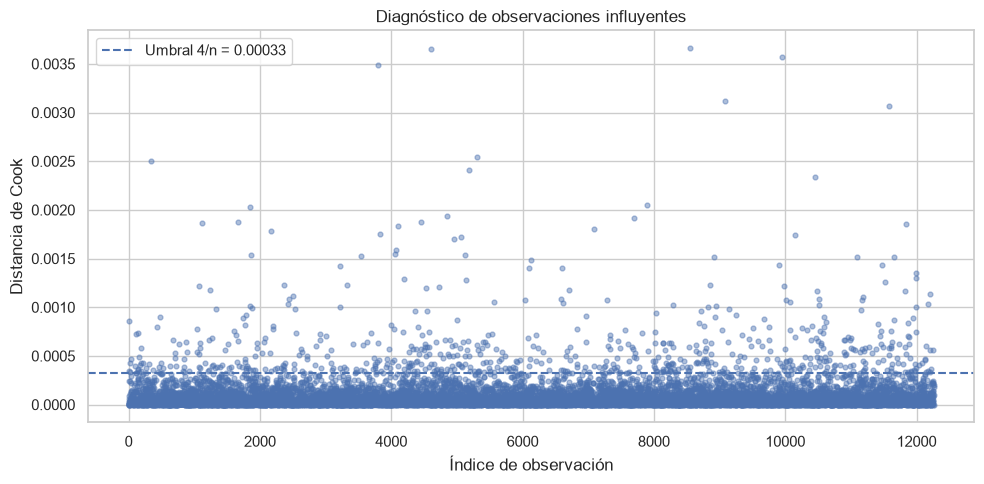

In [53]:
# Diagnóstico de observaciones influyentes: distancia de Cook

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Obtener medidas de influencia del modelo original
influencia = modelo.get_influence()
distancia_cook = influencia.cooks_distance[0]

n = int(modelo.nobs)
umbral_cook = 4 / n

# Resumen de resultados
print("Número de observaciones:", n)
print("Umbral exploratorio de Cook (4/n):", round(umbral_cook, 6))
print("Máxima distancia de Cook:", round(np.max(distancia_cook), 6))
print("Observaciones por encima del umbral:", int(np.sum(distancia_cook > umbral_cook)))

# Gráfico de distancias de Cook
plt.figure(figsize=(10, 5))
plt.scatter(
    np.arange(len(distancia_cook)),
    distancia_cook,
    alpha=0.45,
    s=12
)
plt.axhline(
    y=umbral_cook,
    linestyle="--",
    label=f"Umbral 4/n = {umbral_cook:.5f}"
)
plt.xlabel("Índice de observación")
plt.ylabel("Distancia de Cook")
plt.title("Diagnóstico de observaciones influyentes")
plt.legend()
plt.tight_layout()
plt.show()

El análisis de la distancia de Cook se realizó sobre las 12.263 observaciones incluidas en el modelo de regresión lineal múltiple. El umbral exploratorio establecido mediante el criterio 4/n fue de 0,000326, mientras que la distancia de Cook máxima observada fue de 0,003366. En total, 642 observaciones superaron dicho umbral, lo que representa aproximadamente el 5,24 % de los casos analizados.

El gráfico muestra que la mayoría de las observaciones presenta valores reducidos de distancia de Cook, aunque se identifican algunos registros con valores relativamente elevados respecto al umbral de referencia. Estos resultados sugieren la presencia de observaciones que podrían ejercer una influencia apreciable sobre la estimación del modelo.

### Síntesis del diagnóstico del modelo de regresión

La evaluación del modelo permitió identificar aspectos que deben considerarse al interpretar los resultados. La prueba de Shapiro-Wilk evidenció una desviación estadísticamente significativa respecto a la normalidad de los residuos, mientras que la prueba de Breusch-Pagan indicó la presencia de heterocedasticidad. Para atender esta última condición, se estimó una versión del modelo con errores estándar robustos HC3, manteniendo los coeficientes de mínimos cuadrados ordinarios y ajustando la inferencia estadística.

El análisis de multicolinealidad identificó valores de VIF superiores a 10 en los índices de preocupación, importancia de los datos y riesgo percibido. Adicionalmente, el diagnóstico de distancia de Cook encontró 642 observaciones por encima del umbral exploratorio de 4/n. Estos resultados señalan la necesidad de interpretar con cautela los coeficientes individuales y reconocer posibles limitaciones en la especificación del modelo.

El modelo constituye una aproximación inicial para analizar las asociaciones entre los índices seleccionados y el conocimiento sobre seguridad digital. Su interpretación deberá considerar las limitaciones identificadas y evitar conclusiones causales. 

In [54]:
# ============================================================
# RESPUESTAS A LAS PREGUNTAS DE INTERPRETACIÓN Y LÍMITES
# Modelo: medidas de protección (Q20) ~ familiaridad (Q6)
# + preocupación (Q18) + experiencia TI (Q25) + país
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Verificar y preparar las variables construidas previamente
requeridas = [
    "indice_proteccion", "indice_conocimiento",
    "indice_preocupacion", "q25", "Country"
]
faltantes = [v for v in requeridas if v not in datos.columns]

if faltantes:
    raise ValueError(
        f"Faltan variables en datos: {faltantes}. "
        "Ejecuta primero las celdas de construcción de índices."
    )

analisis = datos[requeridas].copy()

# Q25: 1 = Sí tiene experiencia; 2 = No tiene experiencia
analisis["experiencia_TI"] = analisis["q25"].map({
    1: "Sí",
    2: "No"
})

for col in ["indice_proteccion", "indice_conocimiento",
            "indice_preocupacion", "Country"]:
    analisis[col] = pd.to_numeric(analisis[col], errors="coerce")

analisis = analisis.dropna().copy()
analisis["Country"] = analisis["Country"].astype(int)
analisis["experiencia_TI"] = pd.Categorical(
    analisis["experiencia_TI"],
    categories=["No", "Sí"]
)

# Comprobar el rango observado del conteo
print("Rango observado de Q20:",
      analisis["indice_proteccion"].min(),
      "a", analisis["indice_proteccion"].max())
print("Casos completos para el modelo:", len(analisis))

# 2. Modelo principal: país categórico y "No" como referencia
formula = (
    "indice_proteccion ~ indice_conocimiento + "
    "indice_preocupacion + "
    "C(experiencia_TI, Treatment(reference='No')) + C(Country)"
)

modelo_principal = smf.ols(formula, data=analisis).fit()
modelo_hc3 = modelo_principal.get_robustcov_results(cov_type="HC3")

# Crear una tabla de coeficientes con IC95% HC3
tabla_hc3 = pd.DataFrame({
    "Coeficiente": modelo_hc3.params,
    "Error estándar HC3": modelo_hc3.bse,
    "p": modelo_hc3.pvalues,
    "IC95% inferior": modelo_hc3.conf_int()[:, 0],
    "IC95% superior": modelo_hc3.conf_int()[:, 1]
}, index=modelo_principal.model.exog_names)

print("\nRESULTADOS DEL MODELO PRINCIPAL CON HC3")
display(tabla_hc3.round(4))

# 3. Pregunta 1: familiaridad Q6
nombre_q6 = "indice_conocimiento"
fila_q6 = tabla_hc3.loc[nombre_q6]

print("\nPREGUNTA 1. FAMILIARIDAD")
print(
    f"Por cada punto adicional en el índice de familiaridad, "
    f"el número esperado de medidas de protección cambia en "
    f"{fila_q6['Coeficiente']:.4f} medidas, manteniendo constantes "
    f"los demás predictores. IC95% HC3: "
    f"[{fila_q6['IC95% inferior']:.4f}, "
    f"{fila_q6['IC95% superior']:.4f}]; "
    f"p = {fila_q6['p']:.4g}."
)

# 4. Pregunta 2: diferencia ajustada de experiencia TI frente a "No"
nombre_ti = (
    "C(experiencia_TI, Treatment(reference='No'))[T.Sí]"
)

print("\nPREGUNTA 2. EXPERIENCIA EN TI")
if nombre_ti in tabla_hc3.index:
    fila_ti = tabla_hc3.loc[nombre_ti]
    print(
        f"Frente a quienes no reportan experiencia en TI, quienes sí "
        f"la reportan presentan una diferencia ajustada de "
        f"{fila_ti['Coeficiente']:.4f} medidas. "
        f"IC95% HC3: [{fila_ti['IC95% inferior']:.4f}, "
        f"{fila_ti['IC95% superior']:.4f}]; "
        f"p = {fila_ti['p']:.4g}. "
        f"El rango teórico de Q20 es 0–13."
    )
else:
    print("No se encontró el coeficiente esperado. Revisa la tabla HC3.")

# 5. Pregunta 3: R² ajustado
print("\nPREGUNTA 3. CAPACIDAD EXPLICATIVA")
print(f"R² = {modelo_principal.rsquared:.4f}")
print(f"R² ajustado = {modelo_principal.rsquared_adj:.4f}")
print(
    f"El modelo resume aproximadamente "
    f"{100 * modelo_principal.rsquared_adj:.2f}% de la variabilidad "
    f"de Q20, ajustando por el número de predictores. "
    "Esto no representa causalidad."
)

# 6. Pregunta 4: heterocedasticidad y HC3
bp = het_breuschpagan(
    modelo_principal.resid,
    modelo_principal.model.exog
)

print("\nPREGUNTA 4. HETEROCEDASTICIDAD")
print(f"Breusch-Pagan LM = {bp[0]:.4f}; p = {bp[1]:.6g}")
if bp[1] < 0.05:
    print(
        "Hay evidencia estadística de heterocedasticidad. "
        "HC3 ajusta errores estándar, intervalos y pruebas, "
        "pero no elimina la heterocedasticidad."
    )
else:
    print(
        "La prueba no detecta evidencia estadística suficiente "
        "de heterocedasticidad al nivel 0,05. HC3 se conserva "
        "como inferencia robusta."
    )

# 7. Pregunta 5: VIF
X = pd.DataFrame(
    modelo_principal.model.exog,
    columns=modelo_principal.model.exog_names
)
X = X.drop(columns=["Intercept"], errors="ignore")

tabla_vif = pd.DataFrame({
    "Variable": X.columns,
    "VIF": [
        variance_inflation_factor(X.to_numpy(), i)
        for i in range(X.shape[1])
    ]
}).sort_values("VIF", ascending=False)

print("\nPREGUNTA 5. MULTICOLINEALIDAD (VIF)")
display(tabla_vif.round(3))
print("Número de predictores con VIF > 10:",
      int((tabla_vif["VIF"] > 10).sum()))

# Observaciones influyentes
influencia = modelo_principal.get_influence()
cook = influencia.cooks_distance[0]
n = len(analisis)
umbral_cook = 4 / n
mascara_cook = cook > umbral_cook

print("\nDISTANCIA DE COOK")
print(f"n = {n}; umbral 4/n = {umbral_cook:.7f}")
print(f"Distancia máxima = {cook.max():.7f}")
print(f"Casos por encima del umbral = {mascara_cook.sum()} "
      f"({100 * mascara_cook.mean():.2f}%)")

# Predicciones fuera del rango teórico
pred = modelo_principal.predict(analisis)
fuera_rango = (pred < 0) | (pred > 13)

print("\nPREDICCIONES FUERA DEL RANGO 0–13")
print(f"Cantidad = {int(fuera_rango.sum())} de {len(pred)}")
print(f"Porcentaje = {100 * fuera_rango.mean():.2f}%")
print(f"Mínimo predicho = {pred.min():.4f}")
print(f"Máximo predicho = {pred.max():.4f}")

# 8. Pregunta 6: sensibilidad excluyendo Cook > 4/n
# Se excluyen solo para este análisis de sensibilidad.
analisis_sens = analisis.loc[~mascara_cook].copy()

modelo_sens = smf.ols(formula, data=analisis_sens).fit()
modelo_sens_hc3 = modelo_sens.get_robustcov_results(cov_type="HC3")

tabla_sens = pd.DataFrame({
    "Coef. principal": modelo_hc3.params,
    "IC95% inf. principal": modelo_hc3.conf_int()[:, 0],
    "IC95% sup. principal": modelo_hc3.conf_int()[:, 1],
    "Coef. sensibilidad": modelo_sens_hc3.params,
    "IC95% inf. sensibilidad": modelo_sens_hc3.conf_int()[:, 0],
    "IC95% sup. sensibilidad": modelo_sens_hc3.conf_int()[:, 1]
}, index=modelo_principal.model.exog_names)

tabla_sens["Cambio coeficiente"] = (
    tabla_sens["Coef. sensibilidad"] - tabla_sens["Coef. principal"]
)

print("\nPREGUNTA 6. COMPARACIÓN DE SENSIBILIDAD")
print("Casos modelo principal:", int(modelo_principal.nobs))
print("Casos modelo sensibilidad:", int(modelo_sens.nobs))
print(f"R² ajustado principal = {modelo_principal.rsquared_adj:.4f}")
print(f"R² ajustado sensibilidad = {modelo_sens.rsquared_adj:.4f}")
display(tabla_sens.round(4))

print(
    "\nNota: superar 4/n es un criterio exploratorio, no una razón "
    "automática para eliminar observaciones del análisis principal."
)

Rango observado de Q20: 0 a 13
Casos completos para el modelo: 11991

RESULTADOS DEL MODELO PRINCIPAL CON HC3


,Coeficiente,Error estándar HC3,p,IC95% inferior,IC95% superior
Intercept,-2.0539,0.1545,0.0000,-2.3566,-1.7511
"C(experiencia_TI, Treatment(reference='No'))[T.Sí]",0.3303,0.0525,0.0000,0.2273,0.4333
C(Country)[T.2],1.3629,0.1040,0.0000,1.1590,1.5668
C(Country)[T.3],1.0310,0.1152,0.0000,0.8051,1.2569
C(Country)[T.4],0.6756,0.1065,0.0000,0.4668,0.8844
C(Country)[T.5],0.3755,0.1041,0.0003,0.1714,0.5796
C(Country)[T.6],0.6370,0.1036,0.0000,0.4339,0.8402
C(Country)[T.7],0.0898,0.1042,0.3889,-0.1145,0.2941
C(Country)[T.8],0.9945,0.1116,0.0000,0.7757,1.2133
C(Country)[T.9],1.5008,0.1132,0.0000,1.2788,1.7227



PREGUNTA 1. FAMILIARIDAD
Por cada punto adicional en el índice de familiaridad, el número esperado de medidas de protección cambia en 1.5956 medidas, manteniendo constantes los demás predictores. IC95% HC3: [1.5384, 1.6529]; p = 0.

PREGUNTA 2. EXPERIENCIA EN TI
Frente a quienes no reportan experiencia en TI, quienes sí la reportan presentan una diferencia ajustada de 0.3303 medidas. IC95% HC3: [0.2273, 0.4333]; p = 3.366e-10. El rango teórico de Q20 es 0–13.

PREGUNTA 3. CAPACIDAD EXPLICATIVA
R² = 0.2892
R² ajustado = 0.2884
El modelo resume aproximadamente 28.84% de la variabilidad de Q20, ajustando por el número de predictores. Esto no representa causalidad.

PREGUNTA 4. HETEROCEDASTICIDAD
Breusch-Pagan LM = 305.9264; p = 6.86065e-57
Hay evidencia estadística de heterocedasticidad. HC3 ajusta errores estándar, intervalos y pruebas, pero no elimina la heterocedasticidad.

PREGUNTA 5. MULTICOLINEALIDAD (VIF)


,Variable,VIF
13,indice_preocupacion,13.395
12,indice_conocimiento,12.800
0,"C(experiencia_TI, Treatment(reference='No'))[T...",2.006
8,C(Country)[T.9],1.889
2,C(Country)[T.3],1.847
5,C(Country)[T.6],1.834
6,C(Country)[T.7],1.752
3,C(Country)[T.4],1.725
11,C(Country)[T.12],1.707
4,C(Country)[T.5],1.706


Número de predictores con VIF > 10: 2

DISTANCIA DE COOK
n = 11991; umbral 4/n = 0.0003336
Distancia máxima = 0.0023209
Casos por encima del umbral = 591 (4.93%)

PREDICCIONES FUERA DEL RANGO 0–13
Cantidad = 0 de 11991
Porcentaje = 0.00%
Mínimo predicho = 0.0080
Máximo predicho = 9.2985

PREGUNTA 6. COMPARACIÓN DE SENSIBILIDAD
Casos modelo principal: 11991
Casos modelo sensibilidad: 11400
R² ajustado principal = 0.2884
R² ajustado sensibilidad = 0.3751


,Coef. principal,IC95% inf. principal,IC95% sup. principal,Coef. sensibilidad,IC95% inf. sensibilidad,IC95% sup. sensibilidad,Cambio coeficiente
Intercept,-2.0539,-2.3566,-1.7511,-2.6339,-2.8951,-2.3727,-0.5800
"C(experiencia_TI, Treatment(reference='No'))[T.Sí]",0.3303,0.2273,0.4333,0.2516,0.1626,0.3406,-0.0787
C(Country)[T.2],1.3629,1.1590,1.5668,1.6845,1.5053,1.8638,0.3217
C(Country)[T.3],1.0310,0.8051,1.2569,1.2095,1.0173,1.4017,0.1785
C(Country)[T.4],0.6756,0.4668,0.8844,0.8973,0.7177,1.0770,0.2217
C(Country)[T.5],0.3755,0.1714,0.5796,0.6054,0.4278,0.7831,0.2299
C(Country)[T.6],0.6370,0.4339,0.8402,0.8709,0.6945,1.0472,0.2338
C(Country)[T.7],0.0898,-0.1145,0.2941,0.2167,0.0420,0.3915,0.1269
C(Country)[T.8],0.9945,0.7757,1.2133,1.1285,0.9428,1.3143,0.1340
C(Country)[T.9],1.5008,1.2788,1.7227,1.7859,1.5944,1.9775,0.2852



Nota: superar 4/n es un criterio exploratorio, no una razón automática para eliminar observaciones del análisis principal.


### 48. Regresión logística binaria

Se incorpora la regresión logística binaria para complementar el análisis cuantitativo desarrollado. Esta técnica permite estudiar la asociación entre diferentes características de los encuestados y la probabilidad de pertenecer a una de dos categorías de una variable de respuesta.

El análisis comprende la preparación y validación de las variables, la estimación del modelo, la interpretación de los coeficientes mediante odds ratios y la evaluación del desempeño de clasificación. También se examinan indicadores de ajuste y las limitaciones de los resultados, de acuerdo con los requerimientos de la guía de aprendizaje.

Para este análisis se propone utilizar la variable Q25, relacionada con la experiencia en tecnologías de información, como variable dependiente binaria. De acuerdo con la codificación identificada en la base, se considerará la categoría 1 como «Sí» y la categoría 2 como «No». Los demás códigos deberán verificarse y tratarse como valores no válidos cuando corresponda.

Como variables explicativas se utilizarán la familiaridad con la seguridad digital, la preocupación relacionada con este tema y el número de medidas de protección reportadas. También se incluirá el país como variable categórica para controlar estadísticamente las diferencias entre países.

La pregunta analítica es: ¿cómo se asocian la familiaridad, la preocupación y las medidas de protección con la probabilidad de declarar experiencia en tecnologías de información, teniendo en cuenta el país de procedencia? Esta especificación permite utilizar una respuesta binaria natural de la encuesta sin crear arbitrariamente un punto de corte. Los resultados se interpretarán como asociaciones estadísticas y no como relaciones causales.

## Preparación y validación de las variables

Antes de estimar la regresión logística, es necesario verificar la codificación de las variables y construir los indicadores que se utilizarán en el modelo. Se revisarán los ítems correspondientes a familiaridad, preocupación y medidas de protección, así como la distribución de la variable dependiente.

También se identificarán los valores faltantes y los registros que no cumplan los criterios de validez. El modelo se estimará únicamente con los casos que dispongan de información completa para las variables seleccionadas. Se documentará el número de registros utilizados y excluidos para garantizar la trazabilidad del procedimiento.

In [55]:
# Verificar las columnas necesarias para la regresión logística

print("Columnas disponibles en la base:")
print(datos.columns.tolist())

print("\nDistribución de Q25:")
display(datos["q25"].value_counts(dropna=False).sort_index())

print("\nColumnas relacionadas con Q6:")
print([c for c in datos.columns if c.startswith("q6r")])

print("\nColumnas relacionadas con Q18:")
print([c for c in datos.columns if c.startswith("q18")])

print("\nColumnas relacionadas con Q20:")
print([c for c in datos.columns if c.startswith("q20r")])

Columnas disponibles en la base:
['ID', 'Country', 'Gender', 'Gender_SelfDescription', 'Age', 'Education', 'Ethnicity', 'q1r1', 'q1r2', 'q1r3', 'q1r4', 'q1r5', 'q1r6', 'q1r7', 'q2r1', 'q2r2', 'q2r3', 'q3r1', 'q3r2', 'q3r3', 'q3r4', 'q3r5', 'q3r6', 'q3r7', 'q3r8', 'q3r9', 'q3r10', 'q3r11', 'q3r12', 'q3r13', 'q4r1', 'q4r2', 'q4r3', 'q4r4', 'q4r5', 'q4r6', 'q4r7', 'q4r8', 'q6r1', 'q6r2', 'q6r3', 'q6r4', 'q6r5', 'q6r6', 'q6r7', 'q6r8', 'q6r9', 'q6r10', 'q6r11', 'q6r12', 'q6r13', 'q6r14', 'q6r15', 'q6r16', 'q6r17', 'q6r18', 'q6r19', 'q6r20', 'q6r21', 'q6r22', 'q7r1', 'q7r2', 'q7r3', 'q7r4', 'q7r5', 'q7r6', 'q7r7', 'q7r8', 'q7r9', 'q8r2', 'q8r3', 'q8r4', 'q8r5', 'q8r6', 'q8r7', 'q8r8', 'q8r9', 'q8r10', 'q8r1', 'q8r10oer1', 'q9r1', 'q9r2', 'q9r3', 'q9r4', 'q9r5', 'q9r6', 'q9r7', 'q9r8', 'q9r9', 'q10r1', 'q10r2', 'q10r3', 'q10r4', 'q10r5', 'q11r1', 'q11r2', 'q11r3', 'q11r4', 'q11r5', 'q12r1', 'q12r2', 'q12r3', 'q12r4', 'q12r5', 'q12r6', 'q12r7', 'q12r8', 'q13r1', 'q13r2', 'q13r3', 'q13r4', 'q1

q25
1.0     4573
2.0     7483
12.0       1
NaN      294
Name: count, dtype: int64


Columnas relacionadas con Q6:
['q6r1', 'q6r2', 'q6r3', 'q6r4', 'q6r5', 'q6r6', 'q6r7', 'q6r8', 'q6r9', 'q6r10', 'q6r11', 'q6r12', 'q6r13', 'q6r14', 'q6r15', 'q6r16', 'q6r17', 'q6r18', 'q6r19', 'q6r20', 'q6r21', 'q6r22']

Columnas relacionadas con Q18:
['q18ar1', 'q18ar2', 'q18ar3', 'q18ar4', 'q18ar5', 'q18ar6', 'q18ar7', 'q18ar8', 'q18br9', 'q18br10', 'q18br11', 'q18br12', 'q18br13', 'q18br14', 'q18br15', 'q18br16', 'q18br17', 'q18br18', 'q18br19']

Columnas relacionadas con Q20:
['q20r2', 'q20r3', 'q20r4', 'q20r5', 'q20r6', 'q20r7', 'q20r8', 'q20r9', 'q20r10', 'q20r11', 'q20r12', 'q20r13', 'q20r14', 'q20r1']


Los predictores se construirán a partir de los ítems originales de la encuesta. Para familiaridad y preocupación se utilizarán los ítems correspondientes a Q6 y Q18, respectivamente, respetando sus rangos de respuesta y la disponibilidad de datos. El número de medidas de protección se calculará a partir de los ítems de Q20 que representen medidas específicas, verificando que la opción «ninguna» no se cuente simultáneamente con otras medidas.

Q25 se recodificará como una variable binaria, asignando 1 a la categoría «Sí» y 0 a «No». Antes de estimar el modelo se comprobarán las frecuencias de ambas categorías y el número de casos completos. Q25 contiene las categorías 1 y 2, además de un registro con código 12 y valores faltantes. Antes de estimar el modelo, se verificará la correspondencia de las categorías con las respuestas originales. Los códigos no válidos y los registros incompletos se excluirán del modelo, documentando el número de casos utilizado.

In [56]:
import pandas as pd
import numpy as np

# Verificar la codificación de Q25
print("Frecuencias originales de Q25:")
display(datos["q25"].value_counts(dropna=False).sort_index())

# Comprobar los indicadores disponibles
variables_requeridas = [
    "q25",
    "indice_conocimiento",
    "indice_proteccion",
    "indice_preocupacion",
    "Country"
]

faltantes = [v for v in variables_requeridas if v not in datos.columns]

if faltantes:
    raise KeyError(f"Faltan estas columnas: {faltantes}")

# Preparar la base de trabajo
datos_logit = datos[variables_requeridas].copy()

# Conservar únicamente las categorías válidas de Q25
datos_logit = datos_logit[datos_logit["q25"].isin([1, 2])].copy()

# Codificación provisional: 1 = Sí; 0 = No
datos_logit["experiencia_ti_binaria"] = datos_logit["q25"].map({
    1: 1,
    2: 0
})

# Convertir el país a variable categórica
datos_logit["Country"] = datos_logit["Country"].astype("category")

# Conservar casos completos
datos_logit = datos_logit.dropna(
    subset=[
        "experiencia_ti_binaria",
        "indice_conocimiento",
        "indice_proteccion",
        "indice_preocupacion",
        "Country"
    ]
)

print("Número de casos válidos:", len(datos_logit))
print("\nDistribución de la variable dependiente:")
display(
    datos_logit["experiencia_ti_binaria"]
    .value_counts()
    .rename(index={0: "No", 1: "Sí"})
    .to_frame("Frecuencia")
)

print("\nResumen de los predictores:")
display(
    datos_logit[
        [
            "indice_conocimiento",
            "indice_proteccion",
            "indice_preocupacion"
        ]
    ].describe().round(3)
)

Frecuencias originales de Q25:


q25
1.0     4573
2.0     7483
12.0       1
NaN      294
Name: count, dtype: int64

Número de casos válidos: 11991

Distribución de la variable dependiente:


,Frecuencia
experiencia_ti_binaria,
No,7429
Sí,4562



Resumen de los predictores:


,indice_conocimiento,indice_proteccion,indice_preocupacion
count,11991.000,11991.000,11991.000
mean,3.210,5.120,3.952
std,0.837,2.836,0.880
min,1.000,0.000,1.000
25%,2.591,3.000,3.382
50%,3.227,5.000,4.105
75%,3.818,7.000,4.684
max,5.000,13.000,5.000


### 49. Estimación del modelo de regresión logística binaria

Una vez preparadas las variables y delimitada la muestra analítica, se estima un modelo de regresión logística binaria mediante la función `logit` de `statsmodels.formula.api`. La variable dependiente representa la categoría de respuesta «Sí» frente a «No», mientras que los predictores son los índices de conocimiento, protección y preocupación. El país se incluye como variable categórica para controlar las diferencias entre los países participantes.

La regresión logística permite estimar la asociación entre estas variables y las probabilidades relativas de pertenecer a la categoría «Sí». La significancia estadística se evaluará junto con la magnitud de los coeficientes, sus intervalos de confianza y las medidas de ajuste. Debido al carácter observacional de la encuesta, los resultados se interpretarán como asociaciones y no como relaciones causales.

In [57]:
import statsmodels.formula.api as smf
import numpy as np
import pandas as pd

# Especificación de la regresión logística
formula_logit = (
    "experiencia_ti_binaria ~ indice_conocimiento "
    "+ indice_proteccion + indice_preocupacion + C(Country)"
)

# Estimar el modelo
modelo_logit = smf.logit(
    formula=formula_logit,
    data=datos_logit
).fit(disp=False, maxiter=200)

# Mostrar los resultados completos
print(modelo_logit.summary())

                             Logit Regression Results                             
Dep. Variable:     experiencia_ti_binaria   No. Observations:                11991
Model:                              Logit   Df Residuals:                    11976
Method:                               MLE   Df Model:                           14
Date:                    Sat, 31 Oct 2026   Pseudo R-squ.:                  0.1676
Time:                            18:24:09   Log-Likelihood:                -6630.8
converged:                           True   LL-Null:                       -7965.4
Covariance Type:                nonrobust   LLR p-value:                     0.000
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -3.7138      0.160    -23.152      0.000      -4.028      -3.399
C(Country)[T.2]        -0.6865      0.112     -6.150      0.000      -0.

Los coeficientes de la regresión logística se expresan en logaritmos de las razones de probabilidades (*log-odds*). Para facilitar su interpretación, se calcularán los *odds ratios* mediante la exponenciación de los coeficientes, junto con sus intervalos de confianza del 95 %.

Un odds ratio superior a 1 representa una asociación positiva con las odds de declarar la categoría «Sí»; un valor inferior a 1 representa una asociación negativa, manteniendo constantes los demás predictores. Si el intervalo de confianza incluye el valor 1, no se considera evidencia estadística suficiente de una asociación al nivel convencional del 5 %, en concordancia con el contraste correspondiente.

In [58]:
# Calcular odds ratios e intervalos de confianza del 95 %
coeficientes = modelo_logit.params
intervalos = modelo_logit.conf_int()

tabla_odds = pd.DataFrame({
    "Coeficiente": coeficientes,
    "Odds_ratio": np.exp(coeficientes),
    "IC95_inferior": np.exp(intervalos[0]),
    "IC95_superior": np.exp(intervalos[1]),
    "Valor_p": modelo_logit.pvalues
})

display(tabla_odds.round(4))

,Coeficiente,Odds_ratio,IC95_inferior,IC95_superior,Valor_p
Intercept,-3.7138,0.0244,0.0178,0.0334,0.0000
C(Country)[T.2],-0.6865,0.5034,0.4044,0.6265,0.0000
C(Country)[T.3],1.0708,2.9177,2.3947,3.5550,0.0000
C(Country)[T.4],-0.0511,0.9502,0.7755,1.1642,0.6218
C(Country)[T.5],0.8138,2.2564,1.8576,2.7408,0.0000
C(Country)[T.6],1.2472,3.4804,2.8640,4.2296,0.0000
C(Country)[T.7],-0.6984,0.4974,0.4022,0.6151,0.0000
C(Country)[T.8],1.1696,3.2207,2.6456,3.9207,0.0000
C(Country)[T.9],0.7875,2.1979,1.8119,2.6662,0.0000
C(Country)[T.10],-0.1780,0.8369,0.6795,1.0309,0.0941


# Interpretación de los resultados de la regresión logística

Los resultados muestran asociaciones estadísticamente significativas entre los tres indicadores analizados y las odds de declarar experiencia en tecnologías de información, manteniendo constantes los demás predictores y el país.

El índice de conocimiento presenta un coeficiente positivo de 0,8875 y un odds ratio de 2,4292 (IC95 %: 2,2844–2,5831; p < 0,001). Esto indica que, por cada punto adicional en el índice de conocimiento, las odds de declarar experiencia en tecnologías de información se multiplican aproximadamente por 2,43, manteniendo constantes las demás variables. Este resultado representa una asociación positiva de magnitud importante.

El índice de protección presenta un coeficiente de 0,0572 y un odds ratio de 1,0588 (IC95 %: 1,0410–1,0770; p < 0,001). Por cada medida adicional de protección reportada, las odds de declarar experiencia en tecnologías de información aumentan aproximadamente un 5,9 %, manteniendo constantes los demás predictores.

El índice de preocupación presenta un coeficiente negativo de −0,0700 y un odds ratio de 0,9323 (IC95 %: 0,8863–0,9808; p = 0,0067). Esto indica que, por cada punto adicional en el índice de preocupación, las odds de declarar experiencia en tecnologías de información disminuyen aproximadamente un 6,8 %, manteniendo constantes las demás variables.

También se observan diferencias entre países respecto de la categoría de referencia utilizada por el modelo. Los odds ratios de los países deben interpretarse como asociaciones ajustadas y no como efectos causales. En particular, las categorías correspondientes a los países 4 y 10 no muestran evidencia estadística suficiente de diferencias al nivel del 5 %, pues sus intervalos de confianza incluyen el valor 1.

Los resultados indican que el conocimiento, las medidas de protección y la preocupación presentan asociaciones de distinta dirección y magnitud con la experiencia declarada en tecnologías de información. 

### 50. Evaluación del desempeño de clasificación

La evaluación de clasificación permite examinar qué tan bien el modelo distingue entre las personas que declaran experiencia en tecnologías de información y aquellas que no la declaran. Para ello se calculará la probabilidad predicha por el modelo y se utilizará un umbral de clasificación de 0,50 para asignar las categorías estimadas.

Se construirá una matriz de confusión y se calcularán las métricas accuracy, precision y recall. Estas métricas describen el desempeño de clasificación sobre los mismos registros utilizados para ajustar el modelo, por lo que deben interpretarse como medidas de desempeño aparente y no como una evaluación independiente de su capacidad predictiva.

In [59]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score
)

# Calcular probabilidades y clases predichas
datos_logit["probabilidad_predicha"] = modelo_logit.predict(datos_logit)

datos_logit["clase_predicha"] = (
    datos_logit["probabilidad_predicha"] >= 0.50
).astype(int)

# Matriz de confusión
matriz = confusion_matrix(
    datos_logit["experiencia_ti_binaria"],
    datos_logit["clase_predicha"],
    labels=[0, 1]
)

tabla_confusion = pd.DataFrame(
    matriz,
    index=["Real: No", "Real: Sí"],
    columns=["Predicho: No", "Predicho: Sí"]
)

print("Matriz de confusión:")
display(tabla_confusion)

# Métricas de clasificación
metricas_clasificacion = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision", "Recall"],
    "Valor": [
        accuracy_score(
            datos_logit["experiencia_ti_binaria"],
            datos_logit["clase_predicha"]
        ),
        precision_score(
            datos_logit["experiencia_ti_binaria"],
            datos_logit["clase_predicha"],
            zero_division=0
        ),
        recall_score(
            datos_logit["experiencia_ti_binaria"],
            datos_logit["clase_predicha"],
            zero_division=0
        )
    ]
})

display(metricas_clasificacion.round(4))

Matriz de confusión:


,Predicho: No,Predicho: Sí
Real: No,6159,1270
Real: Sí,2159,2403


,Métrica,Valor
0,Accuracy,0.7140
1,Precision,0.6542
2,Recall,0.5267


Para complementar las métricas de clasificación, se calcularán el pseudo-R² de McFadden, el criterio de información de Akaike (AIC), el criterio de información bayesiano (BIC) y la log-verosimilitud del modelo.

El pseudo-R² de McFadden compara la log-verosimilitud del modelo estimado con la de un modelo nulo; no equivale al porcentaje de varianza explicada de una regresión lineal. El AIC y el BIC permiten comparar modelos ajustados sobre la misma variable dependiente y los mismos casos, considerando el ajuste y la complejidad del modelo.

In [60]:
indicadores_ajuste = pd.DataFrame({
    "Indicador": [
        "Pseudo-R² de McFadden",
        "AIC",
        "BIC",
        "Log-verosimilitud",
        "Número de observaciones"
    ],
    "Valor": [
        modelo_logit.prsquared,
        modelo_logit.aic,
        modelo_logit.bic,
        modelo_logit.llf,
        int(modelo_logit.nobs)
    ]
})

display(indicadores_ajuste.round(4))

,Indicador,Valor
0,Pseudo-R² de McFadden,0.1676
1,AIC,13291.5295
2,BIC,13402.4082
3,Log-verosimilitud,-6630.7647
4,Número de observaciones,11991.0000


## Interpretación del desempeño y del ajuste del modelo

El modelo de regresión logística se estimó con 11.991 observaciones. La matriz de confusión muestra que clasificó correctamente 6.159 casos de la categoría «No» y 2.403 casos de la categoría «Sí». Por otra parte, clasificó incorrectamente 1.270 casos como «Sí» cuando correspondían a «No», y 2.159 casos como «No» cuando correspondían a «Sí».

La exactitud (*accuracy*) fue de 0,7140, lo que indica que el 71,40 % de las observaciones fue clasificado correctamente con el umbral de 0,50. La precisión (*precision*) fue de 0,6542; por tanto, entre los casos que el modelo clasificó como «Sí», el 65,42 % correspondía realmente a esa categoría. El recall fue de 0,5267, lo que indica que el modelo identificó correctamente el 52,67 % de los casos que pertenecían a la categoría «Sí».

Estos resultados muestran un desempeño de clasificación moderado. Aunque la exactitud supera el 70 %, el recall evidencia que el modelo deja sin identificar una proporción considerable de los casos positivos. Por ello, la exactitud no debe utilizarse como único criterio para evaluar su desempeño. Las métricas obtenidas corresponden a los mismos datos utilizados para estimar el modelo y, por tanto, no representan una evaluación independiente de su capacidad de generalización.

En cuanto al ajuste, el pseudo-R² de McFadden fue de 0,1676. Este indicador compara el ajuste del modelo estimado con el de un modelo nulo y no debe interpretarse como un porcentaje de varianza explicada. La log-verosimilitud fue de −6630,7647, el AIC fue de 13291,5295 y el BIC fue de 13402,4082. Estos valores pueden utilizarse para comparar modelos alternativos estimados sobre la misma muestra y con la misma variable dependiente; por sí solos no permiten afirmar que el modelo sea bueno o malo.

El modelo identifica asociaciones estadísticamente significativas entre los indicadores de conocimiento, protección y preocupación y la experiencia declarada en tecnologías de información, pero presenta limitaciones para identificar todos los casos positivos. 

## Limitaciones del análisis

Los resultados deben interpretarse considerando varias limitaciones. En primer lugar, la encuesta tiene un diseño observacional y transversal, por lo que las asociaciones identificadas no permiten establecer relaciones causales ni determinar la dirección temporal de las relaciones.

En segundo lugar, los indicadores utilizados se derivan de respuestas autodeclaradas y pueden estar sujetos a sesgos de percepción, recuerdo o interpretación de las preguntas. Asimismo, las diferencias observadas entre países pueden reflejar características contextuales o de composición de las muestras que no están completamente representadas en el modelo.

En tercer lugar, las métricas de clasificación se calcularon sobre los mismos registros utilizados para ajustar la regresión logística. Para evaluar la capacidad predictiva en datos nuevos sería conveniente realizar una validación con datos de prueba o validación cruzada, manteniendo una estrategia adecuada para la estructura de los datos.

Finalmente, la clasificación depende del umbral de 0,50 y de la codificación adoptada para la variable dependiente. Otros umbrales podrían modificar el equilibrio entre precisión y recall. Por tanto, las conclusiones deben limitarse a la muestra analizada, a las variables incluidas y a la especificación del modelo empleada.

In [61]:
import os

print("Carpeta de trabajo:", os.getcwd())
print("\nArchivos disponibles:")
print(os.listdir())

Carpeta de trabajo: C:\Users\adria\OneDrive - Universidad Nacional Abierta y a Distancia\2026\Doctorado\16-04 2026\Métodos Cuantitativos de Investigación\Fase 2

Archivos disponibles:
['.ipynb_checkpoints', 'Analisis_Cuantitativo_Fase2.ipynb', 'Analisis_Cuantitativo_Fase2_AdrianaNoguera.ipynb', 'Analisis_Cuantitativo_Fase2_documentado.ipynb', 'Analisis_Cuantitativo_Fase2_mejorado_documentado.ipynb', 'Analisis_Cuantitativo_Semanas_5_y_6.ipynb', 'Analisis_Cuantitativo_Semana_7.ipynb', 'Analisis_Cuantitativo_Semana_8.ipynb', 'Ciclo de Gestión del Conocimiento 2 - Fase 2 - Análisis cuantitativo integral de la exploració.pdf', 'diccionario-variables.md', 'estadistica_robusta_items_clave.csv', 'estadistica_robusta_variables_clave.csv', 'problema-analitico-rector.md', 'resultados_descriptivos_por_pais.csv', 'SurveyResponses_DigitalSecurityAroundTheWorld.csv']


In [62]:
with open("diccionario-variables.md", "r", encoding="utf-8") as archivo:
    diccionario = archivo.read()

print(diccionario)

# Diccionario de variables

Diccionario **curado y orientado al análisis** del dataset *Digital Security Perceptions &
Practices in 12 Countries*. Agrupa las 248 columnas por bloque temático, indica escala,
códigos de valor y señala las variables más útiles para cada tipo de análisis del Ciclo 2.

> La **redacción literal** de cada ítem está en el `DataMap` oficial de los autores. Aquí se
> prioriza la estructura analítica: convención de nombres, escalas, faltantes y rol
> potencial de cada bloque. **Los nombres de columna de este diccionario coinciden con los
> encabezados reales del CSV** (verificados sobre el archivo de la cohorte).

## Convenciones

- **Mayúsculas/minúsculas:** solo 7 columnas van capitalizadas — `ID`, `Country`, `Gender`, `Age`, `Education`, `Ethnicity`, `Gender_SelfDescription`. **Todos los bloques de preguntas van en minúscula:** `q1r1`, `q6r3`, `q20r5`, etc.
- **Patrón de nombres:** `q{n}r{m}` (p. ej. `q6r3` = bloque Q6, ítem 3). Excepción: `q18` y `q19` incluy

In [63]:
print(datos["q25"].value_counts(dropna=False).sort_index())

q25
1.0     4573
2.0     7483
12.0       1
NaN      294
Name: count, dtype: int64


In [64]:
print("Valores de Country:")
print(sorted(datos["Country"].dropna().unique()))

print("\nCorrespondencia entre Country y Pais:")
display(
    datos[["Country", "Pais"]]
    .drop_duplicates()
    .sort_values("Country")
)

Valores de Country:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]

Correspondencia entre Country y Pais:


,Country,Pais
6196,1,China
7204,2,Alemania
8223,3,India
5185,4,Israel
0,5,Italia
2068,6,México
3113,7,Polonia
4167,8,Arabia Saudita
9234,9,Sudáfrica
1019,10,Suecia


In [65]:
# Buscar menciones de Q25 en el diccionario de variables
with open("diccionario-variables.md", "r", encoding="utf-8") as archivo:
    lineas = archivo.readlines()

for i, linea in enumerate(lineas):
    if "q25" in linea.lower() or "Q25" in linea:
        inicio = max(0, i - 2)
        fin = min(len(lineas), i + 6)
        print("".join(lineas[inicio:fin]))
        print("-" * 60)

| Variable | Descripción | Códigos |
|---|---|---|
| `q25` | Experiencia práctica en informática / TI (trabajo o formación) | 1=Sí, 2=No (NaN si NR) |
| `q26` | Trasfondo migratorio | 1=Sí, 2=No (NaN si NR) |

## Variables sugeridas por tipo de análisis

- **Comparación de grupos (Semana 6):** `Country` (12 grupos → ANOVA/Kruskal-Wallis); corte WEIRD vs. no-WEIRD, `q25`, `q26`, `Gender` (2–3 grupos → t-test/Mann-Whitney).

------------------------------------------------------------
## Variables sugeridas por tipo de análisis

- **Comparación de grupos (Semana 6):** `Country` (12 grupos → ANOVA/Kruskal-Wallis); corte WEIRD vs. no-WEIRD, `q25`, `q26`, `Gender` (2–3 grupos → t-test/Mann-Whitney).
- **Regresión lineal múltiple (Semana 7):** VD continua = índice de conocimiento (media de `q6r1`–`q6r22`) o comportamiento protector (suma de `q20r1`–`q20r14`); predictores = demografía + `q25` + uso de internet (`q3`).
- **Regresión logística (Semana 8):** VD binaria natural = cualquier ítem d

In [66]:
# Copiar la variable original para conservar los datos
datos["experiencia_TI_binaria"] = datos["q25"].map({
    1: 1,
    2: 0
})

# Etiquetas para facilitar la interpretación
datos["experiencia_TI"] = datos["q25"].map({
    1: "Sí",
    2: "No"
})

print("Distribución de experiencia TI:")
print(datos["experiencia_TI"].value_counts(dropna=False))

print("\nValores de q25 sin correspondencia documentada:")
print(datos.loc[
    datos["q25"].notna() & ~datos["q25"].isin([1, 2]),
    "q25"
].value_counts())

Distribución de experiencia TI:
experiencia_TI
No     7483
Sí     4573
NaN     295
Name: count, dtype: int64

Valores de q25 sin correspondencia documentada:
q25
12.0    1
Name: count, dtype: int64


C:\Users\adria\AppData\Local\Temp\ipykernel_20012\4011069360.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  datos["experiencia_TI_binaria"] = datos["q25"].map({


In [67]:
# Preparar los datos para el modelo logístico
variables_modelo = [
    "experiencia_TI_binaria",
    "indice_conocimiento",
    "indice_proteccion",
    "indice_preocupacion",
    "Country"
]

datos_logit = datos[variables_modelo].dropna().copy()

print("Número de observaciones del modelo:", len(datos_logit))
print("\nDistribución de la variable dependiente:")
print(datos_logit["experiencia_TI_binaria"].value_counts().sort_index())

print("\nProporción de cada categoría:")
print(
    datos_logit["experiencia_TI_binaria"]
    .value_counts(normalize=True)
    .sort_index()
    .round(4)
)

Número de observaciones del modelo: 11991

Distribución de la variable dependiente:
experiencia_TI_binaria
0.0    7429
1.0    4562
Name: count, dtype: int64

Proporción de cada categoría:
experiencia_TI_binaria
0.0    0.6195
1.0    0.3805
Name: proportion, dtype: float64


### Reestimación del modelo de regresión logística

Una vez verificada la codificación de la variable dependiente, se procede a estimar nuevamente el modelo de regresión logística utilizando los casos completos disponibles. La variable dependiente representa la experiencia práctica en informática o tecnologías de información, codificada como 1 para «Sí» y 0 para «No». Como variables explicativas se incluyen el índice de conocimiento, el índice de protección, el índice de preocupación y el país de residencia.

Esta estimación permite analizar la asociación entre dichos factores y la probabilidad de declarar experiencia en TI, manteniendo constantes las demás variables incluidas en el modelo. Se utiliza el país como variable categórica para evitar interpretar sus códigos numéricos como una escala cuantitativa. 

In [68]:
import statsmodels.formula.api as smf
import numpy as np
import pandas as pd

# Modelo logístico con país como variable categórica
formula = (
    "experiencia_TI_binaria ~ "
    "indice_conocimiento + "
    "indice_proteccion + "
    "indice_preocupacion + "
    "C(Country)"
)

modelo_logit = smf.logit(
    formula=formula,
    data=datos_logit
).fit(disp=False)

print(modelo_logit.summary())

                             Logit Regression Results                             
Dep. Variable:     experiencia_TI_binaria   No. Observations:                11991
Model:                              Logit   Df Residuals:                    11976
Method:                               MLE   Df Model:                           14
Date:                    Sat, 31 Oct 2026   Pseudo R-squ.:                  0.1676
Time:                            18:24:10   Log-Likelihood:                -6630.8
converged:                           True   LL-Null:                       -7965.4
Covariance Type:                nonrobust   LLR p-value:                     0.000
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -3.7138      0.160    -23.152      0.000      -4.028      -3.399
C(Country)[T.2]        -0.6865      0.112     -6.150      0.000      -0.

In [69]:
coeficientes = modelo_logit.params
intervalos = modelo_logit.conf_int()

tabla_logit = pd.DataFrame({
    "Coeficiente": coeficientes,
    "Odds_ratio": np.exp(coeficientes),
    "IC95_inferior": np.exp(intervalos[0]),
    "IC95_superior": np.exp(intervalos[1]),
    "Valor_p": modelo_logit.pvalues
})

display(tabla_logit.round(4))

,Coeficiente,Odds_ratio,IC95_inferior,IC95_superior,Valor_p
Intercept,-3.7138,0.0244,0.0178,0.0334,0.0000
C(Country)[T.2],-0.6865,0.5034,0.4044,0.6265,0.0000
C(Country)[T.3],1.0708,2.9177,2.3947,3.5550,0.0000
C(Country)[T.4],-0.0511,0.9502,0.7755,1.1642,0.6218
C(Country)[T.5],0.8138,2.2564,1.8576,2.7408,0.0000
C(Country)[T.6],1.2472,3.4804,2.8640,4.2296,0.0000
C(Country)[T.7],-0.6984,0.4974,0.4022,0.6151,0.0000
C(Country)[T.8],1.1696,3.2207,2.6456,3.9207,0.0000
C(Country)[T.9],0.7875,2.1979,1.8119,2.6662,0.0000
C(Country)[T.10],-0.1780,0.8369,0.6795,1.0309,0.0941


### Interpretación de los coeficientes y odds ratios

La tabla presenta los coeficientes estimados mediante regresión logística, sus odds ratios (OR), los intervalos de confianza del 95 % y los valores p. Los odds ratios facilitan la interpretación de las asociaciones entre las variables explicativas y la probabilidad de declarar experiencia práctica en informática o tecnologías de información.

El índice de conocimiento presenta un coeficiente positivo de 0,8875 y un OR de 2,4292 (IC95 %: 2,2844–2,5831; p < 0,001). Manteniendo constantes las demás variables, un incremento de un punto en este índice se asocia con odds de declarar experiencia en TI aproximadamente 2,43 veces mayores, equivalentes a un aumento aproximado del 142,9 % en las odds.

El índice de protección también presenta una asociación positiva (OR = 1,0588; IC95 %: 1,0410–1,0770; p < 0,001). Por cada punto adicional en este índice, las odds de declarar experiencia en TI aumentan aproximadamente un 5,9 %, manteniendo constantes las demás variables.

El índice de preocupación presenta una asociación negativa (OR = 0,9323; IC95 %: 0,8863–0,9808; p = 0,0067). Cada punto adicional se asocia con una reducción aproximada del 6,8 % en las odds de declarar experiencia en TI, manteniendo constantes los demás predictores.

En cuanto al país, las categorías se comparan con China, que es la categoría de referencia. Alemania, Polonia y Reino Unido presentan odds menores que China, mientras que India, Italia, México, Arabia Saudita, Sudáfrica y Estados Unidos presentan odds mayores, con diferencias estadísticamente significativas al nivel del 5 %. Las diferencias para Israel y Suecia no son estadísticamente significativas al mismo nivel.

### Evaluación del desempeño de clasificación

Para evaluar la capacidad de clasificación del modelo se comparan las categorías observadas con las predichas a partir de las probabilidades estimadas. Se adopta un umbral de 0,50: las probabilidades iguales o superiores a este valor se clasifican como «Sí», mientras que las inferiores se clasifican como «No».

Se calcularán la matriz de confusión, la exactitud (*accuracy*), la precisión (*precision*) y la sensibilidad (*recall*). Estas métricas permiten examinar tanto el porcentaje de clasificaciones correctas como la capacidad para identificar a las personas que declararon experiencia en TI.

In [70]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report
)

# Probabilidades estimadas y clasificación con umbral de 0.50
probabilidades = modelo_logit.predict(datos_logit)
predicciones = (probabilidades >= 0.50).astype(int)

reales = datos_logit["experiencia_TI_binaria"].astype(int)

# Matriz de confusión
matriz = confusion_matrix(reales, predicciones)

print("Matriz de confusión:")
display(pd.DataFrame(
    matriz,
    index=["Real: No", "Real: Sí"],
    columns=["Predicho: No", "Predicho: Sí"]
))

# Métricas
metricas = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision", "Recall"],
    "Valor": [
        accuracy_score(reales, predicciones),
        precision_score(reales, predicciones, zero_division=0),
        recall_score(reales, predicciones, zero_division=0)
    ]
})

display(metricas.round(4))

Matriz de confusión:


,Predicho: No,Predicho: Sí
Real: No,6159,1270
Real: Sí,2159,2403


,Métrica,Valor
0,Accuracy,0.7140
1,Precision,0.6542
2,Recall,0.5267


### Interpretación del desempeño de clasificación

La matriz de confusión permite evaluar la capacidad del modelo para clasificar la experiencia práctica en informática o tecnologías de información, utilizando un umbral de probabilidad de 0,50.

De las 7.429 personas que declararon no tener experiencia en TI, el modelo clasificó correctamente 6.159 y clasificó erróneamente 1.270 como personas con experiencia. Por otra parte, de las 4.562 personas que declararon tener experiencia, identificó correctamente 2.403 y clasificó 2.159 como personas sin experiencia.

La exactitud (*accuracy*) fue de 0,7140, equivalente al 71,40 % de clasificaciones correctas. La precisión (*precision*) fue de 0,6542, lo que significa que el 65,42 % de los casos clasificados como «Sí» correspondía efectivamente a personas que declararon experiencia en TI. La sensibilidad (*recall*) fue de 0,5267, indicando que el modelo identificó correctamente el 52,67 % de los casos positivos.

El modelo presenta una capacidad de clasificación moderada. Aunque clasifica correctamente aproximadamente siete de cada diez observaciones, deja sin identificar cerca del 47,33 % de las personas que declararon experiencia en TI. Por esta razón, la exactitud debe analizarse conjuntamente con la precisión y la sensibilidad.

Debe tenerse en cuenta que estas métricas se calcularon sobre los mismos datos utilizados para estimar el modelo. Por tanto, describen su desempeño en la muestra analizada, pero no garantizan que obtenga resultados equivalentes en datos nuevos. Para evaluar su capacidad de generalización sería conveniente realizar una validación con datos de prueba o mediante validación cruzada.

### 51. Evaluación del ajuste global

Además de las métricas de clasificación, se examinan indicadores de ajuste global de la regresión logística. El pseudo-R² de McFadden compara la log-verosimilitud del modelo estimado con la de un modelo nulo, mientras que los criterios AIC y BIC permiten comparar modelos alternativos estimados sobre los mismos datos y con la misma variable dependiente.

Estos indicadores complementan la interpretación de los coeficientes y las métricas predictivas, pero no deben interpretarse de manera aislada como una prueba definitiva de calidad del modelo.

In [71]:
indicadores_ajuste = pd.DataFrame({
    "Indicador": [
        "Pseudo-R² de McFadden",
        "AIC",
        "BIC",
        "Log-verosimilitud",
        "Número de observaciones"
    ],
    "Valor": [
        modelo_logit.prsquared,
        modelo_logit.aic,
        modelo_logit.bic,
        modelo_logit.llf,
        int(modelo_logit.nobs)
    ]
})

display(indicadores_ajuste.round(4))

,Indicador,Valor
0,Pseudo-R² de McFadden,0.1676
1,AIC,13291.5295
2,BIC,13402.4082
3,Log-verosimilitud,-6630.7647
4,Número de observaciones,11991.0000


### Interpretación del ajuste global del modelo logístico

El modelo de regresión logística se estimó con 11.991 observaciones completas. El pseudo-R² de McFadden fue de 0,1676, lo que indica una mejora en el ajuste respecto al modelo nulo. Este indicador no representa un porcentaje de varianza explicada y debe interpretarse como una medida comparativa del ajuste del modelo.

La log-verosimilitud fue de −6630,7647, mientras que el AIC fue de 13291,5295 y el BIC de 13402,4082. Estos criterios combinan información sobre el ajuste y la complejidad del modelo. Su utilidad principal consiste en comparar especificaciones alternativas estimadas con la misma variable dependiente y sobre los mismos registros; valores menores suelen favorecer un modelo frente a otro comparable.

Los indicadores permiten describir el ajuste del modelo, pero no bastan por sí solos para establecer que su capacidad predictiva sea adecuada. Deben interpretarse conjuntamente con los coeficientes, los intervalos de confianza y las métricas de clasificación. En este análisis, la exactitud fue del 71,40 %, mientras que la sensibilidad para identificar a quienes declararon experiencia en TI fue del 52,67 %, lo que evidencia una limitación en la identificación de los casos positivos.

El modelo permite identificar asociaciones estadísticas entre el conocimiento, las medidas de protección, la preocupación y la experiencia declarada en TI, además de diferencias entre países. 

## Conclusiones del análisis de regresión logística

El análisis permitió estudiar la asociación entre los índices de conocimiento, protección y preocupación, el país de residencia y la experiencia práctica declarada en informática o tecnologías de información. La estimación incluyó 11.991 observaciones completas, con un 38,05 % de respuestas afirmativas y un 61,95 % de respuestas negativas en la variable dependiente.

El conocimiento presentó la asociación positiva de mayor magnitud entre los predictores continuos incluidos (OR = 2,4292; IC95 %: 2,2844–2,5831). El índice de protección también mostró una asociación positiva (OR = 1,0588; IC95 %: 1,0410–1,0770), mientras que el índice de preocupación presentó una asociación negativa (OR = 0,9323; IC95 %: 0,8863–0,9808). Estas relaciones se estimaron manteniendo constantes las demás variables del modelo.

El desempeño de clasificación alcanzó una exactitud del 71,40 % y una precisión del 65,42 %. No obstante, la sensibilidad fue del 52,67 %, lo que indica que el modelo no identificó una parte importante de las personas que declararon experiencia en TI. El pseudo-R² de McFadden fue de 0,1676, por lo que la evaluación del ajuste debe complementarse con las métricas predictivas y, en trabajos posteriores, con validación en datos no utilizados para la estimación.


# PARTE 2. PROFUNDIZACIÓN AVANZADA
## Opción 4. Evaluación estadística de modelos de Machine Learning

### 1. Planteamiento del problema de clasificación

En esta segunda parte se desarrolla una evaluación estadística de modelos de Machine Learning, con el propósito de comparar su capacidad para identificar patrones asociados con las experiencias de victimización por ciberdelitos en la población estudiada.

El análisis se fundamenta en la base de datos `SurveyResponses_DigitalSecurityAroundTheWorld`, utilizada durante la Parte 1. Se propone abordar un problema de clasificación supervisada, en el cual la variable objetivo representará la presencia o ausencia de experiencias de victimización digital, a partir de las respuestas de los participantes.

La selección de esta técnica responde a su pertinencia para la línea de investigación IASC (Inteligencia Artificial y Sistemas Cognitivos), dado que permite estudiar el desempeño de diferentes algoritmos de aprendizaje automático mediante procedimientos de evaluación y comparación estadística. Se contempla comparar tres clasificadores: Regresión Logística, Random Forest y Gradient Boosting. La evaluación considerará métricas como accuracy, precision, recall, F1-score y AUC-ROC, además de procedimientos de validación cruzada y comparación estadística de los resultados.

Antes de entrenar los modelos, se verificará la estructura y codificación de las variables relacionadas con la pregunta Q7, con el fin de construir una variable objetivo válida y documentar las decisiones de preparación de los datos.



### 2. Identificación y revisión de las variables de victimización

La selección de la variable objetivo constituye una decisión fundamental en un problema de clasificación supervisada. Para este análisis se utilizará la batería de preguntas Q7, relacionada con las experiencias de victimización por ciberdelitos.

La base de datos contiene diferentes indicadores asociados con esta batería. Por ello, antes de construir una variable binaria que represente la presencia o ausencia de victimización, se examinarán los nombres de las columnas, los tipos de datos, los valores registrados y sus frecuencias. Este procedimiento permitirá verificar la codificación de las respuestas, identificar posibles valores faltantes y evitar asignaciones incorrectas de las categorías de clasificación.


In [72]:

# Identificar las variables relacionadas con la pregunta Q7

columnas_q7 = [
    col for col in datos.columns
    if col.lower().startswith("q7r")
]

print("Variables identificadas en la batería Q7:")
print(columnas_q7)

print("\nNúmero de variables Q7:", len(columnas_q7))

# Revisar tipo de dato y cantidad de valores faltantes
print("\nInformación de las variables:")
display(datos[columnas_q7].info())

# Revisar frecuencias de respuesta de cada variable
for variable in columnas_q7:
    print(f"\n--- {variable} ---")
    print("Tipo de dato:", datos[variable].dtype)
    print("Valores registrados:")
    print(datos[variable].value_counts(dropna=False).sort_index())


Variables identificadas en la batería Q7:
['q7r1', 'q7r2', 'q7r3', 'q7r4', 'q7r5', 'q7r6', 'q7r7', 'q7r8', 'q7r9', 'q7r1_bin', 'q7r2_bin', 'q7r3_bin', 'q7r4_bin', 'q7r5_bin', 'q7r6_bin', 'q7r7_bin', 'q7r8_bin', 'q7r9_bin']

Número de variables Q7: 18

Información de las variables:
<class 'pandas.DataFrame'>
RangeIndex: 12351 entries, 0 to 12350
Data columns (total 18 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   q7r1      12188 non-null  float64
 1   q7r2      12136 non-null  float64
 2   q7r3      12169 non-null  float64
 3   q7r4      12220 non-null  float64
 4   q7r5      12237 non-null  float64
 5   q7r6      12164 non-null  float64
 6   q7r7      12166 non-null  float64
 7   q7r8      12157 non-null  float64
 8   q7r9      12207 non-null  float64
 9   q7r1_bin  12188 non-null  float64
 10  q7r2_bin  12136 non-null  float64
 11  q7r3_bin  12169 non-null  float64
 12  q7r4_bin  12220 non-null  float64
 13  q7r5_bin  12237 non-null  floa

None


--- q7r1 ---
Tipo de dato: float64
Valores registrados:
q7r1
1.0    5381
2.0    6807
NaN     163
Name: count, dtype: int64

--- q7r2 ---
Tipo de dato: float64
Valores registrados:
q7r2
1.0     2098
2.0    10038
NaN      215
Name: count, dtype: int64

--- q7r3 ---
Tipo de dato: float64
Valores registrados:
q7r3
1.0     1261
2.0    10908
NaN      182
Name: count, dtype: int64

--- q7r4 ---
Tipo de dato: float64
Valores registrados:
q7r4
1.0     1976
2.0    10244
NaN      131
Name: count, dtype: int64

--- q7r5 ---
Tipo de dato: float64
Valores registrados:
q7r5
1.0    3258
2.0    8979
NaN     114
Name: count, dtype: int64

--- q7r6 ---
Tipo de dato: float64
Valores registrados:
q7r6
1.0    2246
2.0    9918
NaN     187
Name: count, dtype: int64

--- q7r7 ---
Tipo de dato: float64
Valores registrados:
q7r7
1.0     1685
2.0    10481
NaN      185
Name: count, dtype: int64

--- q7r8 ---
Tipo de dato: float64
Valores registrados:
q7r8
1.0    3187
2.0    8970
NaN     194
Name: count, dtype: in

### 3. Verificación de las variables binarias de victimización

En el proceso de preparación de la base de datos se generaron variables binarias para representar las respuestas de la batería Q7. En esta etapa se verificará que dichas variables se encuentren disponibles y que sus categorías correspondan a una codificación consistente. La revisión permitirá determinar si es metodológicamente adecuado construir un indicador global de victimización, considerando que una persona podría registrar más de una experiencia. La variable objetivo se definirá únicamente después de comprobar la correspondencia entre las respuestas originales y sus respectivas transformaciones binarias.


In [73]:

# Identificar variables binarias de la batería Q7

columnas_q7_bin = [
    col for col in datos.columns
    if col.lower().startswith("q7r") and col.lower().endswith("_bin")
]

print("Variables binarias disponibles:")
print(columnas_q7_bin)

# Revisar frecuencias de las variables binarias
for variable in columnas_q7_bin:
    print(f"\n--- {variable} ---")
    print(datos[variable].value_counts(dropna=False).sort_index())


Variables binarias disponibles:
['q7r1_bin', 'q7r2_bin', 'q7r3_bin', 'q7r4_bin', 'q7r5_bin', 'q7r6_bin', 'q7r7_bin', 'q7r8_bin', 'q7r9_bin']

--- q7r1_bin ---
q7r1_bin
0.0    6807
1.0    5381
NaN     163
Name: count, dtype: int64

--- q7r2_bin ---
q7r2_bin
0.0    10038
1.0     2098
NaN      215
Name: count, dtype: int64

--- q7r3_bin ---
q7r3_bin
0.0    10908
1.0     1261
NaN      182
Name: count, dtype: int64

--- q7r4_bin ---
q7r4_bin
0.0    10244
1.0     1976
NaN      131
Name: count, dtype: int64

--- q7r5_bin ---
q7r5_bin
0.0    8979
1.0    3258
NaN     114
Name: count, dtype: int64

--- q7r6_bin ---
q7r6_bin
0.0    9918
1.0    2246
NaN     187
Name: count, dtype: int64

--- q7r7_bin ---
q7r7_bin
0.0    10481
1.0     1685
NaN      185
Name: count, dtype: int64

--- q7r8_bin ---
q7r8_bin
0.0    8970
1.0    3187
NaN     194
Name: count, dtype: int64

--- q7r9_bin ---
q7r9_bin
0.0    10568
1.0     1638
NaN      145
Name: count, dtype: int64


## 4. Definición del problema de clasificación

Para desarrollar la evaluación estadística de modelos de Machine Learning se selecciona como variable objetivo la experiencia de victimización digital, construida a partir de los nueve indicadores binarios de la batería Q7 (`q7r1_bin` a `q7r9_bin`).

La variable dependiente permitirá identificar dos categorías: personas que reportaron al menos una experiencia de victimización digital y personas que no reportaron ninguna de las experiencias consideradas.

Esta selección resulta pertinente para la línea de investigación IASC, dado que permite evaluar modelos de clasificación orientados a reconocer patrones asociados con la victimización digital. Se plantea comparar diferentes algoritmos y analizar su capacidad predictiva mediante métricas de desempeño, validación cruzada e interpretación de resultados.

El problema se formula así:

**¿Qué capacidad tienen diferentes modelos de Machine Learning para clasificar la experiencia de victimización digital a partir de indicadores de conocimiento, comportamiento de protección, preocupación y percepción del riesgo?**

In [74]:
import numpy as np
import pandas as pd

# Identificar los nueve indicadores binarios de Q7
variables_q7 = [f"q7r{i}_bin" for i in range(1, 10)]

# Verificar que las variables existan
print("Variables disponibles:")
print([v for v in variables_q7 if v in datos.columns])

# Crear una base con los indicadores
datos_clasificacion = datos[variables_q7].copy()

# Conservar únicamente registros con información completa en Q7
datos_clasificacion = datos_clasificacion.dropna(
    subset=variables_q7
).copy()

# Crear variable objetivo:
# 1 = reportó al menos una experiencia
# 0 = no reportó ninguna experiencia
datos_clasificacion["victimizacion_digital"] = (
    datos_clasificacion[variables_q7].max(axis=1)
)

# Revisar distribución
print("Distribución de la variable objetivo:")
print(datos_clasificacion["victimizacion_digital"].value_counts())

print("\nProporciones:")
print(
    datos_clasificacion["victimizacion_digital"]
    .value_counts(normalize=True)
    .round(4)
)

Variables disponibles:
['q7r1_bin', 'q7r2_bin', 'q7r3_bin', 'q7r4_bin', 'q7r5_bin', 'q7r6_bin', 'q7r7_bin', 'q7r8_bin', 'q7r9_bin']
Distribución de la variable objetivo:
victimizacion_digital
1.0    7475
0.0    4112
Name: count, dtype: int64

Proporciones:
victimizacion_digital
1.0    0.6451
0.0    0.3549
Name: proportion, dtype: float64


## 5. Selección y preparación de las variables predictoras

Una vez construida la variable objetivo de victimización digital a partir de los nueve indicadores de la batería Q7, se procede a seleccionar las variables predictoras que permitirán entrenar los modelos de clasificación. Se utilizarán características relacionadas con el conocimiento sobre seguridad digital, las medidas de protección, la preocupación, la importancia atribuida a los datos personales, el riesgo percibido y algunas variables sociodemográficas y de experiencia tecnológica.

Es importante excluir del conjunto de predictores las variables originales de la batería Q7 y sus versiones binarias, debido a que estas fueron utilizadas para construir la variable objetivo. Su inclusión produciría fuga de información (*data leakage*) y generaría resultados artificialmente elevados. Las variables seleccionadas serán sometidas a un proceso de preparación que incluirá el tratamiento de valores faltantes, la codificación de variables categóricas y la separación de los datos en características predictoras (X) y variable objetivo (y).

In [75]:
# Variables predictoras seleccionadas
variables_numericas = [
    "indice_conocimiento",
    "indice_proteccion",
    "indice_preocupacion",
    "indice_importancia_datos",
    "indice_riesgo_percibido",
    "Age"
]

variables_categoricas = [
    "experiencia_TI",
    "Pais",
    "Gender",
    "Education"
]

# Verificar disponibilidad
variables_seleccionadas = variables_numericas + variables_categoricas

disponibles = [
    v for v in variables_seleccionadas
    if v in datos.columns
]

no_disponibles = [
    v for v in variables_seleccionadas
    if v not in datos.columns
]

print("Variables disponibles:", disponibles)
print("Variables no disponibles:", no_disponibles)

Variables disponibles: ['indice_conocimiento', 'indice_proteccion', 'indice_preocupacion', 'indice_importancia_datos', 'indice_riesgo_percibido', 'Age', 'experiencia_TI', 'Pais', 'Gender', 'Education']
Variables no disponibles: []


### 5.1. Construcción de la variable objetivo

La variable objetivo de los modelos de clasificación corresponde a la victimización digital. Para construirla se integran los nueve indicadores binarios de la batería Q7 (`q7r1_bin` a `q7r9_bin`).

Se establece el valor 1 cuando el participante reporta al menos una experiencia de victimización digital y el valor 0 cuando todos los indicadores registrados corresponden a ausencia de victimización. Los registros en los que no existe información en ninguno de los nueve indicadores se conservan como valores faltantes, evitando clasificarlos incorrectamente como no víctimas.

In [77]:
# Identificar los nueve indicadores binarios de Q7
variables_q7 = [f"q7r{i}_bin" for i in range(1, 10)]

# Verificar que las variables existan
print("Variables Q7 disponibles:")
print([v for v in variables_q7 if v in datos.columns])

# Construir la variable objetivo
datos["victimizacion_digital"] = datos[variables_q7].max(axis=1)

# Verificar distribución
print("\nDistribución de victimización digital:")
print(datos["victimizacion_digital"].value_counts(dropna=False))

print("\nProporciones:")
print(datos["victimizacion_digital"].value_counts(normalize=True).round(4))

print("\nTotal de registros:", len(datos))

Variables Q7 disponibles:
['q7r1_bin', 'q7r2_bin', 'q7r3_bin', 'q7r4_bin', 'q7r5_bin', 'q7r6_bin', 'q7r7_bin', 'q7r8_bin', 'q7r9_bin']

Distribución de victimización digital:
victimizacion_digital
1.0    8022
0.0    4311
NaN      18
Name: count, dtype: int64

Proporciones:
victimizacion_digital
1.0    0.6505
0.0    0.3495
Name: proportion, dtype: float64

Total de registros: 12351


C:\Users\adria\AppData\Local\Temp\ipykernel_20012\4159911005.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  datos["victimizacion_digital"] = datos[variables_q7].max(axis=1)


In [78]:
from sklearn.model_selection import train_test_split

variables_numericas = [
    "indice_conocimiento",
    "indice_proteccion",
    "indice_preocupacion",
    "indice_importancia_datos",
    "indice_riesgo_percibido",
    "Age"
]

variables_categoricas = [
    "experiencia_TI",
    "Pais",
    "Gender",
    "Education"
]

variables_predictoras = variables_numericas + variables_categoricas

# Construir predictores y variable objetivo
X = datos[variables_predictoras].copy()
y = datos["victimizacion_digital"].copy()

# Excluir registros sin clasificación de victimización
mascara = y.notna()

X = X.loc[mascara]
y = y.loc[mascara].astype(int)

# División estratificada 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

print("\nDistribución en entrenamiento:")
print(y_train.value_counts(normalize=True).round(4))

print("\nDistribución en prueba:")
print(y_test.value_counts(normalize=True).round(4))

Entrenamiento: (9866, 10)
Prueba: (2467, 10)

Distribución en entrenamiento:
victimizacion_digital
1    0.6504
0    0.3496
Name: proportion, dtype: float64

Distribución en prueba:
victimizacion_digital
1    0.6506
0    0.3494
Name: proportion, dtype: float64


### 5.2. Verificación de la variable objetivo

Después de construir la variable de victimización digital, se verifica la correspondencia entre los indicadores individuales de la batería Q7 y el resultado global. Este procedimiento permite comprobar que la clasificación de los participantes como víctimas o no víctimas responde a la codificación de las respuestas originales.

También se examina la cantidad de registros completos y faltantes, con el propósito de documentar el tamaño efectivo de la muestra que será utilizado en el entrenamiento y evaluación de los modelos.

In [79]:
# Verificar valores de cada indicador binario
for variable in variables_q7:
    print(f"\n{variable}")
    print(datos[variable].value_counts(dropna=False).sort_index())

# Verificar cantidad de respuestas afirmativas por participante
datos["total_experiencias_q7"] = datos[variables_q7].sum(axis=1, min_count=1)

print("\nResumen de experiencias reportadas:")
display(datos["total_experiencias_q7"].describe())

# Comprobar correspondencia con la variable objetivo
print("\nTabla de correspondencia:")
display(pd.crosstab(
    datos["victimizacion_digital"],
    datos["total_experiencias_q7"] > 0,
    dropna=False
))


q7r1_bin
q7r1_bin
0.0    6807
1.0    5381
NaN     163
Name: count, dtype: int64

q7r2_bin
q7r2_bin
0.0    10038
1.0     2098
NaN      215
Name: count, dtype: int64

q7r3_bin
q7r3_bin
0.0    10908
1.0     1261
NaN      182
Name: count, dtype: int64

q7r4_bin
q7r4_bin
0.0    10244
1.0     1976
NaN      131
Name: count, dtype: int64

q7r5_bin
q7r5_bin
0.0    8979
1.0    3258
NaN     114
Name: count, dtype: int64

q7r6_bin
q7r6_bin
0.0    9918
1.0    2246
NaN     187
Name: count, dtype: int64

q7r7_bin
q7r7_bin
0.0    10481
1.0     1685
NaN      185
Name: count, dtype: int64

q7r8_bin
q7r8_bin
0.0    8970
1.0    3187
NaN     194
Name: count, dtype: int64

q7r9_bin
q7r9_bin
0.0    10568
1.0     1638
NaN      145
Name: count, dtype: int64

Resumen de experiencias reportadas:


C:\Users\adria\AppData\Local\Temp\ipykernel_20012\3051541349.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  datos["total_experiencias_q7"] = datos[variables_q7].sum(axis=1, min_count=1)


count    12333.000000
mean         1.843023
std          2.099343
min          0.000000
25%          0.000000
50%          1.000000
75%          3.000000
max          9.000000
Name: total_experiencias_q7, dtype: float64


Tabla de correspondencia:


total_experiencias_q7,False,True
victimizacion_digital,,
0.0,4311,0
1.0,0,8022
NaN,18,0


In [80]:
import numpy as np

# Identificar personas con al menos una experiencia afirmativa
hay_si = datos[variables_q7].eq(1).any(axis=1)

# Identificar personas que respondieron los nueve indicadores
todos_observados = datos[variables_q7].notna().all(axis=1)

# Construir la variable objetivo con un criterio conservador
datos = datos.copy()

datos["victimizacion_digital"] = np.where(
    hay_si,
    1,
    np.where(todos_observados, 0, np.nan)
)

# Revisar distribución
print("Distribución de la variable objetivo:")
display(datos["victimizacion_digital"].value_counts(dropna=False))

print("\nDistribución porcentual:")
display(
    datos["victimizacion_digital"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nTotal de registros:")
print(datos["victimizacion_digital"].value_counts(dropna=False).sum())

Distribución de la variable objetivo:


victimizacion_digital
1.0    8022
0.0    4112
NaN     217
Name: count, dtype: int64


Distribución porcentual:


victimizacion_digital
1.0    66.11
0.0    33.89
Name: proportion, dtype: float64


Total de registros:
12351


### 5.3 Preparación del conjunto de datos para clasificación

Una vez definida la variable objetivo, se construye el conjunto de datos que será utilizado en la evaluación de los modelos de aprendizaje automático. Se excluyen los registros sin clasificación válida de victimización digital y se seleccionan las variables explicativas relacionadas con características sociodemográficas, experiencia tecnológica y percepciones sobre seguridad digital.

In [81]:
# Definir las variables explicativas numéricas
variables_numericas = [
    "indice_conocimiento",
    "indice_proteccion",
    "indice_preocupacion",
    "indice_importancia_datos",
    "indice_riesgo_percibido",
    "Age"
]

# Definir las variables explicativas categóricas
variables_categoricas = [
    "experiencia_TI",
    "Pais",
    "Gender",
    "Education"
]

# Consolidar los predictores
variables_predictoras = variables_numericas + variables_categoricas

# Crear una copia con registros de clasificación válida
datos_modelo = datos.dropna(
    subset=["victimizacion_digital"]
).copy()

# Separar predictores (X) y variable objetivo (y)
X = datos_modelo[variables_predictoras].copy()
y = datos_modelo["victimizacion_digital"].astype(int).copy()

# Verificar dimensiones
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

print("\nDistribución de la variable objetivo:")
display(y.value_counts())

print("\nTipos de variables:")
display(X.dtypes)

print("\nValores faltantes por predictor:")
display(X.isnull().sum().sort_values(ascending=False))

Dimensiones de X: (12134, 10)
Dimensiones de y: (12134,)

Distribución de la variable objetivo:


victimizacion_digital
1    8022
0    4112
Name: count, dtype: int64


Tipos de variables:


indice_conocimiento         float64
indice_proteccion             int64
indice_preocupacion         float64
indice_importancia_datos    float64
indice_riesgo_percibido     float64
Age                         float64
experiencia_TI                  str
Pais                            str
Gender                      float64
Education                   float64
dtype: object


Valores faltantes por predictor:


Age                         3026
experiencia_TI               266
Gender                        89
indice_preocupacion           67
indice_importancia_datos      27
indice_conocimiento            0
indice_proteccion              0
indice_riesgo_percibido        0
Pais                           0
Education                      0
dtype: int64

### 5.4 Preparación y transformación de las variables predictoras

Se establece un procedimiento de preprocesamiento diferenciado según la naturaleza de las variables. Para las variables numéricas se aplica imputación mediante la mediana y estandarización. Para las variables categóricas se utiliza imputación mediante la categoría más frecuente y codificación One-Hot, con el propósito de convertirlas en atributos que puedan ser utilizados por los algoritmos de clasificación. Posteriormente, se divide el conjunto de datos en entrenamiento (80 %) y prueba (20 %), utilizando muestreo estratificado para conservar la proporción de las clases de la variable objetivo.

In [82]:
# Importar herramientas de preparación
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Definir nuevamente los tipos de variables
variables_numericas = [
    "indice_conocimiento",
    "indice_proteccion",
    "indice_preocupacion",
    "indice_importancia_datos",
    "indice_riesgo_percibido",
    "Age"
]

variables_categoricas = [
    "experiencia_TI",
    "Pais",
    "Gender",
    "Education"
]

# Separar predictores y variable objetivo
X = datos_modelo[variables_numericas + variables_categoricas].copy()
y = datos_modelo["victimizacion_digital"].astype(int).copy()

# Dividir los datos: 80 % entrenamiento y 20 % prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Pipeline para variables numéricas
pipeline_numerico = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler())
])

# Pipeline para variables categóricas
pipeline_categorico = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("codificacion", OneHotEncoder(handle_unknown="ignore"))
])

# Integrar las transformaciones
preprocesamiento = ColumnTransformer(transformers=[
    ("numericas", pipeline_numerico, variables_numericas),
    ("categoricas", pipeline_categorico, variables_categoricas)
])

# Verificar la división
print("Dimensiones de entrenamiento:", X_train.shape)
print("Dimensiones de prueba:", X_test.shape)

print("\nDistribución de clases en entrenamiento:")
display(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nDistribución de clases en prueba:")
display(y_test.value_counts(normalize=True).mul(100).round(2))

Dimensiones de entrenamiento: (9707, 10)
Dimensiones de prueba: (2427, 10)

Distribución de clases en entrenamiento:


victimizacion_digital
1    66.11
0    33.89
Name: proportion, dtype: float64


Distribución de clases en prueba:


victimizacion_digital
1    66.13
0    33.87
Name: proportion, dtype: float64

### 5.5 Entrenamiento de modelos de clasificación

Se entrenan tres algoritmos de aprendizaje supervisado para identificar la presencia de experiencias de victimización digital: regresión logística, Random Forest y Gradient Boosting.

La comparación permite evaluar el comportamiento de un modelo lineal de referencia frente a dos métodos basados en ensambles de árboles de decisión. Los tres modelos utilizan el mismo conjunto de entrenamiento y el mismo procedimiento de preprocesamiento, con el propósito de garantizar condiciones comparables de evaluación.

In [83]:
# Importar clasificadores
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Definir los tres modelos
modelos = {
    "Regresión logística": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

# Entrenar cada modelo mediante un pipeline
pipelines = {}

for nombre, modelo in modelos.items():

    pipeline = Pipeline(steps=[
        ("preprocesamiento", preprocesamiento),
        ("clasificador", modelo)
    ])

    pipeline.fit(X_train, y_train)

    pipelines[nombre] = pipeline

    print(f"{nombre}: entrenamiento completado")

print("\nLos tres modelos fueron entrenados correctamente.")

Regresión logística: entrenamiento completado
Random Forest: entrenamiento completado
Gradient Boosting: entrenamiento completado

Los tres modelos fueron entrenados correctamente.


### 5.6 Evaluación del desempeño de los clasificadores

La evaluación se realiza sobre el conjunto de prueba mediante métricas de clasificación. Se consideran especialmente el recall y el F1-score, debido a la importancia de identificar correctamente a las personas que reportaron experiencias de victimización digital y al desbalance observado entre las clases.

In [84]:
# Importar métricas
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Evaluar modelos
resultados = []

for nombre, pipeline in pipelines.items():

    # Predicciones
    y_pred = pipeline.predict(X_test)

    # Probabilidades de la clase positiva
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Calcular métricas
    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

# Construir tabla comparativa
tabla_resultados = pd.DataFrame(resultados)

display(
    tabla_resultados
    .set_index("Modelo")
    .round(4)
    .sort_values("F1-score", ascending=False)
)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Modelo,,,,,
Gradient Boosting,0.7079,0.7319,0.8810,0.7995,0.7101
Random Forest,0.6860,0.7626,0.7626,0.7626,0.7169
Regresión logística,0.6510,0.7807,0.6567,0.7134,0.6994


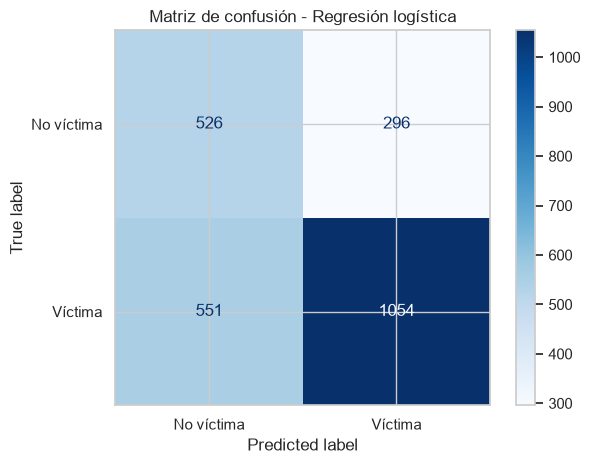

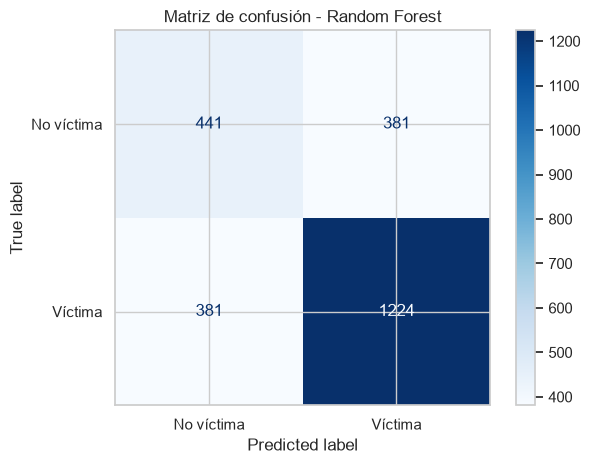

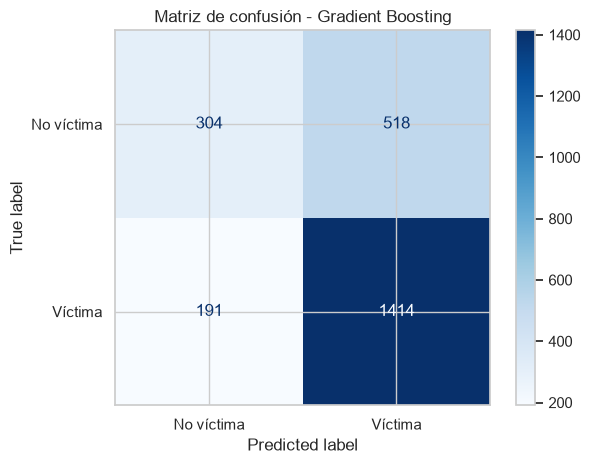

In [85]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for nombre, pipeline in pipelines.items():

    y_pred = pipeline.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["No víctima", "Víctima"],
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"Matriz de confusión - {nombre}")
    plt.tight_layout()
    plt.show()

La evaluación inicial de los tres modelos de aprendizaje automático permitió identificar diferencias en su capacidad para clasificar las experiencias de victimización digital a partir de variables sociodemográficas, características de experiencia tecnológica e índices de percepción y conocimiento sobre seguridad digital. Los resultados evidencian que los modelos presentan comportamientos diferenciados, por lo que la selección del algoritmo depende de las métricas que se consideren prioritarias para el problema analítico.

Gradient Boosting obtuvo el mejor desempeño general en términos de accuracy (70,79 %), recall (88,10 %) y F1-score (0,7995). Este resultado indica una mayor capacidad para identificar a las personas clasificadas como víctimas de experiencias de victimización digital. No obstante, su matriz de confusión registró 518 falsos positivos, lo que evidencia una mayor tendencia a clasificar como víctimas a personas que pertenecen a la clase de no victimización.

Por su parte, Random Forest presentó un comportamiento más equilibrado entre precision y recall, ambos con un valor de 76,26 %, y alcanzó el mayor ROC-AUC (0,7169). Estos resultados muestran una capacidad de discriminación ligeramente superior a la de los otros modelos según esta métrica. La regresión logística, aunque obtuvo la mayor precision (78,07 %), presentó el menor recall (65,67 %), lo que refleja una menor capacidad para identificar los casos positivos.

Los resultados preliminares sugieren que Gradient Boosting es el modelo más favorable cuando se prioriza la identificación de personas que reportaron experiencias de victimización digital, mientras que Random Forest ofrece un equilibrio más uniforme entre las principales métricas de clasificación. Sin embargo, las diferencias observadas corresponden a una única partición de entrenamiento y prueba, por lo que todavía no constituyen evidencia suficiente para establecer la superioridad estadística de alguno de los algoritmos.

Esta primera evaluación demuestra la utilidad de aplicar diferentes técnicas de aprendizaje automático para analizar patrones asociados con la victimización digital. También evidencia la importancia de considerar conjuntamente las métricas de desempeño y los errores de clasificación, en lugar de seleccionar un modelo exclusivamente por su exactitud. Estos hallazgos constituyen la base para una evaluación posterior mediante validación cruzada y pruebas estadísticas que permitan examinar la estabilidad y significancia de las diferencias entre los clasificadores.

### 5.7 Validación cruzada de los modelos de clasificación

Con el propósito de evaluar la estabilidad del desempeño de los clasificadores, se aplica validación cruzada estratificada de cinco particiones (Stratified K-Fold). Este procedimiento permite entrenar y evaluar cada modelo en diferentes subconjuntos de los datos de entrenamiento, manteniendo la proporción de las clases de la variable objetivo. Se calculan las métricas de accuracy, precision, recall, F1-score y ROC-AUC para cada partición. Posteriormente, se analizan sus valores promedio y desviaciones estándar para comparar el desempeño y la variabilidad de los algoritmos.

In [86]:
# Importar herramientas
import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold, cross_validate

# Configurar validación cruzada de cinco particiones
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Definir las métricas
metricas = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Almacenar resultados
resultados_cv = []

for nombre, pipeline in pipelines.items():

    puntuaciones = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=metricas,
        n_jobs=-1,
        return_train_score=False
    )

    for metrica in metricas:

        resultados_cv.append({
            "Modelo": nombre,
            "Métrica": metrica,
            "Media": puntuaciones[f"test_{metrica}"].mean(),
            "Desviación estándar": puntuaciones[f"test_{metrica}"].std()
        })

# Crear tabla comparativa
tabla_cv = pd.DataFrame(resultados_cv)

display(tabla_cv.round(4))

,Modelo,Métrica,Media,Desviación estándar
0,Regresión logística,accuracy,0.6598,0.0077
1,Regresión logística,precision,0.7904,0.0094
2,Regresión logística,recall,0.6607,0.0096
3,Regresión logística,f1,0.7197,0.0066
4,Regresión logística,roc_auc,0.7191,0.0073
5,Random Forest,accuracy,0.6936,0.0104
6,Random Forest,precision,0.7699,0.0087
7,Random Forest,recall,0.7653,0.0075
8,Random Forest,f1,0.7676,0.0077
9,Random Forest,roc_auc,0.7217,0.0113


Los resultados de la validación cruzada permiten examinar la consistencia de los modelos frente a diferentes particiones de los datos de entrenamiento. Un desempeño promedio elevado acompañado de una desviación estándar reducida representa un comportamiento más estable. Esta comparación complementa la evaluación realizada sobre el conjunto de prueba y permite identificar posibles variaciones en la capacidad predictiva de los algoritmos.

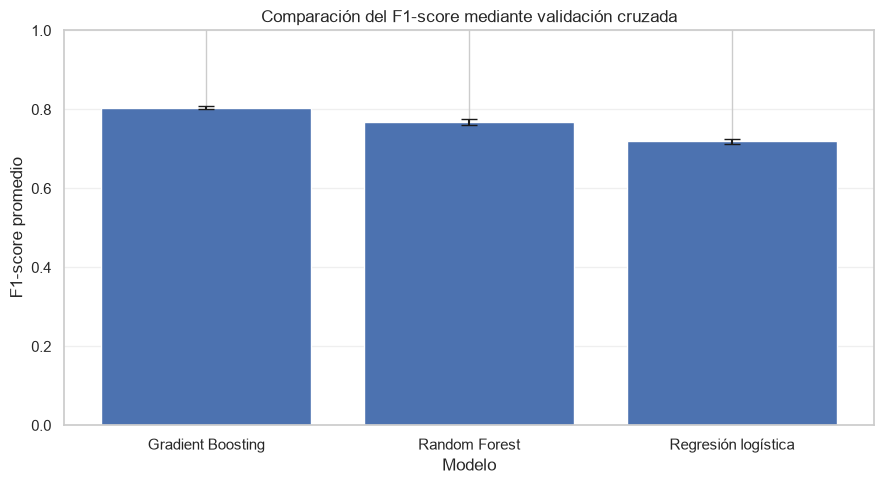

In [88]:
import matplotlib.pyplot as plt

# Filtrar resultados de F1-score
resultados_f1 = tabla_cv[
    tabla_cv["Métrica"] == "f1"
].copy()

# Ordenar modelos por promedio
resultados_f1 = resultados_f1.sort_values(
    "Media",
    ascending=False
)

# Construir gráfica
plt.figure(figsize=(9, 5))

plt.bar(
    resultados_f1["Modelo"],
    resultados_f1["Media"],
    yerr=resultados_f1["Desviación estándar"],
    capsize=6
)

plt.title("Comparación del F1-score mediante validación cruzada")
plt.ylabel("F1-score promedio")
plt.xlabel("Modelo")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 5.8 Comparación estadística del desempeño de los clasificadores

Para determinar si las diferencias observadas entre los modelos son estadísticamente significativas, se aplica la prueba no paramétrica de Friedman sobre los resultados obtenidos en las cinco particiones de validación cruzada. Esta prueba permite realizar una comparación global de los clasificadores bajo las mismas particiones. Cuando se identifican diferencias globales, se realizan comparaciones por pares mediante la prueba de rangos con signo de Wilcoxon, incorporando el ajuste de Holm para controlar el error asociado con las comparaciones múltiples.

In [89]:
from scipy.stats import friedmanchisquare, wilcoxon
from itertools import combinations
from statsmodels.stats.multitest import multipletests

# Recuperar los resultados individuales de F1 de cada partición
resultados_friedman = {}

for nombre, pipeline in pipelines.items():

    puntuaciones = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=-1
    )

    resultados_friedman[nombre] = puntuaciones["test_score"]

# Organizar los resultados
nombres_modelos = list(resultados_friedman.keys())

# Prueba global de Friedman
estadistico, p_valor = friedmanchisquare(
    *[resultados_friedman[nombre] for nombre in nombres_modelos]
)

print("Prueba de Friedman")
print("Estadístico:", round(estadistico, 4))
print("Valor p:", round(p_valor, 4))

if p_valor < 0.05:
    print("Se identifican diferencias estadísticamente significativas.")
else:
    print("No se identifican diferencias estadísticamente significativas.")

# Comparaciones por pares mediante Wilcoxon
comparaciones = []

for modelo_a, modelo_b in combinations(nombres_modelos, 2):

    estadistico_w, p_w = wilcoxon(
        resultados_friedman[modelo_a],
        resultados_friedman[modelo_b]
    )

    comparaciones.append({
        "Modelo A": modelo_a,
        "Modelo B": modelo_b,
        "Estadístico": estadistico_w,
        "p sin ajustar": p_w
    })

tabla_wilcoxon = pd.DataFrame(comparaciones)

# Ajuste de Holm
rechaza, p_ajustados, _, _ = multipletests(
    tabla_wilcoxon["p sin ajustar"],
    alpha=0.05,
    method="holm"
)

tabla_wilcoxon["p ajustado Holm"] = p_ajustados
tabla_wilcoxon["Significativo"] = rechaza

display(tabla_wilcoxon.round(4))

Prueba de Friedman
Estadístico: 10.0
Valor p: 0.0067
Se identifican diferencias estadísticamente significativas.


,Modelo A,Modelo B,Estadístico,p sin ajustar,p ajustado Holm,Significativo
0,Regresión logística,Random Forest,0.0,0.0625,0.1875,False
1,Regresión logística,Gradient Boosting,0.0,0.0625,0.1875,False
2,Random Forest,Gradient Boosting,0.0,0.0625,0.1875,False


### Conclusiones de la validación cruzada y comparación estadística

La validación cruzada estratificada de cinco particiones permitió examinar la estabilidad del desempeño de los tres modelos de clasificación. Los resultados muestran que Gradient Boosting obtuvo el mejor comportamiento promedio, con un accuracy de 71,47 %, recall de 88,76 %, F1-score de 0,8044 y ROC-AUC de 0,7274. Este modelo presentó además una desviación estándar de 0,0046 en el F1-score, lo que evidencia una variabilidad reducida entre las particiones evaluadas.

Random Forest alcanzó un F1-score promedio de 0,7676 y un ROC-AUC de 0,7217, con un comportamiento equilibrado entre precision (76,99 %) y recall (76,53 %). Por su parte, la regresión logística obtuvo la mayor precision (79,04 %), aunque presentó un menor desempeño en las métricas de accuracy, recall y F1-score.

La prueba global de Friedman identificó diferencias estadísticamente significativas entre los clasificadores (estadístico = 10,0; p = 0,0067). No obstante, las comparaciones post hoc mediante Wilcoxon, con ajuste de Holm, no evidenciaron diferencias estadísticamente significativas entre los pares de modelos (p ajustado = 0,1875). Este resultado debe interpretarse considerando el número reducido de particiones y la dependencia entre los resultados de la validación cruzada.

Gradient Boosting se perfila como el clasificador con mejor desempeño predictivo promedio, particularmente por su capacidad para identificar los casos positivos y mantener un F1-score superior. Sin embargo, la evidencia estadística obtenida no permite afirmar que sea significativamente superior a los otros algoritmos en las comparaciones individuales. Por ello, se requiere complementar el análisis mediante la comparación de las predicciones sobre el conjunto de prueba y la estimación de intervalos de confianza del 95 %, antes de establecer una selección definitiva del modelo.

### 5.9 Comparación pareada de los clasificadores mediante la prueba de McNemar

Con el propósito de complementar la comparación realizada mediante validación cruzada, se aplica la prueba de McNemar sobre las predicciones obtenidas en el conjunto de prueba. Esta prueba permite comparar dos clasificadores evaluados sobre las mismas observaciones, considerando los casos en los que sus predicciones difieren.

Se realizan comparaciones por pares entre regresión logística, Random Forest y Gradient Boosting. Para controlar el error asociado con las comparaciones múltiples, se aplica el ajuste de Holm sobre los valores p obtenidos.

In [90]:
import numpy as np
import pandas as pd

from itertools import combinations
from scipy.stats import binomtest
from statsmodels.stats.multitest import multipletests

# Obtener predicciones sobre el mismo conjunto de prueba
predicciones = {}

for nombre, pipeline in pipelines.items():
    predicciones[nombre] = pipeline.predict(X_test)

# Comparaciones por pares
comparaciones_mcnemar = []

for modelo_a, modelo_b in combinations(predicciones.keys(), 2):

    pred_a = predicciones[modelo_a]
    pred_b = predicciones[modelo_b]

    # Identificar aciertos y errores de cada modelo
    acierto_a = pred_a == y_test.to_numpy()
    acierto_b = pred_b == y_test.to_numpy()

    # Casos discordantes
    b = np.sum(acierto_a & ~acierto_b)
    c = np.sum(~acierto_a & acierto_b)

    # Prueba binomial exacta equivalente a McNemar
    resultado = binomtest(
        min(b, c),
        n=b + c,
        p=0.5,
        alternative="two-sided"
    )

    comparaciones_mcnemar.append({
        "Modelo A": modelo_a,
        "Modelo B": modelo_b,
        "Aciertos solo A": b,
        "Aciertos solo B": c,
        "Casos discordantes": b + c,
        "p sin ajustar": resultado.pvalue
    })

tabla_mcnemar = pd.DataFrame(comparaciones_mcnemar)

# Ajuste de Holm
rechaza, p_ajustados, _, _ = multipletests(
    tabla_mcnemar["p sin ajustar"],
    alpha=0.05,
    method="holm"
)

tabla_mcnemar["p ajustado Holm"] = p_ajustados
tabla_mcnemar["Significativo"] = rechaza

display(tabla_mcnemar.round(4))

,Modelo A,Modelo B,Aciertos solo A,Aciertos solo B,Casos discordantes,p sin ajustar,p ajustado Holm,Significativo
0,Regresión logística,Random Forest,184,269,453,0.0001,0.0002,True
1,Regresión logística,Gradient Boosting,238,376,614,0.0000,0.0000,True
2,Random Forest,Gradient Boosting,147,200,347,0.0052,0.0052,True


La comparación pareada mediante la prueba de McNemar permitió identificar diferencias estadísticamente significativas entre los tres clasificadores evaluados sobre el mismo conjunto de prueba. Los resultados, después de aplicar el ajuste de Holm, evidenciaron diferencias significativas entre regresión logística y Random Forest (p = 0,0002), regresión logística y Gradient Boosting (p menor que 0,0001), así como entre Random Forest y Gradient Boosting (p = 0,0052).

En las tres comparaciones, el segundo clasificador presentó una mayor cantidad de aciertos exclusivos respecto al primero. En particular, Gradient Boosting obtuvo 376 aciertos exclusivos frente a regresión logística y 200 frente a Random Forest, mientras que Random Forest registró 269 aciertos exclusivos frente a regresión logística.

Estos resultados proporcionan evidencia de diferencias en los patrones de clasificación de los modelos sobre las mismas observaciones. En conjunto con las métricas de desempeño y los resultados de validación cruzada, Gradient Boosting mantiene el comportamiento predictivo más favorable, especialmente por su mayor capacidad para identificar los casos positivos. No obstante, esta conclusión debe complementarse con la estimación de intervalos de confianza para cuantificar la incertidumbre de las métricas y las diferencias observadas.

### 5.10 Estimación de intervalos de confianza del 95 %

Para cuantificar la incertidumbre de las métricas de desempeño de los clasificadores, se utiliza el método bootstrap sobre el conjunto de prueba. Este procedimiento genera múltiples muestras mediante remuestreo con reemplazo y permite estimar intervalos de confianza del 95 % para accuracy, precision, recall, F1-score y ROC-AUC. Los intervalos obtenidos complementan las métricas puntuales y permiten examinar la precisión de las estimaciones de desempeño de cada algoritmo.

In [92]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Configuración del bootstrap
B = 2000
rng = np.random.default_rng(42)

resultados_ic = []

# Funciones de evaluación
def calcular_metricas(yt, yp, prob):

    return {
        "Accuracy": accuracy_score(yt, yp),
        "Precision": precision_score(yt, yp, zero_division=0),
        "Recall": recall_score(yt, yp, zero_division=0),
        "F1-score": f1_score(yt, yp, zero_division=0),
        "ROC-AUC": roc_auc_score(yt, prob)
    }

# Variable real
y_real = y_test.to_numpy()

for nombre, pipeline in pipelines.items():

    # Predicciones del modelo
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Calcular métricas originales
    metricas_originales = calcular_metricas(
        y_real, y_pred, y_prob
    )

    # Almacenar resultados bootstrap
    valores_bootstrap = {
        metrica: [] for metrica in metricas_originales
    }

    # Remuestreo con reemplazo
    for _ in range(B):

        indices = rng.choice(
            len(y_real),
            size=len(y_real),
            replace=True
        )

        yt = y_real[indices]
        yp = y_pred[indices]
        prob = y_prob[indices]

        metricas_muestra = calcular_metricas(
            yt, yp, prob
        ) if len(np.unique(yt)) == 2 else {
            "Accuracy": accuracy_score(yt, yp),
            "Precision": precision_score(yt, yp, zero_division=0),
            "Recall": recall_score(yt, yp, zero_division=0),
            "F1-score": f1_score(yt, yp, zero_division=0)
        }

        for metrica, valor in metricas_muestra.items():
            valores_bootstrap[metrica].append(valor)

    # Calcular intervalos de confianza
    for metrica, valores in valores_bootstrap.items():

        valores = np.array(valores)

        resultados_ic.append({
            "Modelo": nombre,
            "Métrica": metrica,
            "Estimación": metricas_originales[metrica],
            "IC 95 % inferior": np.percentile(valores, 2.5),
            "IC 95 % superior": np.percentile(valores, 97.5)
        })

# Crear tabla de resultados
tabla_ic = pd.DataFrame(resultados_ic)

display(tabla_ic.round(4))

,Modelo,Métrica,Estimación,IC 95 % inferior,IC 95 % superior
0,Regresión logística,Accuracy,0.6510,0.6329,0.6704
1,Regresión logística,Precision,0.7807,0.7596,0.8021
2,Regresión logística,Recall,0.6567,0.6339,0.6812
3,Regresión logística,F1-score,0.7134,0.6951,0.7321
4,Regresión logística,ROC-AUC,0.6994,0.6776,0.7224
5,Random Forest,Accuracy,0.6860,0.6683,0.7042
6,Random Forest,Precision,0.7626,0.7415,0.7830
7,Random Forest,Recall,0.7626,0.7430,0.7821
8,Random Forest,F1-score,0.7626,0.7462,0.7782
9,Random Forest,ROC-AUC,0.7169,0.6957,0.7374


La estimación de intervalos de confianza mediante bootstrap permitió cuantificar la incertidumbre de las métricas de desempeño de los tres clasificadores sobre el conjunto de prueba. Los resultados muestran que Gradient Boosting alcanzó el mayor accuracy (0,7079; IC 95 %: 0,6893–0,7272), recall (0,8810; IC 95 %: 0,8637–0,8966) y F1-score (0,7995; IC 95 %: 0,7848–0,8146). Estos resultados respaldan su capacidad para identificar los casos positivos y mantener un equilibrio favorable entre precisión y sensibilidad.

Random Forest obtuvo un F1-score de 0,7626 (IC 95 %: 0,7462–0,7782) y el mayor ROC-AUC (0,7169; IC 95 %: 0,6957–0,7374), mientras que la regresión logística presentó la mayor precision (0,7807; IC 95 %: 0,7596–0,8021), aunque registró menores resultados en recall y F1-score.

Los intervalos de confianza del F1-score muestran una separación entre los tres clasificadores, lo que respalda las diferencias observadas en su desempeño puntual. No obstante, estos intervalos corresponden a estimaciones individuales y no constituyen por sí mismos una prueba formal de las diferencias entre modelos. Por consiguiente, su interpretación se complementa con los resultados de las pruebas de comparación pareada y de validación cruzada.

Los resultados mantienen a Gradient Boosting como el candidato con mejor desempeño predictivo para identificar experiencias de victimización digital, especialmente cuando se prioriza reducir los casos de víctimas que no son identificados por el clasificador.

### 5.11 Comparación de las diferencias de F1-score mediante bootstrap

Se estiman intervalos de confianza del 95 % para las diferencias de F1-score entre los tres clasificadores mediante bootstrap pareado. El procedimiento utiliza las mismas observaciones remuestreadas para cada modelo, lo que permite comparar directamente sus resultados y conservar la correspondencia entre las predicciones. Se realizan 2.000 iteraciones de remuestreo con reemplazo y se calculan las diferencias de F1-score para cada par de clasificadores. Se considera que existe evidencia de una diferencia en el desempeño cuando el intervalo de confianza del 95 % de la diferencia no contiene el valor cero.

In [93]:
import numpy as np
import pandas as pd

from sklearn.metrics import f1_score
from itertools import combinations

# Configuración del bootstrap
B = 2000
rng = np.random.default_rng(42)

# Obtener predicciones de cada modelo
predicciones = {}

for nombre, pipeline in pipelines.items():
    predicciones[nombre] = pipeline.predict(X_test)

# Preparar variable real
y_real = y_test.to_numpy()

# Comparaciones por pares
resultados_diferencias = []

for modelo_a, modelo_b in combinations(predicciones.keys(), 2):

    pred_a = predicciones[modelo_a]
    pred_b = predicciones[modelo_b]

    diferencias = []

    # Bootstrap pareado
    for _ in range(B):

        indices = rng.choice(
            len(y_real),
            size=len(y_real),
            replace=True
        )

        yt = y_real[indices]
        pa = pred_a[indices]
        pb = pred_b[indices]

        f1_a = f1_score(yt, pa, zero_division=0)
        f1_b = f1_score(yt, pb, zero_division=0)

        # Diferencia: modelo A menos modelo B
        diferencias.append(f1_a - f1_b)

    diferencias = np.array(diferencias)

    # F1-score puntual de cada modelo
    f1_original_a = f1_score(
        y_real, pred_a, zero_division=0
    )

    f1_original_b = f1_score(
        y_real, pred_b, zero_division=0
    )

    diferencia_original = f1_original_a - f1_original_b

    # Intervalo de confianza del 95 %
    limite_inferior = np.percentile(diferencias, 2.5)
    limite_superior = np.percentile(diferencias, 97.5)

    resultados_diferencias.append({
        "Modelo A": modelo_a,
        "Modelo B": modelo_b,
        "F1 modelo A": f1_original_a,
        "F1 modelo B": f1_original_b,
        "Diferencia A-B": diferencia_original,
        "IC 95 % inferior": limite_inferior,
        "IC 95 % superior": limite_superior,
        "Incluye cero": (
            limite_inferior <= 0 <= limite_superior
        )
    })

tabla_diferencias = pd.DataFrame(resultados_diferencias)

display(tabla_diferencias.round(4))

,Modelo A,Modelo B,F1 modelo A,F1 modelo B,Diferencia A-B,IC 95 % inferior,IC 95 % superior,Incluye cero
0,Regresión logística,Random Forest,0.7134,0.7626,-0.0492,-0.0645,-0.0341,False
1,Regresión logística,Gradient Boosting,0.7134,0.7995,-0.0862,-0.1027,-0.0708,False
2,Random Forest,Gradient Boosting,0.7626,0.7995,-0.0369,-0.0489,-0.0257,False


Se representa gráficamente la diferencia de F1-score entre cada par de clasificadores y sus respectivos intervalos de confianza del 95 %. La línea vertical en cero representa la ausencia de diferencia entre los modelos. Esta visualización facilita identificar qué comparaciones presentan evidencia de diferencias en el desempeño predictivo.

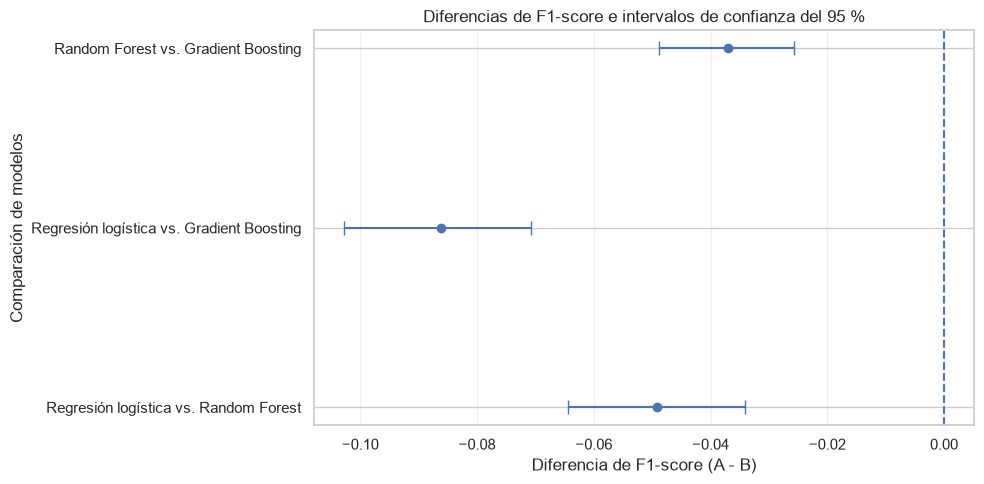

In [94]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

nombres = (
    tabla_diferencias["Modelo A"]
    + " vs. "
    + tabla_diferencias["Modelo B"]
)

diferencias = tabla_diferencias["Diferencia A-B"]

errores_inferiores = (
    diferencias - tabla_diferencias["IC 95 % inferior"]
)

errores_superiores = (
    tabla_diferencias["IC 95 % superior"] - diferencias
)

plt.errorbar(
    diferencias,
    nombres,
    xerr=[errores_inferiores, errores_superiores],
    fmt="o",
    capsize=5
)

plt.axvline(0, linestyle="--")
plt.xlabel("Diferencia de F1-score (A - B)")
plt.ylabel("Comparación de modelos")
plt.title("Diferencias de F1-score e intervalos de confianza del 95 %")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

La comparación pareada mediante bootstrap permitió estimar las diferencias de F1-score entre los tres clasificadores y sus respectivos intervalos de confianza del 95 %. Los resultados evidenciaron que las tres diferencias estimadas fueron negativas y que ninguno de los intervalos incluyó el valor cero.

En la comparación entre regresión logística y Random Forest se obtuvo una diferencia de -0,0492 (IC 95 %: -0,0645 a -0,0341), lo que favorece a Random Forest. Entre regresión logística y Gradient Boosting, la diferencia fue de -0,0862 (IC 95 %: -0,1027 a -0,0708), evidenciando una mayor diferencia favorable a Gradient Boosting. Finalmente, la comparación entre Random Forest y Gradient Boosting presentó una diferencia de -0,0369 (IC 95 %: -0,0489 a -0,0257), también favorable al segundo clasificador.

Estos resultados indican que Gradient Boosting obtuvo un F1-score superior al de los otros dos modelos en el conjunto de prueba, mientras que Random Forest también superó a la regresión logística. La ausencia del cero en los tres intervalos respalda la existencia de diferencias en el desempeño estimado mediante el procedimiento bootstrap. No obstante, estos intervalos son individuales y no incorporan un ajuste por las tres comparaciones simultáneas, por lo que deben interpretarse como evidencia complementaria y no como una prueba confirmatoria independiente.

El análisis refuerza la selección de Gradient Boosting como el modelo con mejor desempeño en la clasificación de experiencias de victimización digital, particularmente por su mayor F1-score y su capacidad para identificar los casos positivos.

### Evaluación de las limitaciones de la técnica aplicada

La aplicación de modelos de aprendizaje automático supervisado para clasificar experiencias de victimización digital permite identificar patrones y evaluar la capacidad predictiva de diferentes algoritmos. Sin embargo, esta técnica presenta supuestos y restricciones que deben considerarse al interpretar los resultados.

En primer lugar, se supone que los datos utilizados representan adecuadamente la población y que las relaciones identificadas entre las variables predictoras y la variable objetivo se mantienen en observaciones no utilizadas durante el entrenamiento. Este supuesto puede no cumplirse completamente, debido a diferencias sociodemográficas, contextuales y territoriales entre los participantes.

En segundo lugar, la calidad de la clasificación depende de la definición y confiabilidad de la variable objetivo. En este estudio, la victimización digital se construyó a partir de nueve indicadores de la batería Q7. Esta operacionalización permite representar las experiencias reportadas mediante una variable binaria, pero reduce la diversidad de situaciones a dos categorías y depende de la información proporcionada por los encuestados.

Asimismo, los datos presentan valores faltantes en algunos predictores, especialmente en la variable Age, que registra 3.026 valores ausentes. El tratamiento de estos valores mediante el proceso de preparación de datos puede introducir incertidumbre y afectar las estimaciones de los modelos. También debe considerarse que la distribución de las clases no es equilibrada: aproximadamente el 66 % de los registros corresponde a la categoría de victimización y el 34 % a la categoría de no victimización.

Otra limitación corresponde a la dependencia de los resultados respecto a la partición de los datos, los hiperparámetros y los procedimientos de validación. Aunque se aplicó validación cruzada estratificada de cinco particiones, esta evaluación no garantiza que el comportamiento de los modelos se mantenga en poblaciones o contextos diferentes.

Finalmente, las métricas de desempeño permiten cuantificar la capacidad predictiva de los clasificadores, pero no explican por sí mismas las causas de la victimización digital ni identifican los mecanismos sociales, tecnológicos o conductuales que originan estas experiencias.

### Limitaciones de la técnica aplicada

La aplicación de aprendizaje automático supervisado permitió comparar tres algoritmos de clasificación e identificar diferencias en su capacidad para predecir experiencias de victimización digital. No obstante, los resultados deben interpretarse considerando las limitaciones propias de la técnica y las características de los datos utilizados.

Entre las principales restricciones se encuentran la dependencia de la calidad de la variable objetivo, construida a partir de nueve indicadores de autorreporte; la presencia de valores faltantes en los predictores; el desequilibrio en la distribución de las clases y la ausencia de una validación externa que permita comprobar la generalización de los modelos a otras poblaciones y contextos. Adicionalmente, las puntuaciones obtenidas mediante validación cruzada presentan dependencia entre particiones, lo que limita la interpretación de las pruebas estadísticas aplicadas con cinco pliegues.

Aunque Gradient Boosting presentó el mejor desempeño predictivo según el F1-score y el recall, estos resultados no permiten establecer relaciones causales ni explicar los mecanismos que originan la victimización digital. Tampoco garantizan que las predicciones sean igualmente precisas en contextos diferentes al de los datos analizados.

Por consiguiente, los modelos deben entenderse como herramientas de apoyo para identificar patrones de clasificación y no como mecanismos definitivos de explicación o predicción universal. Para ampliar el alcance del análisis sería necesario incorporar validaciones externas, examinar la contribución de las variables mediante técnicas de interpretabilidad y considerar información contextual que permita comprender mejor los fenómenos asociados con la seguridad digital.